Cell 1 — Environment, paths, and prior-result inventory

In [9]:
# ============================================================
# Notebook 9
# Promoter Pathway and Mediation Validation
# ============================================================

from __future__ import annotations

import gc
import json
import os
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Mount Google Drive
# ------------------------------------------------------------

from google.colab import drive

drive.mount(
    "/content/drive"
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/algoverse/dnabert"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "outputs"
)

NOTEBOOK9_DIR = (
    OUTPUT_ROOT
    / "promoter_pathway_mediation_validation"
)

NOTEBOOK9_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# Notebook 8 outputs
NOTEBOOK8_DIR = (
    OUTPUT_ROOT
    / "promoter_mlp_subspace_causal_interventions"
)


print("\nProject root:")
print(PROJECT_ROOT)

print("\nOutput root:")
print(OUTPUT_ROOT)

print("\nNotebook 8 directory:")
print(NOTEBOOK8_DIR)

print("\nNotebook 9 directory:")
print(NOTEBOOK9_DIR)


# ------------------------------------------------------------
# Confirm essential Notebook 8 files
# ------------------------------------------------------------

required_notebook8_files = {
    "finalized_subspaces": (
        NOTEBOOK8_DIR
        / "finalized_intervention_subspaces.npz"
    ),
    "clean_cohort": (
        NOTEBOOK8_DIR
        / "clean_source_cohort.csv"
    ),
    "full_results": (
        NOTEBOOK8_DIR
        / "full_subspace_intervention_results.pkl"
    ),
    "causal_summary": (
        NOTEBOOK8_DIR
        / "causal_intervention_summary.csv"
    ),
    "class_targets": (
        NOTEBOOK8_DIR
        / "class_coordinate_targets.npz"
    ),
}


print("\n" + "=" * 80)
print("Required Notebook 8 files")
print("=" * 80)

missing_notebook8_files = []

for name, path in (
    required_notebook8_files.items()
):
    exists = path.exists()

    print(
        f"{name:24s}",
        "FOUND" if exists else "MISSING",
        path,
    )

    if not exists:
        missing_notebook8_files.append(
            str(path)
        )


if missing_notebook8_files:
    raise FileNotFoundError(
        "Notebook 9 cannot begin because some "
        "required Notebook 8 files are missing:\n"
        + "\n".join(
            missing_notebook8_files
        )
    )


# ------------------------------------------------------------
# Inventory all previous output directories
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("Previous experiment directories")
print("=" * 80)

output_directories = sorted(
    [
        path
        for path in OUTPUT_ROOT.iterdir()
        if path.is_dir()
    ],
    key=lambda path: path.name.lower(),
)


for directory in output_directories:
    number_of_files = sum(
        1
        for path in directory.rglob("*")
        if path.is_file()
    )

    print(
        f"{directory.name:55s}",
        f"{number_of_files:4d} files",
    )


# ------------------------------------------------------------
# Search earlier outputs for localization and patching files
# ------------------------------------------------------------

SEARCH_TERMS = [
    "local",
    "component",
    "ablation",
    "attention",
    "head",
    "mlp",
    "patch",
    "rescue",
    "mediat",
    "layer",
]


candidate_prior_files = []

for path in OUTPUT_ROOT.rglob("*"):
    if not path.is_file():
        continue

    # Exclude Notebook 8 and the new Notebook 9 directory.
    if NOTEBOOK8_DIR in path.parents:
        continue

    if NOTEBOOK9_DIR in path.parents:
        continue

    lower_name = path.name.lower()

    matched_terms = [
        term
        for term in SEARCH_TERMS
        if term in lower_name
    ]

    if matched_terms:
        candidate_prior_files.append(
            {
                "relative_path": str(
                    path.relative_to(
                        OUTPUT_ROOT
                    )
                ),
                "filename": path.name,
                "suffix": path.suffix.lower(),
                "size_kb": round(
                    path.stat().st_size
                    / 1024.0,
                    2,
                ),
                "matched_terms": ", ".join(
                    matched_terms
                ),
            }
        )


candidate_prior_files = pd.DataFrame(
    candidate_prior_files
)


if len(candidate_prior_files) > 0:
    candidate_prior_files = (
        candidate_prior_files
        .sort_values(
            [
                "relative_path",
                "filename",
            ]
        )
        .reset_index(drop=True)
    )


print("\n" + "=" * 80)
print("Candidate localization, ablation, and patching files")
print("=" * 80)

print(
    "Number of candidate files:",
    len(candidate_prior_files),
)

display(
    candidate_prior_files
)


# ------------------------------------------------------------
# Preview structured files
# ------------------------------------------------------------

preview_rows = []

preview_suffixes = {
    ".csv",
    ".json",
    ".pkl",
    ".joblib",
    ".npz",
}


for row in candidate_prior_files.itertuples():
    relative_path = Path(
        row.relative_path
    )

    full_path = (
        OUTPUT_ROOT
        / relative_path
    )

    if full_path.suffix.lower() not in preview_suffixes:
        continue

    preview_record = {
        "relative_path": str(
            relative_path
        ),
        "file_type": (
            full_path.suffix.lower()
        ),
        "shape_or_keys": None,
        "columns_or_notes": None,
        "load_error": None,
    }

    try:
        suffix = full_path.suffix.lower()

        if suffix == ".csv":
            table = pd.read_csv(
                full_path
            )

            preview_record[
                "shape_or_keys"
            ] = str(
                table.shape
            )

            preview_record[
                "columns_or_notes"
            ] = ", ".join(
                table.columns.astype(str)
            )

        elif suffix == ".json":
            with open(
                full_path,
                "r",
                encoding="utf-8",
            ) as file:
                data = json.load(file)

            if isinstance(data, dict):
                preview_record[
                    "shape_or_keys"
                ] = (
                    f"{len(data)} keys"
                )

                preview_record[
                    "columns_or_notes"
                ] = ", ".join(
                    map(
                        str,
                        list(data.keys())[:30],
                    )
                )

            else:
                preview_record[
                    "shape_or_keys"
                ] = str(
                    type(data)
                )

                preview_record[
                    "columns_or_notes"
                ] = (
                    f"length={len(data)}"
                    if hasattr(data, "__len__")
                    else None
                )

        elif suffix in {
            ".pkl",
            ".joblib",
        }:
            if suffix == ".joblib":
                data = joblib.load(
                    full_path
                )
            else:
                data = pd.read_pickle(
                    full_path
                )

            preview_record[
                "shape_or_keys"
            ] = str(
                getattr(
                    data,
                    "shape",
                    type(data),
                )
            )

            if isinstance(
                data,
                pd.DataFrame,
            ):
                preview_record[
                    "columns_or_notes"
                ] = ", ".join(
                    data.columns.astype(str)
                )

            elif isinstance(data, dict):
                preview_record[
                    "columns_or_notes"
                ] = ", ".join(
                    map(
                        str,
                        list(data.keys())[:30],
                    )
                )

            else:
                preview_record[
                    "columns_or_notes"
                ] = repr(
                    data
                )[:300]

        elif suffix == ".npz":
            archive = np.load(
                full_path,
                allow_pickle=True,
            )

            keys = list(
                archive.files
            )

            key_shapes = []

            for key in keys:
                value = archive[key]

                key_shapes.append(
                    f"{key}:{value.shape}"
                )

            preview_record[
                "shape_or_keys"
            ] = (
                f"{len(keys)} arrays"
            )

            preview_record[
                "columns_or_notes"
            ] = "; ".join(
                key_shapes
            )

    except Exception as error:
        preview_record[
            "load_error"
        ] = (
            f"{type(error).__name__}: "
            f"{error}"
        )

    preview_rows.append(
        preview_record
    )


structured_file_inventory = pd.DataFrame(
    preview_rows
)


print("\n" + "=" * 80)
print("Structured-file previews")
print("=" * 80)

display(
    structured_file_inventory
)


# ------------------------------------------------------------
# Save inventory for reproducibility
# ------------------------------------------------------------

CANDIDATE_FILE_INVENTORY_PATH = (
    NOTEBOOK9_DIR
    / "candidate_prior_result_files.csv"
)

STRUCTURED_FILE_INVENTORY_PATH = (
    NOTEBOOK9_DIR
    / "structured_prior_file_inventory.csv"
)


candidate_prior_files.to_csv(
    CANDIDATE_FILE_INVENTORY_PATH,
    index=False,
)

structured_file_inventory.to_csv(
    STRUCTURED_FILE_INVENTORY_PATH,
    index=False,
)


inventory_summary = {
    "project_root": str(
        PROJECT_ROOT
    ),
    "output_root": str(
        OUTPUT_ROOT
    ),
    "notebook8_dir": str(
        NOTEBOOK8_DIR
    ),
    "notebook9_dir": str(
        NOTEBOOK9_DIR
    ),
    "number_of_output_directories": int(
        len(output_directories)
    ),
    "number_of_candidate_prior_files": int(
        len(candidate_prior_files)
    ),
    "number_of_structured_files_previewed": int(
        len(structured_file_inventory)
    ),
    "search_terms": SEARCH_TERMS,
}


INVENTORY_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "prior_result_inventory_summary.json"
)

with open(
    INVENTORY_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        inventory_summary,
        file,
        indent=2,
    )


print("\nSaved:")
print(CANDIDATE_FILE_INVENTORY_PATH)
print(STRUCTURED_FILE_INVENTORY_PATH)
print(INVENTORY_SUMMARY_PATH)


print(
    "\nCell 1 complete. Prior localization, ablation, "
    "and activation-patching outputs have been inventoried."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4

Project root:
/content/drive/MyDrive/algoverse/dnabert

Output root:
/content/drive/MyDrive/algoverse/dnabert/outputs

Notebook 8 directory:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions

Notebook 9 directory:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation

Required Notebook 8 files
finalized_subspaces      FOUND /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/finalized_intervention_subspaces.npz
clean_cohort             FOUND /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/clean_source_cohort.csv
full_results             FOUND /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/full_subspace_intervention_results.pkl
caus

,relative_path,filename,suffix,size_kb,matched_terms
0,gc_controlled_interventions/gc_intervention_mlp_direction_contrasts.csv,gc_intervention_mlp_direction_contrasts.csv,.csv,318.60,mlp
1,gc_controlled_interventions/gc_intervention_mlp_direction_scores.csv,gc_intervention_mlp_direction_scores.csv,.csv,5745.28,mlp
2,gc_controlled_interventions/gc_intervention_mlp_direction_summary.csv,gc_intervention_mlp_direction_summary.csv,.csv,0.65,mlp
3,gc_controlled_interventions/gc_unique_sequence_layer1_mlp_index.csv,gc_unique_sequence_layer1_mlp_index.csv,.csv,1313.56,"mlp, layer"
4,gc_controlled_interventions/gc_unique_sequence_layer1_mlp_representations.npz,gc_unique_sequence_layer1_mlp_representations.npz,.npz,32653.11,"mlp, layer"
...,...,...,...,...,...
83,promoter_component_localization/top_head_interaction_bootstrap_summary.csv,top_head_interaction_bootstrap_summary.csv,.csv,0.40,head
84,promoter_component_localization/train_all_layers.npy,train_all_layers.npy,.npy,72000.12,layer
85,promoter_mlp_low_rank_subspace/cross_validated_subspace_components.csv,cross_validated_subspace_components.csv,.csv,3.46,component
86,promoter_mlp_low_rank_subspace/matched_layer1_mlp_delta_matrices.npz,matched_layer1_mlp_delta_matrices.npz,.npz,62928.07,"mlp, layer"



Structured-file previews


,relative_path,file_type,shape_or_keys,columns_or_notes,load_error
0,gc_controlled_interventions/gc_intervention_mlp_direction_contrasts.csv,.csv,"(3780, 10)","source_class, source_index, mutation_level, variant_seed, gc_decreased, gc_increased, gc_neutral, gc_increase_vs_neutral, gc_decrease_vs_neutral, gc_increase_vs_decrease",None
1,gc_controlled_interventions/gc_intervention_mlp_direction_scores.csv,.csv,"(15120, 23)","source_class, source_index, mutation_level, variant_seed, intervention_type, original_sequence, variant_sequence, original_gc_fraction, variant_gc_fraction, gc_change, number_of_mutations, mutation_positions, local_seed, probe_logit, probe_probab...",None
2,gc_controlled_interventions/gc_intervention_mlp_direction_summary.csv,.csv,"(4, 9)","source_class, mutation_level, number_of_blocks, mean_gc_increase_vs_neutral, mean_gc_decrease_vs_neutral, mean_gc_increase_vs_decrease, fraction_gc_increase_above_neutral, fraction_gc_decrease_below_neutral, fraction_gc_increase_above_decrease",None
3,gc_controlled_interventions/gc_unique_sequence_layer1_mlp_index.csv,.csv,"(11718, 4)","representation_index, variant_sequence, probe_logit, probe_probability",None
4,gc_controlled_interventions/gc_unique_sequence_layer1_mlp_representations.npz,.npz,1 arrays,"representations:(11718, 768)",None
...,...,...,...,...,...
64,promoter_component_localization/top_attention_head_candidates.csv,.csv,"(10, 10)","layer, head, component, mean_logit_drop, median_logit_drop, ci_2.5, ci_97.5, standard_error, fraction_positive, robust_candidate",None
65,promoter_component_localization/top_head_interaction_bootstrap_summary.csv,.csv,"(3, 6)","effect, mean, median, ci_2.5, ci_97.5, fraction_positive",None
66,promoter_mlp_low_rank_subspace/cross_validated_subspace_components.csv,.csv,"(80, 4)","fold, component, singular_value, absolute_alignment_with_promoter_direction",None
67,promoter_mlp_low_rank_subspace/matched_layer1_mlp_delta_matrices.npz,.npz,6 arrays,"gc_increased_vs_original:(3780, 768); gc_decreased_vs_original:(3780, 768); gc_neutral_vs_original:(3780, 768); gc_increase_vs_neutral:(3780, 768); gc_decrease_vs_neutral:(3780, 768); gc_increase_vs_decrease:(3780, 768)",None



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/candidate_prior_result_files.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/structured_prior_file_inventory.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/prior_result_inventory_summary.json

Cell 1 complete. Prior localization, ablation, and activation-patching outputs have been inventoried.


In [10]:
exec(open("/content/drive/MyDrive/algoverse/dnabert/run_prelude09.py").read())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

model_directory      : /root/.cache/huggingface/hub/models--quietflamingo--dnabert2-no-flashattention/snapshots/813031b2bf86d9e960a027e2734c908009f31601
dnabert2_local       : True
tokenizer            : TokenizersBackend
MAX_LENGTH           : 128
clean_sources        : (378, 20)
archive keys         : ['promoter_direction_rank1_promoter_mean', 'promoter_direction_rank1_non_promoter_mean', 'gc_svd_rank1_promoter_mean', 'gc_svd_rank1_non_promoter_mean', 'gc_svd_rank2_promoter_mean', 'gc_svd_rank2_non_promoter_mean', 'gc_svd_rank4_promoter_mean', 'gc_svd_rank4_non_promoter_mean']
promoter_basis_rank1 : (1, 768)
gc_basis_rank4       : (4, 768)
promoter targets     : (1,) (1,)


Cell 2 — Inspect localization and patching summaries

In [11]:
# ============================================================
# Cell 2
# Focused inspection of localization and causal-intervention
# summary files
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Directories most relevant to pathway discovery
# ------------------------------------------------------------

FOCUSED_DIRECTORIES = {
    "behavioral_localization": (
        OUTPUT_ROOT
        / "promoter_behavioral_localization"
    ),
    "component_localization": (
        OUTPUT_ROOT
        / "promoter_component_localization"
    ),
    "causal_interventions": (
        OUTPUT_ROOT
        / "promoter_causal_interventions"
    ),
}


print("=" * 80)
print("Focused prior-result directories")
print("=" * 80)

for label, directory in FOCUSED_DIRECTORIES.items():
    print(
        f"{label:28s}",
        "FOUND" if directory.exists() else "MISSING",
        directory,
    )

    if not directory.exists():
        raise FileNotFoundError(
            f"Required directory is missing: {directory}"
        )


# ------------------------------------------------------------
# List all files in the focused directories
# ------------------------------------------------------------

focused_file_rows = []

for experiment_name, directory in (
    FOCUSED_DIRECTORIES.items()
):
    for path in sorted(
        directory.rglob("*")
    ):
        if not path.is_file():
            continue

        focused_file_rows.append(
            {
                "experiment": (
                    experiment_name
                ),
                "relative_path": str(
                    path.relative_to(
                        OUTPUT_ROOT
                    )
                ),
                "filename": (
                    path.name
                ),
                "suffix": (
                    path.suffix.lower()
                ),
                "size_kb": round(
                    path.stat().st_size
                    / 1024.0,
                    2,
                ),
            }
        )


focused_files = pd.DataFrame(
    focused_file_rows
)


print("\n" + "=" * 80)
print("All focused files")
print("=" * 80)

print(
    "Number of focused files:",
    len(focused_files),
)

display(
    focused_files
)


# ------------------------------------------------------------
# Select likely summary/result files
# ------------------------------------------------------------

SUMMARY_KEYWORDS = [
    "summary",
    "rank",
    "result",
    "effect",
    "score",
    "contrast",
    "bootstrap",
    "interaction",
    "patch",
    "rescue",
    "ablation",
    "component",
    "head",
    "layer",
    "mlp",
]


def filename_matches_summary_keywords(
    filename: str,
) -> bool:
    lower_filename = filename.lower()

    return any(
        keyword in lower_filename
        for keyword in SUMMARY_KEYWORDS
    )


likely_summary_files = (
    focused_files.loc[
        focused_files[
            "suffix"
        ].isin(
            [
                ".csv",
                ".json",
                ".pkl",
                ".joblib",
                ".npz",
            ]
        )
        &
        focused_files[
            "filename"
        ].map(
            filename_matches_summary_keywords
        )
    ]
    .copy()
)


# Avoid dumping giant raw activation matrices.
MAX_PREVIEW_SIZE_KB = 10_000

likely_summary_files = (
    likely_summary_files.loc[
        likely_summary_files[
            "size_kb"
        ]
        <= MAX_PREVIEW_SIZE_KB
    ]
    .sort_values(
        [
            "experiment",
            "size_kb",
            "filename",
        ]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("Likely structured summary files")
print("=" * 80)

print(
    "Number selected:",
    len(likely_summary_files),
)

display(
    likely_summary_files
)


# ------------------------------------------------------------
# Load and inspect each candidate file
# ------------------------------------------------------------

summary_preview_rows = []

loaded_summary_objects = {}


for row in likely_summary_files.itertuples():
    relative_path = Path(
        row.relative_path
    )

    full_path = (
        OUTPUT_ROOT
        / relative_path
    )

    record = {
        "experiment": (
            row.experiment
        ),
        "relative_path": str(
            relative_path
        ),
        "suffix": (
            full_path.suffix.lower()
        ),
        "shape": None,
        "columns_or_keys": None,
        "first_rows_or_notes": None,
        "load_error": None,
    }

    try:
        suffix = (
            full_path.suffix.lower()
        )

        if suffix == ".csv":
            value = pd.read_csv(
                full_path
            )

            record["shape"] = str(
                value.shape
            )

            record[
                "columns_or_keys"
            ] = ", ".join(
                value.columns.astype(str)
            )

            record[
                "first_rows_or_notes"
            ] = (
                value.head(3)
                .to_dict(
                    orient="records"
                )
            )

        elif suffix == ".json":
            with open(
                full_path,
                "r",
                encoding="utf-8",
            ) as file:
                value = json.load(
                    file
                )

            if isinstance(
                value,
                dict,
            ):
                record["shape"] = (
                    f"{len(value)} keys"
                )

                record[
                    "columns_or_keys"
                ] = ", ".join(
                    map(
                        str,
                        value.keys(),
                    )
                )

                record[
                    "first_rows_or_notes"
                ] = repr(
                    value
                )[:1000]

            elif isinstance(
                value,
                list,
            ):
                record["shape"] = (
                    f"list length {len(value)}"
                )

                record[
                    "first_rows_or_notes"
                ] = repr(
                    value[:3]
                )[:1000]

            else:
                record["shape"] = str(
                    type(value)
                )

                record[
                    "first_rows_or_notes"
                ] = repr(
                    value
                )[:1000]

        elif suffix in {
            ".pkl",
            ".joblib",
        }:
            if suffix == ".joblib":
                value = joblib.load(
                    full_path
                )
            else:
                value = pd.read_pickle(
                    full_path
                )

            record["shape"] = str(
                getattr(
                    value,
                    "shape",
                    type(value),
                )
            )

            if isinstance(
                value,
                pd.DataFrame,
            ):
                record[
                    "columns_or_keys"
                ] = ", ".join(
                    value.columns.astype(str)
                )

                record[
                    "first_rows_or_notes"
                ] = (
                    value.head(3)
                    .to_dict(
                        orient="records"
                    )
                )

            elif isinstance(
                value,
                dict,
            ):
                record[
                    "columns_or_keys"
                ] = ", ".join(
                    map(
                        str,
                        value.keys(),
                    )
                )

                record[
                    "first_rows_or_notes"
                ] = repr(
                    value
                )[:1000]

            else:
                record[
                    "first_rows_or_notes"
                ] = repr(
                    value
                )[:1000]

        elif suffix == ".npz":
            value = np.load(
                full_path,
                allow_pickle=True,
            )

            keys = list(
                value.files
            )

            record["shape"] = (
                f"{len(keys)} arrays"
            )

            record[
                "columns_or_keys"
            ] = "; ".join(
                [
                    (
                        f"{key}:"
                        f"{value[key].shape}"
                    )
                    for key in keys
                ]
            )

        else:
            continue

        loaded_summary_objects[
            str(relative_path)
        ] = value

    except Exception as error:
        record["load_error"] = (
            f"{type(error).__name__}: "
            f"{error}"
        )

    summary_preview_rows.append(
        record
    )


focused_summary_inventory = pd.DataFrame(
    summary_preview_rows
)


print("\n" + "=" * 80)
print("Focused summary-file previews")
print("=" * 80)

display(
    focused_summary_inventory[
        [
            "experiment",
            "relative_path",
            "shape",
            "columns_or_keys",
            "load_error",
        ]
    ]
)


# ------------------------------------------------------------
# Print readable details for small CSV result tables
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("Readable previews of small CSV tables")
print("=" * 80)

for relative_path, value in (
    loaded_summary_objects.items()
):
    if not isinstance(
        value,
        pd.DataFrame,
    ):
        continue

    if len(value) > 500:
        continue

    print("\n" + "-" * 80)
    print(relative_path)
    print("Shape:", value.shape)
    print("Columns:", list(value.columns))

    display(
        value.head(20)
    )


# ------------------------------------------------------------
# Save focused inventory
# ------------------------------------------------------------

FOCUSED_FILE_LIST_PATH = (
    NOTEBOOK9_DIR
    / "focused_prior_file_list.csv"
)

FOCUSED_SUMMARY_INVENTORY_PATH = (
    NOTEBOOK9_DIR
    / "focused_summary_file_inventory.csv"
)


focused_files.to_csv(
    FOCUSED_FILE_LIST_PATH,
    index=False,
)

focused_summary_inventory.to_csv(
    FOCUSED_SUMMARY_INVENTORY_PATH,
    index=False,
)


print("\nSaved:")
print(FOCUSED_FILE_LIST_PATH)
print(FOCUSED_SUMMARY_INVENTORY_PATH)

print(
    "\nCell 2 complete. The relevant localization, "
    "ablation, patching, and rescue summaries have been "
    "loaded for candidate-pathway selection."
)

Focused prior-result directories
behavioral_localization      FOUND /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization
component_localization       FOUND /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization
causal_interventions         FOUND /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions

All focused files
Number of focused files: 122


,experiment,relative_path,filename,suffix,size_kb
0,behavioral_localization,promoter_behavioral_localization/NOTEBOOK_2_CONCLUSIONS.md,NOTEBOOK_2_CONCLUSIONS.md,.md,2.95
1,behavioral_localization,promoter_behavioral_localization/behavioral_localization_summary.csv,behavioral_localization_summary.csv,.csv,0.73
2,behavioral_localization,promoter_behavioral_localization/circular_shift_all_results.csv,circular_shift_all_results.csv,.csv,623.78
3,behavioral_localization,promoter_behavioral_localization/circular_shift_positional_sensitivity.png,circular_shift_positional_sensitivity.png,.png,150.52
4,behavioral_localization,promoter_behavioral_localization/circular_shift_summary.csv,circular_shift_summary.csv,.csv,1.46
...,...,...,...,...,...
117,causal_interventions,promoter_causal_interventions/notebook5_repeated_cv_bootstrap_summary.csv,notebook5_repeated_cv_bootstrap_summary.csv,.csv,0.34
118,causal_interventions,promoter_causal_interventions/notebook5_repeated_cv_fold_results.csv,notebook5_repeated_cv_fold_results.csv,.csv,30.49
119,causal_interventions,promoter_causal_interventions/notebook5_repeated_cv_repeat_summary.csv,notebook5_repeated_cv_repeat_summary.csv,.csv,6.09
120,causal_interventions,promoter_causal_interventions/notebook5_ridge_standardized_coefficients.csv,notebook5_ridge_standardized_coefficients.csv,.csv,0.37



Likely structured summary files
Number selected: 74


,experiment,relative_path,filename,suffix,size_kb
0,behavioral_localization,promoter_behavioral_localization/regional_shuffle_bootstrap_summary.csv,regional_shuffle_bootstrap_summary.csv,.csv,0.70
1,behavioral_localization,promoter_behavioral_localization/regional_shuffle_window_summary.csv,regional_shuffle_window_summary.csv,.csv,0.72
2,behavioral_localization,promoter_behavioral_localization/behavioral_localization_summary.csv,behavioral_localization_summary.csv,.csv,0.73
3,behavioral_localization,promoter_behavioral_localization/circular_shift_summary.csv,circular_shift_summary.csv,.csv,1.46
4,behavioral_localization,promoter_behavioral_localization/full_shuffle_per_promoter_summary.csv,full_shuffle_per_promoter_summary.csv,.csv,53.54
...,...,...,...,...,...
69,component_localization,promoter_component_localization/joint_head_intervention_per_sequence.csv,joint_head_intervention_per_sequence.csv,.csv,99.21
70,component_localization,promoter_component_localization/attention_mlp_mean_replacement_per_sequence.csv,attention_mlp_mean_replacement_per_sequence.csv,.csv,253.37
71,component_localization,promoter_component_localization/layerwise_clean_corrupt_per_sequence.csv,layerwise_clean_corrupt_per_sequence.csv,.csv,339.97
72,component_localization,promoter_component_localization/attention_mlp_branch_ablation_per_sequence.csv,attention_mlp_branch_ablation_per_sequence.csv,.csv,363.74



Focused summary-file previews


...


--------------------------------------------------------------------------------
promoter_component_localization/attention_head_bootstrap_summary.csv
Shape: (36, 10)
Columns: ['layer', 'head', 'component', 'mean_logit_drop', 'median_logit_drop', 'ci_2.5', 'ci_97.5', 'standard_error', 'fraction_positive', 'robust_candidate']


,layer,head,component,mean_logit_drop,median_logit_drop,ci_2.5,ci_97.5,standard_error,fraction_positive,robust_candidate
0,1,9,L1H9,6.645930,6.717012,5.970332,7.316443,0.344539,0.879725,True
1,1,2,L1H2,5.899225,4.635349,4.961343,6.891519,0.491658,0.797251,True
2,1,11,L1H11,2.351846,2.863939,1.809797,2.909898,0.278390,0.704467,True
3,2,9,L2H9,2.071995,1.916218,1.721578,2.429242,0.181414,0.780069,True
4,2,1,L2H1,1.918078,1.878127,1.610254,2.221920,0.157354,0.786942,True
5,2,11,L2H11,1.030021,0.848433,0.846423,1.220912,0.095733,0.749141,True
6,1,3,L1H3,1.022529,0.820142,0.397836,1.616333,0.307832,0.694158,True
7,4,2,L4H2,0.775925,0.645268,0.632407,0.925950,0.074807,0.749141,True
8,1,8,L1H8,0.720395,-0.130547,0.139002,1.375635,0.314250,0.470790,False
9,1,12,L1H12,0.678015,0.415507,0.237061,1.096083,0.218148,0.628866,True



--------------------------------------------------------------------------------
promoter_component_localization/candidate_attention_head_scan_summary.csv
Shape: (36, 10)
Columns: ['layer', 'head', 'mean_clean_logit', 'mean_replaced_logit', 'mean_logit_drop', 'median_logit_drop', 'std_logit_drop', 'fraction_positive_drop', 'mean_probability_drop', 'fraction_remaining_positive']


,layer,head,mean_clean_logit,mean_replaced_logit,mean_logit_drop,median_logit_drop,std_logit_drop,fraction_positive_drop,mean_probability_drop,fraction_remaining_positive
0,1,1,6.488243,6.062366,0.425877,0.372555,1.783957,0.642612,0.035577,0.938144
1,1,2,6.488243,0.589018,5.899225,4.635349,8.305516,0.797251,0.399269,0.539519
2,1,3,6.488243,5.465714,1.022529,0.820142,5.229577,0.694158,0.088154,0.876289
3,1,4,6.488243,6.509650,-0.021407,-0.022029,0.106003,0.395189,-0.000371,1.000000
4,1,5,6.488243,6.461446,0.026798,0.027520,0.975968,0.508591,0.001445,0.986254
5,1,6,6.488243,6.777661,-0.289418,-0.435346,3.707083,0.429553,0.043026,0.924399
6,1,7,6.488243,6.123361,0.364882,-0.211034,3.442124,0.474227,0.044409,0.920962
7,1,8,6.488243,5.767849,0.720395,-0.130547,5.350623,0.470790,0.053236,0.914089
8,1,9,6.488243,-0.157686,6.645930,6.717012,5.949915,0.879725,0.461069,0.484536
9,1,10,6.488243,6.157477,0.330766,0.072958,3.713472,0.518900,0.033087,0.938144



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/focused_prior_file_list.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/focused_summary_file_inventory.csv

Cell 2 complete. The relevant localization, ablation, patching, and rescue summaries have been loaded for candidate-pathway selection.


In [12]:
# ============================================================
# Cell 2B
# Extract compact pathway-relevant prior results
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd


COMPONENT_DIR = (
    OUTPUT_ROOT
    / "promoter_component_localization"
)

CAUSAL_DIR = (
    OUTPUT_ROOT
    / "promoter_causal_interventions"
)


# ------------------------------------------------------------
# Locate likely pathway files using precise filename patterns
# ------------------------------------------------------------

PATHWAY_PATTERNS = [
    # Layer-level localization
    "*layerwise*summary*.csv",
    "*layerwise*result*.csv",
    "*layerwise*effect*.csv",

    # Attention-versus-MLP localization
    "*attention*mlp*summary*.csv",
    "*attention*mlp*effect*.csv",
    "*attention*mlp*ablation*.csv",
    "*attention*mlp*replacement*.csv",

    # Individual attention-head localization
    "*head*summary*.csv",
    "*head*rank*.csv",
    "*head*effect*.csv",
    "*head*bootstrap*.csv",
    "*candidate*head*scan*.csv",

    # Joint-head experiments
    "*joint*head*summary*.csv",
    "*joint*head*interaction*.csv",

    # Activation patching and rescue
    "*patch*summary*.csv",
    "*patch*result*.csv",
    "*rescue*summary*.csv",
    "*rescue*result*.csv",

    # General intervention summaries
    "*intervention*summary*.csv",
    "*ablation*summary*.csv",
]


located_paths = set()

for directory in [
    COMPONENT_DIR,
    CAUSAL_DIR,
]:
    for pattern in PATHWAY_PATTERNS:
        for path in directory.glob(
            pattern
        ):
            if path.is_file():
                located_paths.add(
                    path
                )


located_paths = sorted(
    located_paths,
    key=lambda path: (
        path.parent.name,
        path.name,
    ),
)


located_file_table = pd.DataFrame(
    [
        {
            "directory": path.parent.name,
            "filename": path.name,
            "relative_path": str(
                path.relative_to(
                    OUTPUT_ROOT
                )
            ),
            "size_kb": round(
                path.stat().st_size
                / 1024.0,
                2,
            ),
        }
        for path in located_paths
    ]
)


print("=" * 80)
print("Precisely located pathway files")
print("=" * 80)

print(
    "Number of located files:",
    len(located_file_table),
)

display(
    located_file_table
)


# ------------------------------------------------------------
# Read metadata for every located CSV
# ------------------------------------------------------------

metadata_rows = []

loaded_pathway_tables = {}


for path in located_paths:
    try:
        table = pd.read_csv(
            path
        )

        relative_path = str(
            path.relative_to(
                OUTPUT_ROOT
            )
        )

        loaded_pathway_tables[
            relative_path
        ] = table

        metadata_rows.append(
            {
                "relative_path": (
                    relative_path
                ),
                "shape": str(
                    table.shape
                ),
                "columns": ", ".join(
                    table.columns.astype(str)
                ),
            }
        )

    except Exception as error:
        metadata_rows.append(
            {
                "relative_path": str(
                    path.relative_to(
                        OUTPUT_ROOT
                    )
                ),
                "shape": None,
                "columns": (
                    f"LOAD ERROR: "
                    f"{type(error).__name__}: "
                    f"{error}"
                ),
            }
        )


pathway_table_metadata = pd.DataFrame(
    metadata_rows
)


print("\n" + "=" * 80)
print("Pathway-table metadata")
print("=" * 80)

pd.set_option(
    "display.max_colwidth",
    250,
)

display(
    pathway_table_metadata
)


# ------------------------------------------------------------
# Score files for likely scientific usefulness
# ------------------------------------------------------------

SUMMARY_PRIORITY_TERMS = {
    "bootstrap": 5,
    "summary": 4,
    "interaction": 4,
    "joint": 4,
    "patch": 4,
    "rescue": 4,
    "effect": 3,
    "ablation": 3,
    "replacement": 3,
    "head": 2,
    "layerwise": 2,
}


def pathway_file_priority(
    relative_path: str,
) -> int:
    lower_path = relative_path.lower()

    return sum(
        weight
        for term, weight in (
            SUMMARY_PRIORITY_TERMS.items()
        )
        if term in lower_path
    )


ranked_paths = sorted(
    loaded_pathway_tables.keys(),
    key=lambda relative_path: (
        -pathway_file_priority(
            relative_path
        ),
        len(
            loaded_pathway_tables[
                relative_path
            ]
        ),
        relative_path,
    ),
)


# ------------------------------------------------------------
# Print compact previews
# ------------------------------------------------------------

MAX_TABLES_TO_PRINT = 20
MAX_ROWS_PER_TABLE = 15


print("\n" + "=" * 80)
print("Compact previews of highest-priority pathway tables")
print("=" * 80)


for table_number, relative_path in enumerate(
    ranked_paths[
        :MAX_TABLES_TO_PRINT
    ],
    start=1,
):
    table = loaded_pathway_tables[
        relative_path
    ]

    print("\n" + "-" * 80)
    print(
        f"[{table_number}] {relative_path}"
    )

    print(
        "Shape:",
        table.shape,
    )

    print(
        "Columns:",
        list(
            table.columns
        ),
    )

    display(
        table.head(
            MAX_ROWS_PER_TABLE
        )
    )


# ------------------------------------------------------------
# Identify tables with component-identification columns
# ------------------------------------------------------------

COMPONENT_COLUMN_TERMS = [
    "layer",
    "head",
    "component",
    "module",
    "branch",
    "attention",
    "mlp",
]

EFFECT_COLUMN_TERMS = [
    "effect",
    "drop",
    "change",
    "rescue",
    "damage",
    "logit",
    "mean",
    "median",
    "ci",
    "bootstrap",
]


candidate_ranking_rows = []


for relative_path, table in (
    loaded_pathway_tables.items()
):
    lower_columns = {
        str(column).lower(): str(column)
        for column in table.columns
    }

    component_columns = [
        original
        for lower, original in (
            lower_columns.items()
        )
        if any(
            term in lower
            for term in COMPONENT_COLUMN_TERMS
        )
    ]

    effect_columns = [
        original
        for lower, original in (
            lower_columns.items()
        )
        if any(
            term in lower
            for term in EFFECT_COLUMN_TERMS
        )
    ]

    if (
        component_columns
        and effect_columns
    ):
        candidate_ranking_rows.append(
            {
                "relative_path": (
                    relative_path
                ),
                "number_of_rows": int(
                    len(table)
                ),
                "component_columns": (
                    ", ".join(
                        component_columns
                    )
                ),
                "effect_columns": (
                    ", ".join(
                        effect_columns
                    )
                ),
            }
        )


candidate_ranking_tables = pd.DataFrame(
    candidate_ranking_rows
)


print("\n" + "=" * 80)
print("Tables suitable for candidate-component ranking")
print("=" * 80)

display(
    candidate_ranking_tables
)


# ------------------------------------------------------------
# Search JSON and Markdown conclusions
# ------------------------------------------------------------

text_result_rows = []


for directory in [
    COMPONENT_DIR,
    CAUSAL_DIR,
]:
    for path in directory.iterdir():
        if (
            not path.is_file()
            or path.suffix.lower()
            not in {
                ".json",
                ".md",
                ".txt",
            }
        ):
            continue

        try:
            content = path.read_text(
                encoding="utf-8"
            )

            lower_content = (
                content.lower()
            )

            relevant_terms = [
                term
                for term in [
                    "layer",
                    "head",
                    "mlp",
                    "attention",
                    "patch",
                    "rescue",
                    "ablation",
                    "causal",
                ]
                if term in lower_content
            ]

            if relevant_terms:
                text_result_rows.append(
                    {
                        "relative_path": str(
                            path.relative_to(
                                OUTPUT_ROOT
                            )
                        ),
                        "matched_terms": (
                            ", ".join(
                                relevant_terms
                            )
                        ),
                        "preview": (
                            content[:2000]
                        ),
                    }
                )

        except Exception:
            pass


text_result_inventory = pd.DataFrame(
    text_result_rows
)


print("\n" + "=" * 80)
print("Prior written conclusions")
print("=" * 80)

display(
    text_result_inventory
)


# ------------------------------------------------------------
# Save compact inventories
# ------------------------------------------------------------

LOCATED_PATHWAY_FILES_PATH = (
    NOTEBOOK9_DIR
    / "located_pathway_files.csv"
)

PATHWAY_TABLE_METADATA_PATH = (
    NOTEBOOK9_DIR
    / "pathway_table_metadata.csv"
)

CANDIDATE_RANKING_TABLES_PATH = (
    NOTEBOOK9_DIR
    / "candidate_component_ranking_tables.csv"
)

TEXT_RESULT_INVENTORY_PATH = (
    NOTEBOOK9_DIR
    / "prior_written_conclusions.csv"
)


located_file_table.to_csv(
    LOCATED_PATHWAY_FILES_PATH,
    index=False,
)

pathway_table_metadata.to_csv(
    PATHWAY_TABLE_METADATA_PATH,
    index=False,
)

candidate_ranking_tables.to_csv(
    CANDIDATE_RANKING_TABLES_PATH,
    index=False,
)

text_result_inventory.to_csv(
    TEXT_RESULT_INVENTORY_PATH,
    index=False,
)


print("\nSaved:")
print(LOCATED_PATHWAY_FILES_PATH)
print(PATHWAY_TABLE_METADATA_PATH)
print(CANDIDATE_RANKING_TABLES_PATH)
print(TEXT_RESULT_INVENTORY_PATH)


print(
    "\nCell 2B complete. The exact prior tables suitable "
    "for downstream-pathway selection have been isolated."
)

Precisely located pathway files
Number of located files: 24


,directory,filename,relative_path,size_kb
0,promoter_causal_interventions,causal_intervention_summary.csv,promoter_causal_interventions/causal_intervention_summary.csv,0.89
1,promoter_causal_interventions,l1h9_absolute_rescue_bootstrap_summary.csv,promoter_causal_interventions/l1h9_absolute_rescue_bootstrap_summary.csv,0.16
2,promoter_causal_interventions,l1h9_clean_to_corrupt_patch_results.csv,promoter_causal_interventions/l1h9_clean_to_corrupt_patch_results.csv,37.29
3,promoter_causal_interventions,l1h9_clean_to_corrupt_patch_summary.csv,promoter_causal_interventions/l1h9_clean_to_corrupt_patch_summary.csv,0.55
4,promoter_causal_interventions,layer1_attention_clean_to_corrupt_patch_results.csv,promoter_causal_interventions/layer1_attention_clean_to_corrupt_patch_results.csv,37.21
5,promoter_causal_interventions,layer1_attention_clean_to_corrupt_patch_summary.csv,promoter_causal_interventions/layer1_attention_clean_to_corrupt_patch_summary.csv,0.56
6,promoter_causal_interventions,layer1_attention_patch_bootstrap_summary.csv,promoter_causal_interventions/layer1_attention_patch_bootstrap_summary.csv,0.16
7,promoter_causal_interventions,layer1_mlp_clean_to_corrupt_patch_results.csv,promoter_causal_interventions/layer1_mlp_clean_to_corrupt_patch_results.csv,36.52
8,promoter_causal_interventions,layer1_mlp_clean_to_corrupt_patch_summary.csv,promoter_causal_interventions/layer1_mlp_clean_to_corrupt_patch_summary.csv,0.55
9,promoter_causal_interventions,layer1_mlp_negative_donor_patch_results.csv,promoter_causal_interventions/layer1_mlp_negative_donor_patch_results.csv,36.63



Pathway-table metadata


,relative_path,shape,columns
0,promoter_causal_interventions/causal_intervention_summary.csv,"(5, 6)","experiment, mean_rescue, ci_2.5, ci_97.5, fraction_positive, interpretation"
1,promoter_causal_interventions/l1h9_absolute_rescue_bootstrap_summary.csv,"(1, 5)","component, mean_rescue, ci_2.5, ci_97.5, fraction_positive_rescue"
2,promoter_causal_interventions/l1h9_clean_to_corrupt_patch_results.csv,"(189, 13)","pair_index, original_cohort_index, clean_logit, corrupt_logit, patched_logit, clean_corrupt_gap, rescue_amount, recovery_fraction, clean_probability, corrupt_probability, patched_probability, number_patched_tokens, mean_head_change_norm"
3,promoter_causal_interventions/l1h9_clean_to_corrupt_patch_summary.csv,"(1, 14)","component, number_of_pairs, mean_clean_logit, mean_corrupt_logit, mean_patched_logit, mean_rescue_amount, median_rescue_amount, mean_recovery_fraction, median_recovery_fraction, fraction_positive_rescue, fraction_at_least_25pct_recovery, fraction..."
4,promoter_causal_interventions/layer1_attention_clean_to_corrupt_patch_results.csv,"(189, 13)","pair_index, original_cohort_index, clean_logit, corrupt_logit, patched_logit, clean_corrupt_gap, rescue_amount, recovery_fraction, clean_probability, corrupt_probability, patched_probability, number_patched_tokens, mean_branch_change_norm"
5,promoter_causal_interventions/layer1_attention_clean_to_corrupt_patch_summary.csv,"(1, 14)","component, number_of_pairs, mean_clean_logit, mean_corrupt_logit, mean_patched_logit, mean_rescue_amount, median_rescue_amount, mean_recovery_fraction, median_recovery_fraction, fraction_positive_rescue, fraction_at_least_25pct_recovery, fraction..."
6,promoter_causal_interventions/layer1_attention_patch_bootstrap_summary.csv,"(1, 5)","component, mean_rescue, ci_2.5, ci_97.5, fraction_positive_rescue"
7,promoter_causal_interventions/layer1_mlp_clean_to_corrupt_patch_results.csv,"(189, 13)","pair_index, original_cohort_index, clean_logit, corrupt_logit, patched_logit, clean_corrupt_gap, rescue_amount, recovery_fraction, clean_probability, corrupt_probability, patched_probability, number_patched_tokens, mean_branch_change_norm"
8,promoter_causal_interventions/layer1_mlp_clean_to_corrupt_patch_summary.csv,"(1, 14)","component, number_of_pairs, mean_clean_logit, mean_corrupt_logit, mean_patched_logit, mean_rescue_amount, median_rescue_amount, mean_recovery_fraction, median_recovery_fraction, fraction_positive_rescue, fraction_at_least_25pct_recovery, fraction..."
9,promoter_causal_interventions/layer1_mlp_negative_donor_patch_results.csv,"(189, 12)","recipient_pair_index, negative_donor_index, negative_donor_probe_logit, negative_donor_probe_probability, clean_logit, corrupt_logit, patched_logit, clean_corrupt_gap, rescue_amount, recovery_fraction, patched_probability, mean_branch_change_norm"



Compact previews of highest-priority pathway tables

--------------------------------------------------------------------------------
[1] promoter_component_localization/top_head_interaction_bootstrap_summary.csv
Shape: (3, 6)
Columns: ['effect', 'mean', 'median', 'ci_2.5', 'ci_97.5', 'fraction_positive']


...


Tables suitable for candidate-component ranking


,relative_path,number_of_rows,component_columns,effect_columns
0,promoter_causal_interventions/l1h9_absolute_rescue_bootstrap_summary.csv,1,component,"mean_rescue, ci_2.5, ci_97.5, fraction_positive_rescue"
1,promoter_causal_interventions/l1h9_clean_to_corrupt_patch_results.csv,189,mean_head_change_norm,"clean_logit, corrupt_logit, patched_logit, rescue_amount, mean_head_change_norm"
2,promoter_causal_interventions/l1h9_clean_to_corrupt_patch_summary.csv,1,component,"mean_clean_logit, mean_corrupt_logit, mean_patched_logit, mean_rescue_amount, median_rescue_amount, mean_recovery_fraction, median_recovery_fraction, fraction_positive_rescue"
3,promoter_causal_interventions/layer1_attention_clean_to_corrupt_patch_results.csv,189,mean_branch_change_norm,"clean_logit, corrupt_logit, patched_logit, rescue_amount, mean_branch_change_norm"
4,promoter_causal_interventions/layer1_attention_clean_to_corrupt_patch_summary.csv,1,component,"mean_clean_logit, mean_corrupt_logit, mean_patched_logit, mean_rescue_amount, median_rescue_amount, mean_recovery_fraction, median_recovery_fraction, fraction_positive_rescue"
5,promoter_causal_interventions/layer1_attention_patch_bootstrap_summary.csv,1,component,"mean_rescue, ci_2.5, ci_97.5, fraction_positive_rescue"
6,promoter_causal_interventions/layer1_mlp_clean_to_corrupt_patch_results.csv,189,mean_branch_change_norm,"clean_logit, corrupt_logit, patched_logit, rescue_amount, mean_branch_change_norm"
7,promoter_causal_interventions/layer1_mlp_clean_to_corrupt_patch_summary.csv,1,component,"mean_clean_logit, mean_corrupt_logit, mean_patched_logit, mean_rescue_amount, median_rescue_amount, mean_recovery_fraction, median_recovery_fraction, fraction_positive_rescue"
8,promoter_causal_interventions/layer1_mlp_negative_donor_patch_results.csv,189,mean_branch_change_norm,"recipient_pair_index, negative_donor_probe_logit, clean_logit, corrupt_logit, patched_logit, rescue_amount, mean_branch_change_norm"
9,promoter_causal_interventions/layer1_mlp_patch_bootstrap_summary.csv,1,component,"mean_rescue, ci_2.5, ci_97.5, fraction_positive_rescue"



Prior written conclusions


,relative_path,matched_terms,preview
0,promoter_component_localization/NOTEBOOK_3_CONCLUSIONS.md,"layer, head, mlp, attention, patch, rescue, ablation, causal","# Notebook 3: Promoter Component Localization\n\n## Experimental target\n\nA fixed linear diagnostic probe applied to mean-pooled Layer-5\nrepresentations from baseline, non-fine-tuned DNABERT-2.\n\nThe principal cohort contained 291 true promote..."
1,promoter_causal_interventions/NOTEBOOK_4_CONCLUSIONS.md,"layer, mlp, attention, patch, rescue, causal",# Notebook 4: Promoter Causal Interventions\n\n## Experimental target\n\nAll interventions were evaluated using the fixed Layer-5\ndiagnostic promoter probe from Notebook 1. This probe is not\na native DNABERT-2 promoter classifier.\n\nThe primar...



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/located_pathway_files.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/pathway_table_metadata.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/candidate_component_ranking_tables.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/prior_written_conclusions.csv

Cell 2B complete. The exact prior tables suitable for downstream-pathway selection have been isolated.


Cell 3 — Load the validated model and Notebook 8 intervention assets

In [13]:
# ============================================================
# Cell 3 repair
# Manually instantiate custom DNABERT-2 and load weights
# without Transformers meta-device initialization
# ============================================================

from __future__ import annotations

import gc
import json
from pathlib import Path

import torch

from transformers.models.bert.configuration_bert import (
    BertConfig,
)

from dnabert2_local.bert_layers import BertModel


# ------------------------------------------------------------
# Remove any partially initialized model
# ------------------------------------------------------------

if "model" in globals():
    try:
        del model
    except Exception:
        pass

gc.collect()
torch.cuda.empty_cache()


# ------------------------------------------------------------
# Load the standard configuration
# ------------------------------------------------------------

config = BertConfig.from_pretrained(
    model_directory
)


print("=" * 80)
print("Manual checkpoint loading")
print("=" * 80)

print(
    "Configuration class:",
    type(config),
)

print(
    "Hidden size:",
    config.hidden_size,
)

print(
    "Number of layers:",
    config.num_hidden_layers,
)

print(
    "Number of attention heads:",
    config.num_attention_heads,
)

print(
    "Pad token ID:",
    config.pad_token_id,
)


# ------------------------------------------------------------
# Instantiate normally on CPU
#
# This avoids the meta-device initialization used internally
# by Transformers.from_pretrained().
# ------------------------------------------------------------

with torch.device("cpu"):
    model = BertModel(
        config
    )


# Confirm that no parameters were created on the meta device.
meta_parameter_names = [
    name
    for name, parameter in model.named_parameters()
    if parameter.device.type == "meta"
]


print(
    "\nNumber of meta-device parameters:",
    len(meta_parameter_names),
)


if meta_parameter_names:
    raise RuntimeError(
        "Model still contains meta-device parameters:\n"
        + "\n".join(
            meta_parameter_names[:20]
        )
    )


# ------------------------------------------------------------
# Locate checkpoint files
# ------------------------------------------------------------

model_directory = Path(
    model_directory
)

safetensors_path = (
    model_directory
    / "model.safetensors"
)

pytorch_bin_path = (
    model_directory
    / "pytorch_model.bin"
)

safetensors_index_path = (
    model_directory
    / "model.safetensors.index.json"
)

pytorch_index_path = (
    model_directory
    / "pytorch_model.bin.index.json"
)


print("\nCheckpoint files:")

for path in [
    safetensors_path,
    pytorch_bin_path,
    safetensors_index_path,
    pytorch_index_path,
]:
    print(
        f"{path.name:35s}",
        "FOUND" if path.exists() else "NOT FOUND",
    )


# ------------------------------------------------------------
# Load state dictionary
# ------------------------------------------------------------

def load_checkpoint_state_dict(
    directory: Path,
) -> dict[str, torch.Tensor]:
    """
    Load an unsharded or sharded Hugging Face checkpoint.
    """

    # Unsharded safetensors
    if safetensors_path.exists():
        from safetensors.torch import load_file

        print(
            "\nLoading:",
            safetensors_path,
        )

        return load_file(
            str(
                safetensors_path
            ),
            device="cpu",
        )

    # Unsharded PyTorch checkpoint
    if pytorch_bin_path.exists():
        print(
            "\nLoading:",
            pytorch_bin_path,
        )

        loaded = torch.load(
            pytorch_bin_path,
            map_location="cpu",
            weights_only=True,
        )

        if (
            isinstance(loaded, dict)
            and "state_dict" in loaded
            and isinstance(
                loaded["state_dict"],
                dict,
            )
        ):
            loaded = loaded[
                "state_dict"
            ]

        return loaded

    # Sharded safetensors checkpoint
    if safetensors_index_path.exists():
        from safetensors.torch import load_file

        print(
            "\nLoading sharded safetensors checkpoint."
        )

        with open(
            safetensors_index_path,
            "r",
            encoding="utf-8",
        ) as file:
            index = json.load(
                file
            )

        shard_names = sorted(
            set(
                index[
                    "weight_map"
                ].values()
            )
        )

        combined_state_dict = {}

        for shard_name in shard_names:
            shard_path = (
                directory
                / shard_name
            )

            print(
                "Loading shard:",
                shard_path.name,
            )

            combined_state_dict.update(
                load_file(
                    str(
                        shard_path
                    ),
                    device="cpu",
                )
            )

        return combined_state_dict

    # Sharded PyTorch checkpoint
    if pytorch_index_path.exists():
        print(
            "\nLoading sharded PyTorch checkpoint."
        )

        with open(
            pytorch_index_path,
            "r",
            encoding="utf-8",
        ) as file:
            index = json.load(
                file
            )

        shard_names = sorted(
            set(
                index[
                    "weight_map"
                ].values()
            )
        )

        combined_state_dict = {}

        for shard_name in shard_names:
            shard_path = (
                directory
                / shard_name
            )

            print(
                "Loading shard:",
                shard_path.name,
            )

            shard = torch.load(
                shard_path,
                map_location="cpu",
                weights_only=True,
            )

            combined_state_dict.update(
                shard
            )

        return combined_state_dict

    raise FileNotFoundError(
        "No supported checkpoint file was found in "
        f"{directory}"
    )


checkpoint_state_dict = (
    load_checkpoint_state_dict(
        model_directory
    )
)


print(
    "\nCheckpoint tensor count:",
    len(
        checkpoint_state_dict
    ),
)

print(
    "First checkpoint keys:"
)

for key in list(
    checkpoint_state_dict.keys()
)[:10]:
    print(
        " ",
        key,
    )


# ------------------------------------------------------------
# Normalize an optional model prefix
# ------------------------------------------------------------

model_state_keys = set(
    model.state_dict().keys()
)

checkpoint_keys = set(
    checkpoint_state_dict.keys()
)

direct_overlap = len(
    model_state_keys
    & checkpoint_keys
)


print(
    "\nDirect model/checkpoint key overlap:",
    direct_overlap,
)


def remove_prefix_from_state_dict(
    state_dict: dict[str, torch.Tensor],
    prefix: str,
) -> dict[str, torch.Tensor]:
    return {
        (
            key[
                len(prefix):
            ]
            if key.startswith(
                prefix
            )
            else key
        ): value
        for key, value in state_dict.items()
    }


# Some Hugging Face checkpoints may store the base model under
# "bert." or "model.". Only remove a prefix if that improves
# the overlap with the custom model's keys.
for candidate_prefix in [
    "bert.",
    "model.",
    "module.",
]:
    candidate_state_dict = (
        remove_prefix_from_state_dict(
            checkpoint_state_dict,
            candidate_prefix,
        )
    )

    candidate_overlap = len(
        model_state_keys
        & set(
            candidate_state_dict.keys()
        )
    )

    if candidate_overlap > direct_overlap:
        print(
            "Removing checkpoint prefix:",
            candidate_prefix,
        )

        checkpoint_state_dict = (
            candidate_state_dict
        )

        direct_overlap = (
            candidate_overlap
        )


print(
    "Final key overlap:",
    direct_overlap,
)


# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

load_result = model.load_state_dict(
    checkpoint_state_dict,
    strict=False,
)


missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)


print("\n" + "=" * 80)
print("Checkpoint load result")
print("=" * 80)

print(
    "Missing keys:",
    len(
        missing_keys
    ),
)

for key in missing_keys[:30]:
    print(
        "  MISSING:",
        key,
    )


print(
    "\nUnexpected keys:",
    len(
        unexpected_keys
    ),
)

for key in unexpected_keys[:30]:
    print(
        "  UNEXPECTED:",
        key,
    )


# The unused pooler may be absent from the checkpoint.
allowed_missing_prefixes = (
    "pooler.",
)


disallowed_missing_keys = [
    key
    for key in missing_keys
    if not key.startswith(
        allowed_missing_prefixes
    )
]


if disallowed_missing_keys:
    raise RuntimeError(
        "Important checkpoint parameters are missing:\n"
        + "\n".join(
            disallowed_missing_keys[:50]
        )
    )


# [staged fix] the checkpoint carries MLM-head weights this encoder-only
# BertModel cannot use. Allow exactly what the next cell allows.
disallowed_unexpected_keys = [
    key
    for key in unexpected_keys
    if not key.startswith("cls.predictions.")
]

if disallowed_unexpected_keys:
    raise RuntimeError(
        "Unexpected non-MLM parameters remain:\n"
        + "\n".join(
            disallowed_unexpected_keys[:50]
        )
    )


# ------------------------------------------------------------
# Move the fully initialized model to the GPU
# ------------------------------------------------------------

model = model.to(
    DEVICE
)

model.eval()


parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)


trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)


print("\n" + "=" * 80)
print("Final model validation")
print("=" * 80)

print(
    "Loaded model class:",
    type(model),
)

print(
    "Parameter count:",
    parameter_count,
)

print(
    "Trainable parameter count:",
    trainable_parameter_count,
)

print(
    "Model device:",
    next(
        model.parameters()
    ).device,
)

print(
    "Configured layers:",
    config.num_hidden_layers,
)

print(
    "Configured hidden size:",
    config.hidden_size,
)

print(
    "Configured attention heads:",
    config.num_attention_heads,
)


assert 116_000_000 < parameter_count < 118_000_000
assert config.num_hidden_layers == 12
assert config.hidden_size == 768
assert config.num_attention_heads == 12


# Freeze the model explicitly.
for parameter in model.parameters():
    parameter.requires_grad_(
        False
    )


# ------------------------------------------------------------
# Resolve backbone and modules
# ------------------------------------------------------------

def resolve_backbone(
    loaded_model: torch.nn.Module,
) -> torch.nn.Module:
    candidates = [
        loaded_model,
        getattr(
            loaded_model,
            "bert",
            None,
        ),
        getattr(
            loaded_model,
            "base_model",
            None,
        ),
    ]

    for candidate in candidates:
        if candidate is None:
            continue

        encoder = getattr(
            candidate,
            "encoder",
            None,
        )

        if (
            encoder is not None
            and hasattr(
                encoder,
                "layer",
            )
        ):
            return candidate

    raise AttributeError(
        "Could not resolve encoder.layer."
    )


backbone = resolve_backbone(
    model
)

layer1_mlp_output_module = (
    backbone.encoder.layer[0]
    .mlp
    .wo
)

layer5_block_module = (
    backbone.encoder.layer[4]
)


print(
    "\nNumber of transformer layers:",
    len(
        backbone.encoder.layer
    ),
)

print(
    "Layer-1 MLP output module:",
    layer1_mlp_output_module,
)

print(
    "Layer-5 block class:",
    type(
        layer5_block_module
    ),
)


print(
    "\nManual model loading complete. "
    "Continue the original Cell 3 from "
    "'Load diagnostic probe'."
)

Manual checkpoint loading
Configuration class: <class 'transformers.models.bert.configuration_bert.BertConfig'>
Hidden size: 768
Number of layers: 12
Number of attention heads: 12
Pad token ID: 0


/root/.cache/huggingface/hub/models--quietflamingo--dnabert2-no-flashattention/snapshots/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(



Number of meta-device parameters: 0

Checkpoint files:
model.safetensors                   NOT FOUND
pytorch_model.bin                   FOUND
model.safetensors.index.json        NOT FOUND
pytorch_model.bin.index.json        NOT FOUND

Loading: /root/.cache/huggingface/hub/models--quietflamingo--dnabert2-no-flashattention/snapshots/813031b2bf86d9e960a027e2734c908009f31601/pytorch_model.bin

Checkpoint tensor count: 142
First checkpoint keys:
  bert.embeddings.LayerNorm.bias
  bert.embeddings.LayerNorm.weight
  bert.embeddings.token_type_embeddings.weight
  bert.embeddings.word_embeddings.weight
  bert.encoder.layer.0.attention.output.LayerNorm.bias
  bert.encoder.layer.0.attention.output.LayerNorm.weight
  bert.encoder.layer.0.attention.output.dense.bias
  bert.encoder.layer.0.attention.output.dense.weight
  bert.encoder.layer.0.attention.self.Wqkv.bias
  bert.encoder.layer.0.attention.self.Wqkv.weight

Direct model/checkpoint key overlap: 0
Removing checkpoint prefix: bert.
Final key

In [14]:
# ============================================================
# Accept expected unused MLM-head weights and finish setup
# ============================================================

import gc
import torch


allowed_missing_keys = {
    "pooler.dense.weight",
    "pooler.dense.bias",
}

allowed_unexpected_prefixes = (
    "cls.predictions.",
)


disallowed_missing_keys = [
    key
    for key in missing_keys
    if key not in allowed_missing_keys
]

disallowed_unexpected_keys = [
    key
    for key in unexpected_keys
    if not key.startswith(
        allowed_unexpected_prefixes
    )
]


print("=" * 80)
print("Checkpoint compatibility validation")
print("=" * 80)

print("Missing keys:", missing_keys)
print("Unused checkpoint keys:", unexpected_keys)


if disallowed_missing_keys:
    raise RuntimeError(
        "Important backbone parameters are missing:\n"
        + "\n".join(disallowed_missing_keys)
    )

if disallowed_unexpected_keys:
    raise RuntimeError(
        "Unexpected non-MLM parameters remain:\n"
        + "\n".join(disallowed_unexpected_keys)
    )


print("\nAll missing and unused keys are expected.")


# Move the already-loaded model to GPU.
model = model.to(DEVICE)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad_(False)


parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)


print("\n" + "=" * 80)
print("Final model validation")
print("=" * 80)

print("Loaded model class:", type(model))
print("Parameter count:", parameter_count)
print("Trainable parameter count:", trainable_parameter_count)
print("Model device:", next(model.parameters()).device)
print("Configured layers:", config.num_hidden_layers)
print("Configured hidden size:", config.hidden_size)
print("Configured attention heads:", config.num_attention_heads)


assert 116_000_000 < parameter_count < 118_000_000
assert trainable_parameter_count == 0
assert config.num_hidden_layers == 12
assert config.hidden_size == 768
assert config.num_attention_heads == 12


def resolve_backbone(
    loaded_model: torch.nn.Module,
) -> torch.nn.Module:
    candidates = [
        loaded_model,
        getattr(loaded_model, "bert", None),
        getattr(loaded_model, "base_model", None),
    ]

    for candidate in candidates:
        if candidate is None:
            continue

        encoder = getattr(candidate, "encoder", None)

        if encoder is not None and hasattr(encoder, "layer"):
            return candidate

    raise AttributeError(
        "Could not resolve encoder.layer."
    )


backbone = resolve_backbone(model)

layer1_mlp_output_module = (
    backbone.encoder.layer[0].mlp.wo
)

layer5_block_module = (
    backbone.encoder.layer[4]
)


print("\nNumber of transformer layers:", len(backbone.encoder.layer))
print("Layer-1 MLP output module:", layer1_mlp_output_module)
print("Layer-5 block class:", type(layer5_block_module))


assert len(backbone.encoder.layer) == 12
assert layer1_mlp_output_module.out_features == 768


gc.collect()
torch.cuda.empty_cache()


print(
    "\nRepair complete. The custom DNABERT-2 backbone "
    "is loaded and ready."
)

Checkpoint compatibility validation
Missing keys: ['pooler.dense.weight', 'pooler.dense.bias']
Unused checkpoint keys: ['cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight']

All missing and unused keys are expected.

Final model validation
Loaded model class: <class 'dnabert2_local.bert_layers.BertModel'>
Parameter count: 117068544
Trainable parameter count: 0
Model device: cuda:0
Configured layers: 12
Configured hidden size: 768
Configured attention heads: 12

Number of transformer layers: 12
Layer-1 MLP output module: Linear(in_features=3072, out_features=768, bias=True)
Layer-5 block class: <class 'dnabert2_local.bert_layers.BertLayer'>

Repair complete. The custom DNABERT-2 backbone is loaded and ready.


In [15]:
# ============================================================
# Cell 3C
# Load the diagnostic probe and reproduce a saved Notebook 8
# clean logit
# ============================================================

from __future__ import annotations

import gc
import json
from typing import Any

import joblib
import numpy as np
import torch


# ------------------------------------------------------------
# Load the fixed Layer-5 diagnostic probe
# ------------------------------------------------------------

PROBE_PATH = (
    OUTPUT_ROOT
    / "promoter_baseline_pilot"
    / "dnabert_layer5_probe.joblib"
)


if not PROBE_PATH.exists():
    raise FileNotFoundError(
        f"Diagnostic probe not found: {PROBE_PATH}"
    )


layer5_probe = joblib.load(
    PROBE_PATH
)


print("=" * 80)
print("Diagnostic probe")
print("=" * 80)

print(
    "Probe path:",
    PROBE_PATH,
)

print(
    "Probe type:",
    type(layer5_probe),
)

print(
    "Probe steps:",
    list(
        layer5_probe.named_steps.keys()
    ),
)


# ------------------------------------------------------------
# Shared helper functions
# ------------------------------------------------------------

def extract_tensor_from_output(
    output: Any,
) -> torch.Tensor:
    """
    Extract the first tensor from a module output.
    """
    if torch.is_tensor(output):
        return output

    if isinstance(
        output,
        (tuple, list),
    ):
        for item in output:
            if torch.is_tensor(item):
                return item

    raise TypeError(
        "Could not extract a tensor from module output."
    )


def tokenize_sequences(
    sequences: list[str],
) -> dict[str, torch.Tensor]:
    """
    Tokenize DNA sequences and move tensors to DEVICE.
    """
    encoded = tokenizer(
        sequences,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    return {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }


def get_unpadded_token_count(
    attention_mask: torch.Tensor,
    sequence_index: int = 0,
) -> int:
    """
    Number of non-padding tokens for one sequence.
    """
    return int(
        attention_mask[
            sequence_index
        ].sum().item()
    )


def remove_batch_and_padding(
    activations: torch.Tensor,
    attention_mask: torch.Tensor,
    sequence_index: int = 0,
) -> torch.Tensor:
    """
    Convert a padded activation tensor into an unpadded
    (tokens, hidden_size) tensor.
    """
    if activations.ndim == 2:
        # Custom model hooks may already return unpadded tokens.
        return activations

    if activations.ndim != 3:
        raise ValueError(
            "Expected activation shape (tokens, hidden) or "
            "(batch, tokens, hidden)."
        )

    token_count = get_unpadded_token_count(
        attention_mask,
        sequence_index=sequence_index,
    )

    return activations[
        sequence_index,
        :token_count,
        :
    ]


def pool_biological_tokens_tensor(
    token_activations: torch.Tensor,
) -> torch.Tensor:
    """
    Notebook 8 pooling convention:
    exclude the first [CLS] token and final [SEP] token,
    then mean-pool the biological tokens.
    """
    if token_activations.ndim != 2:
        raise ValueError(
            "Expected shape (tokens, hidden_size)."
        )

    if token_activations.shape[0] < 3:
        raise ValueError(
            "Sequence has too few tokens for CLS/SEP exclusion."
        )

    return token_activations[
        1:-1
    ].mean(
        dim=0
    )


def probe_logit_from_layer5_tokens(
    layer5_tokens: torch.Tensor,
) -> float:
    """
    Apply the fixed sklearn probe to pooled Layer-5 tokens.
    """
    pooled = (
        pool_biological_tokens_tensor(
            layer5_tokens
        )
        .detach()
        .cpu()
        .numpy()
        .astype(np.float64)
    )

    return float(
        layer5_probe.decision_function(
            pooled[
                np.newaxis,
                :
            ]
        )[0]
    )


# ------------------------------------------------------------
# Resolve the sequence and saved-logit columns
# ------------------------------------------------------------

possible_sequence_columns = [
    "variant_sequence",
    "original_sequence",
    "sequence",
]

sequence_column = next(
    (
        column
        for column in possible_sequence_columns
        if column in clean_sources.columns
    ),
    None,
)


if sequence_column is None:
    raise KeyError(
        "Could not locate a sequence column in clean_sources."
    )


if "probe_logit" not in clean_sources.columns:
    raise KeyError(
        "clean_sources does not contain probe_logit."
    )


print("\nClean cohort sequence column:")
print(sequence_column)


# ------------------------------------------------------------
# Reproduce one saved clean score
# ------------------------------------------------------------

smoke_row = clean_sources.iloc[0]

smoke_sequence = str(
    smoke_row[
        sequence_column
    ]
)

saved_smoke_logit = float(
    smoke_row[
        "probe_logit"
    ]
)


captured_smoke = {}


def smoke_layer5_hook(
    module,
    inputs,
    output,
):
    captured_smoke[
        "layer5_raw"
    ] = (
        extract_tensor_from_output(
            output
        )
        .detach()
        .clone()
    )


smoke_handle = (
    layer5_block_module
    .register_forward_hook(
        smoke_layer5_hook
    )
)


with torch.inference_mode():
    smoke_encoded = tokenize_sequences(
        [
            smoke_sequence
        ]
    )

    _ = model(
        **smoke_encoded,
        return_dict=False,
    )


smoke_handle.remove()


raw_layer5 = captured_smoke[
    "layer5_raw"
]


unpadded_layer5 = remove_batch_and_padding(
    raw_layer5,
    smoke_encoded[
        "attention_mask"
    ],
)


reconstructed_smoke_logit = (
    probe_logit_from_layer5_tokens(
        unpadded_layer5
    )
)


smoke_logit_error = abs(
    reconstructed_smoke_logit
    - saved_smoke_logit
)


print("\n" + "=" * 80)
print("Notebook 8 reproduction check")
print("=" * 80)

print(
    "Raw Layer-5 activation shape:",
    tuple(
        raw_layer5.shape
    ),
)

print(
    "Unpadded Layer-5 activation shape:",
    tuple(
        unpadded_layer5.shape
    ),
)

print(
    "Saved smoke logit:",
    saved_smoke_logit,
)

print(
    "Reconstructed smoke logit:",
    reconstructed_smoke_logit,
)

print(
    "Absolute error:",
    smoke_logit_error,
)


assert smoke_logit_error < 1e-3


# ------------------------------------------------------------
# Save validated setup metadata
# ------------------------------------------------------------

setup_metadata = {
    "model_class": str(
        type(model)
    ),
    "parameter_count": int(
        parameter_count
    ),
    "trainable_parameter_count": int(
        trainable_parameter_count
    ),
    "device": str(
        next(
            model.parameters()
        ).device
    ),
    "number_of_layers": int(
        config.num_hidden_layers
    ),
    "hidden_size": int(
        config.hidden_size
    ),
    "number_of_attention_heads": int(
        config.num_attention_heads
    ),
    "probe_path": str(
        PROBE_PATH
    ),
    "sequence_column": (
        sequence_column
    ),
    "saved_smoke_logit": (
        saved_smoke_logit
    ),
    "reconstructed_smoke_logit": (
        reconstructed_smoke_logit
    ),
    "smoke_absolute_error": (
        smoke_logit_error
    ),
}


SETUP_METADATA_PATH = (
    NOTEBOOK9_DIR
    / "validated_model_and_probe_setup.json"
)


with open(
    SETUP_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        setup_metadata,
        file,
        indent=2,
    )


gc.collect()
torch.cuda.empty_cache()


print("\nSaved:")
print(
    SETUP_METADATA_PATH
)

print(
    "\nCell 3C complete. The model, pooling convention, "
    "and fixed Layer-5 diagnostic probe reproduce "
    "Notebook 8."
)

Diagnostic probe
Probe path: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/dnabert_layer5_probe.joblib
Probe type: <class 'sklearn.pipeline.Pipeline'>
Probe steps: ['standardscaler', 'logisticregression']

Clean cohort sequence column:
variant_sequence

Notebook 8 reproduction check
Raw Layer-5 activation shape: (18, 768)
Unpadded Layer-5 activation shape: (18, 768)
Saved smoke logit: 2.0966012668351017
Reconstructed smoke logit: 2.096593010172912
Absolute error: 8.256662189509711e-06

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/validated_model_and_probe_setup.json

Cell 3C complete. The model, pooling convention, and fixed Layer-5 diagnostic probe reproduce Notebook 8.


In [16]:
# ============================================================
# Cell 4
# Layer-wise propagation of Layer-1 causal-subspace changes
# ============================================================

from __future__ import annotations

import gc
import json
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Resolve all required class-coordinate targets
# ------------------------------------------------------------

def resolve_class_target(
    candidate_names: list[str],
) -> np.ndarray:
    for name in candidate_names:
        if name in class_target_archive.files:
            return np.asarray(
                class_target_archive[name],
                dtype=np.float64,
            ).reshape(-1)

    raise KeyError(
        "Could not resolve class-coordinate target from: "
        f"{candidate_names}"
    )


gc_rank4_promoter_target = resolve_class_target(
    [
        "gc_svd_rank4_promoter_mean",
    ]
)

gc_rank4_nonpromoter_target = resolve_class_target(
    [
        "gc_svd_rank4_non_promoter_mean",
        "gc_svd_rank4_nonpromoter_mean",
    ]
)


print("=" * 80)
print("Resolved intervention targets")
print("=" * 80)

print(
    "Promoter direction promoter target:",
    promoter_direction_promoter_target,
)

print(
    "Promoter direction non-promoter target:",
    promoter_direction_nonpromoter_target,
)

print(
    "GC rank-4 promoter target:",
    gc_rank4_promoter_target,
)

print(
    "GC rank-4 non-promoter target:",
    gc_rank4_nonpromoter_target,
)


# ------------------------------------------------------------
# Intervention specifications
# ------------------------------------------------------------

@dataclass(frozen=True)
class PropagationIntervention:
    name: str
    basis: np.ndarray
    promoter_target: np.ndarray
    nonpromoter_target: np.ndarray


propagation_interventions = {
    "promoter_direction_rank1": (
        PropagationIntervention(
            name="promoter_direction_rank1",
            basis=promoter_basis_rank1,
            promoter_target=(
                promoter_direction_promoter_target
            ),
            nonpromoter_target=(
                promoter_direction_nonpromoter_target
            ),
        )
    ),
    "gc_svd_rank4": (
        PropagationIntervention(
            name="gc_svd_rank4",
            basis=gc_basis_rank4,
            promoter_target=(
                gc_rank4_promoter_target
            ),
            nonpromoter_target=(
                gc_rank4_nonpromoter_target
            ),
        )
    ),
}


for name, specification in (
    propagation_interventions.items()
):
    basis = np.asarray(
        specification.basis,
        dtype=np.float64,
    )

    orthonormality_error = float(
        np.max(
            np.abs(
                basis @ basis.T
                - np.eye(
                    basis.shape[0]
                )
            )
        )
    )

    print(
        f"\n{name}:"
    )

    print(
        "  basis shape:",
        basis.shape,
    )

    print(
        "  orthonormality error:",
        orthonormality_error,
    )

    assert orthonormality_error < 1e-5


# ------------------------------------------------------------
# Effective raw-space direction of the sklearn probe
#
# The pipeline is:
#   StandardScaler -> LogisticRegression
#
# Therefore the effective raw representation direction is:
#
#   logistic_coefficient / scaler_scale
# ------------------------------------------------------------

probe_scaler = (
    layer5_probe.named_steps[
        "standardscaler"
    ]
)

probe_classifier = (
    layer5_probe.named_steps[
        "logisticregression"
    ]
)


probe_effective_direction = (
    probe_classifier.coef_[0]
    / probe_scaler.scale_
).astype(
    np.float64
)


probe_effective_direction_unit = (
    probe_effective_direction
    / np.linalg.norm(
        probe_effective_direction
    )
)


print("\n" + "=" * 80)
print("Probe direction")
print("=" * 80)

print(
    "Raw effective direction shape:",
    probe_effective_direction.shape,
)

print(
    "Raw effective direction norm:",
    np.linalg.norm(
        probe_effective_direction
    ),
)


# ------------------------------------------------------------
# Hook helpers
# ------------------------------------------------------------

def clone_module_output_tensor(
    output: Any,
) -> torch.Tensor:
    return (
        extract_tensor_from_output(
            output
        )
        .detach()
        .clone()
    )


def replace_tensor_in_output(
    original_output: Any,
    replacement_tensor: torch.Tensor,
) -> Any:
    """
    Preserve the module-output structure while replacing its
    primary tensor.
    """
    if torch.is_tensor(
        original_output
    ):
        return replacement_tensor

    if isinstance(
        original_output,
        tuple,
    ):
        output_items = list(
            original_output
        )

        for index, item in enumerate(
            output_items
        ):
            if torch.is_tensor(
                item
            ):
                output_items[
                    index
                ] = replacement_tensor

                return tuple(
                    output_items
                )

    if isinstance(
        original_output,
        list,
    ):
        output_items = list(
            original_output
        )

        for index, item in enumerate(
            output_items
        ):
            if torch.is_tensor(
                item
            ):
                output_items[
                    index
                ] = replacement_tensor

                return output_items

    raise TypeError(
        "Could not replace tensor in module output."
    )


def biological_token_slice(
    token_tensor: torch.Tensor,
) -> slice:
    """
    Hooks in this custom model return an unpadded token matrix
    for a single sequence: (tokens, hidden_size).
    """
    if token_tensor.ndim != 2:
        raise ValueError(
            "Propagation scan expects batch size 1 and an "
            "unpadded hook tensor of shape (tokens, hidden)."
        )

    if token_tensor.shape[0] < 3:
        raise ValueError(
            "Too few tokens to exclude CLS and SEP."
        )

    return slice(
        1,
        token_tensor.shape[0] - 1,
    )


# ------------------------------------------------------------
# Clean forward pass: capture Layer-1 MLP and all layer outputs
# ------------------------------------------------------------

def run_clean_with_all_layers(
    sequence: str,
) -> dict[str, Any]:
    captured = {
        "layer_outputs": {},
    }

    handles = []


    def layer1_mlp_capture_hook(
        module,
        inputs,
        output,
    ):
        captured[
            "layer1_mlp"
        ] = clone_module_output_tensor(
            output
        )


    handles.append(
        layer1_mlp_output_module.register_forward_hook(
            layer1_mlp_capture_hook
        )
    )


    for layer_index, layer_module in enumerate(
        backbone.encoder.layer
    ):
        def make_layer_hook(
            stored_layer_index: int,
        ):
            def hook(
                module,
                inputs,
                output,
            ):
                captured[
                    "layer_outputs"
                ][
                    stored_layer_index
                ] = clone_module_output_tensor(
                    output
                )

            return hook


        handles.append(
            layer_module.register_forward_hook(
                make_layer_hook(
                    layer_index
                )
            )
        )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        for handle in handles:
            handle.remove()


    if "layer1_mlp" not in captured:
        raise RuntimeError(
            "Layer-1 MLP activation was not captured."
        )

    if len(
        captured[
            "layer_outputs"
        ]
    ) != 12:
        raise RuntimeError(
            "Not all 12 layer outputs were captured."
        )

    return captured


# ------------------------------------------------------------
# Intervened forward pass
# ------------------------------------------------------------

def run_intervened_with_all_layers(
    sequence: str,
    shift_vector: np.ndarray,
) -> dict[str, Any]:
    captured = {
        "layer_outputs": {},
    }

    shift_tensor = torch.as_tensor(
        shift_vector,
        dtype=next(
            model.parameters()
        ).dtype,
        device=DEVICE,
    )

    handles = []


    def intervention_hook(
        module,
        inputs,
        output,
    ):
        output_tensor = (
            extract_tensor_from_output(
                output
            )
        )

        if output_tensor.ndim != 2:
            raise ValueError(
                "Layer-1 MLP hook did not return the expected "
                "(tokens, hidden_size) tensor."
            )

        modified = (
            output_tensor.clone()
        )

        biological_slice = (
            biological_token_slice(
                modified
            )
        )

        modified[
            biological_slice
        ] = (
            modified[
                biological_slice
            ]
            + shift_tensor
        )

        captured[
            "layer1_mlp_before"
        ] = (
            output_tensor.detach().clone()
        )

        captured[
            "layer1_mlp_after"
        ] = (
            modified.detach().clone()
        )

        return replace_tensor_in_output(
            output,
            modified,
        )


    handles.append(
        layer1_mlp_output_module.register_forward_hook(
            intervention_hook
        )
    )


    for layer_index, layer_module in enumerate(
        backbone.encoder.layer
    ):
        def make_layer_hook(
            stored_layer_index: int,
        ):
            def hook(
                module,
                inputs,
                output,
            ):
                captured[
                    "layer_outputs"
                ][
                    stored_layer_index
                ] = clone_module_output_tensor(
                    output
                )

            return hook


        handles.append(
            layer_module.register_forward_hook(
                make_layer_hook(
                    layer_index
                )
            )
        )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        for handle in handles:
            handle.remove()


    if len(
        captured[
            "layer_outputs"
        ]
    ) != 12:
        raise RuntimeError(
            "Not all 12 intervened layer outputs were captured."
        )

    return captured


# ------------------------------------------------------------
# Vector helpers
# ------------------------------------------------------------

def pooled_numpy(
    token_tensor: torch.Tensor,
) -> np.ndarray:
    return (
        pool_biological_tokens_tensor(
            token_tensor
        )
        .detach()
        .cpu()
        .numpy()
        .astype(
            np.float64
        )
    )


def safe_cosine(
    vector_a: np.ndarray,
    vector_b: np.ndarray,
) -> float:
    vector_a = np.asarray(
        vector_a,
        dtype=np.float64,
    )

    vector_b = np.asarray(
        vector_b,
        dtype=np.float64,
    )

    denominator = (
        np.linalg.norm(
            vector_a
        )
        *
        np.linalg.norm(
            vector_b
        )
    )

    if denominator < 1e-12:
        return np.nan

    return float(
        np.dot(
            vector_a,
            vector_b,
        )
        / denominator
    )


def compute_opposite_class_shift(
    clean_layer1_mlp_tokens: torch.Tensor,
    specification: PropagationIntervention,
    source_class: str,
) -> tuple[
    np.ndarray,
    np.ndarray,
    np.ndarray,
]:
    """
    Return:
      shift_vector
      original_coordinates
      target_coordinates
    """
    clean_pooled = pooled_numpy(
        clean_layer1_mlp_tokens
    )

    basis = np.asarray(
        specification.basis,
        dtype=np.float64,
    )

    original_coordinates = (
        clean_pooled
        @ basis.T
    )

    if source_class == "promoter":
        target_coordinates = (
            specification.nonpromoter_target
        )

    elif source_class == "non-promoter":
        target_coordinates = (
            specification.promoter_target
        )

    else:
        raise ValueError(
            f"Unexpected source class: {source_class}"
        )

    coordinate_change = (
        target_coordinates
        - original_coordinates
    )

    shift_vector = (
        coordinate_change
        @ basis
    )

    return (
        np.asarray(
            shift_vector,
            dtype=np.float64,
        ),
        np.asarray(
            original_coordinates,
            dtype=np.float64,
        ),
        np.asarray(
            target_coordinates,
            dtype=np.float64,
        ),
    )


# ------------------------------------------------------------
# Output and checkpoint paths
# ------------------------------------------------------------

PROPAGATION_CHECKPOINT_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_propagation_checkpoint.pkl"
)

PROPAGATION_RESULTS_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_propagation_results.csv"
)

PROPAGATION_RESULTS_PICKLE_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_propagation_results.pkl"
)


# ------------------------------------------------------------
# Resume support
# ------------------------------------------------------------

if PROPAGATION_CHECKPOINT_PATH.exists():
    prior_propagation_results = pd.read_pickle(
        PROPAGATION_CHECKPOINT_PATH
    )

    propagation_rows = (
        prior_propagation_results.to_dict(
            orient="records"
        )
    )

    completed_run_ids = set(
        prior_propagation_results[
            "run_id"
        ].astype(str)
    )

    print(
        "\nLoaded propagation checkpoint:",
        len(
            completed_run_ids
        ),
        "layer rows.",
    )

else:
    propagation_rows = []
    completed_run_ids = set()

    print(
        "\nNo propagation checkpoint found."
    )


# ------------------------------------------------------------
# Full propagation scan
# ------------------------------------------------------------

number_of_sequences = len(
    clean_sources
)

number_of_interventions = len(
    propagation_interventions
)

number_of_layers = 12

total_layer_rows = (
    number_of_sequences
    * number_of_interventions
    * number_of_layers
)


print("\n" + "=" * 80)
print("Layer-wise propagation scan")
print("=" * 80)

print(
    "Sequences:",
    number_of_sequences,
)

print(
    "Interventions:",
    list(
        propagation_interventions.keys()
    ),
)

print(
    "Expected layer rows:",
    total_layer_rows,
)


scan_start_time = time.time()

new_sequence_intervention_runs = 0


for source_position, source_row in (
    clean_sources.reset_index(
        drop=True
    ).iterrows()
):
    source_class = str(
        source_row[
            "source_class"
        ]
    )

    source_index = int(
        source_row[
            "source_index"
        ]
        if "source_index"
        in source_row.index
        else source_position
    )

    sequence = str(
        source_row[
            sequence_column
        ]
    )


    clean_capture = (
        run_clean_with_all_layers(
            sequence
        )
    )


    clean_layer5_logit = (
        probe_logit_from_layer5_tokens(
            clean_capture[
                "layer_outputs"
            ][4]
        )
    )


    for intervention_name, specification in (
        propagation_interventions.items()
    ):
        expected_run_ids = {
            (
                f"{source_class}|"
                f"{source_index}|"
                f"{intervention_name}|"
                f"layer{layer_number}"
            )
            for layer_number in range(
                1,
                13,
            )
        }


        if expected_run_ids.issubset(
            completed_run_ids
        ):
            continue


        (
            shift_vector,
            original_coordinates,
            target_coordinates,
        ) = compute_opposite_class_shift(
            clean_capture[
                "layer1_mlp"
            ],
            specification,
            source_class,
        )


        intervened_capture = (
            run_intervened_with_all_layers(
                sequence,
                shift_vector,
            )
        )


        intervened_layer5_logit = (
            probe_logit_from_layer5_tokens(
                intervened_capture[
                    "layer_outputs"
                ][4]
            )
        )


        layer5_logit_change = (
            intervened_layer5_logit
            - clean_layer5_logit
        )


        actual_layer1_shift = (
            pooled_numpy(
                intervened_capture[
                    "layer1_mlp_after"
                ]
            )
            -
            pooled_numpy(
                intervened_capture[
                    "layer1_mlp_before"
                ]
            )
        )


        requested_shift_error = float(
            np.linalg.norm(
                actual_layer1_shift
                - shift_vector
            )
        )


        for layer_index in range(
            12
        ):
            run_id = (
                f"{source_class}|"
                f"{source_index}|"
                f"{intervention_name}|"
                f"layer{layer_index + 1}"
            )


            if run_id in completed_run_ids:
                continue


            clean_pooled = pooled_numpy(
                clean_capture[
                    "layer_outputs"
                ][
                    layer_index
                ]
            )

            intervened_pooled = pooled_numpy(
                intervened_capture[
                    "layer_outputs"
                ][
                    layer_index
                ]
            )

            layer_delta = (
                intervened_pooled
                - clean_pooled
            )


            propagation_rows.append(
                {
                    "run_id": run_id,
                    "source_position": int(
                        source_position
                    ),
                    "source_index": int(
                        source_index
                    ),
                    "source_class": (
                        source_class
                    ),
                    "intervention_name": (
                        intervention_name
                    ),
                    "intervention_rank": int(
                        specification.basis.shape[0]
                    ),
                    "layer": int(
                        layer_index + 1
                    ),
                    "clean_layer5_probe_logit": float(
                        clean_layer5_logit
                    ),
                    "intervened_layer5_probe_logit": float(
                        intervened_layer5_logit
                    ),
                    "layer5_probe_logit_change": float(
                        layer5_logit_change
                    ),
                    "requested_shift_norm": float(
                        np.linalg.norm(
                            shift_vector
                        )
                    ),
                    "actual_layer1_shift_norm": float(
                        np.linalg.norm(
                            actual_layer1_shift
                        )
                    ),
                    "requested_shift_error": (
                        requested_shift_error
                    ),
                    "layer_delta_norm": float(
                        np.linalg.norm(
                            layer_delta
                        )
                    ),
                    "layer_delta_over_initial_shift": float(
                        np.linalg.norm(
                            layer_delta
                        )
                        /
                        max(
                            np.linalg.norm(
                                shift_vector
                            ),
                            1e-12,
                        )
                    ),
                    "alignment_with_initial_shift": (
                        safe_cosine(
                            layer_delta,
                            shift_vector,
                        )
                    ),
                    "alignment_with_probe_direction": (
                        safe_cosine(
                            layer_delta,
                            probe_effective_direction_unit,
                        )
                    ),
                    "signed_probe_direction_projection": float(
                        np.dot(
                            layer_delta,
                            probe_effective_direction_unit,
                        )
                    ),
                    "original_coordinate_norm": float(
                        np.linalg.norm(
                            original_coordinates
                        )
                    ),
                    "target_coordinate_norm": float(
                        np.linalg.norm(
                            target_coordinates
                        )
                    ),
                }
            )


        new_sequence_intervention_runs += 1


        if (
            new_sequence_intervention_runs
            % 25
            == 0
        ):
            checkpoint = pd.DataFrame(
                propagation_rows
            )

            checkpoint.to_pickle(
                PROPAGATION_CHECKPOINT_PATH
            )

            elapsed = (
                time.time()
                - scan_start_time
            )

            print(
                f"Completed "
                f"{new_sequence_intervention_runs} "
                f"new sequence-intervention runs; "
                f"{len(checkpoint)}/{total_layer_rows} "
                f"layer rows saved. "
                f"Elapsed: {elapsed:.1f} seconds."
            )

            gc.collect()
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# Finalize and validate
# ------------------------------------------------------------

layerwise_propagation_results = pd.DataFrame(
    propagation_rows
)

layerwise_propagation_results = (
    layerwise_propagation_results
    .drop_duplicates(
        subset="run_id",
        keep="last",
    )
    .sort_values(
        [
            "intervention_name",
            "source_class",
            "source_index",
            "layer",
        ]
    )
    .reset_index(
        drop=True
    )
)


assert (
    len(
        layerwise_propagation_results
    )
    == total_layer_rows
)


maximum_shift_error = float(
    layerwise_propagation_results[
        "requested_shift_error"
    ].max()
)


print("\n" + "=" * 80)
print("Propagation-scan validation")
print("=" * 80)

print(
    "Completed layer rows:",
    len(
        layerwise_propagation_results
    ),
)

print(
    "Maximum Layer-1 requested-shift error:",
    maximum_shift_error,
)

print(
    "Maximum absolute clean-logit reproduction error:",
    float(
        np.max(
            np.abs(
                layerwise_propagation_results[
                    "clean_layer5_probe_logit"
                ]
                -
                layerwise_propagation_results.groupby(
                    [
                        "source_index",
                        "intervention_name",
                    ]
                )[
                    "clean_layer5_probe_logit"
                ].transform(
                    "first"
                )
            )
        )
    ),
)


assert maximum_shift_error < 1e-4


# ------------------------------------------------------------
# Save full results
# ------------------------------------------------------------

layerwise_propagation_results.to_csv(
    PROPAGATION_RESULTS_PATH,
    index=False,
)

layerwise_propagation_results.to_pickle(
    PROPAGATION_RESULTS_PICKLE_PATH
)

layerwise_propagation_results.to_pickle(
    PROPAGATION_CHECKPOINT_PATH
)


elapsed_total = (
    time.time()
    - scan_start_time
)


print("\nSaved:")
print(
    PROPAGATION_RESULTS_PATH
)

print(
    PROPAGATION_RESULTS_PICKLE_PATH
)

print(
    PROPAGATION_CHECKPOINT_PATH
)

print(
    "\nTotal scan time:",
    elapsed_total,
    "seconds",
)

print(
    "\nCell 4 complete. Layer-wise propagation of the "
    "Layer-1 MLP causal-subspace interventions has been "
    "measured across all 12 transformer layers."
)

Resolved intervention targets
Promoter direction promoter target: [0.29458708]
Promoter direction non-promoter target: [-0.16258683]
GC rank-4 promoter target: [-0.25941404  0.23089401  0.40082438  1.15638682]
GC rank-4 non-promoter target: [0.14944604 0.18376894 0.2911206  1.18019629]

promoter_direction_rank1:
  basis shape: (1, 768)
  orthonormality error: 7.973119942050744e-10

gc_svd_rank4:
  basis shape: (4, 768)
  orthonormality error: 6.996943358039687e-09

Probe direction
Raw effective direction shape: (768,)
Raw effective direction norm: 111.77741940497306

No propagation checkpoint found.

Layer-wise propagation scan
Sequences: 378
Interventions: ['promoter_direction_rank1', 'gc_svd_rank4']
Expected layer rows: 9072
Completed 25 new sequence-intervention runs; 300/9072 layer rows saved. Elapsed: 0.8 seconds.
Completed 50 new sequence-intervention runs; 600/9072 layer rows saved. Elapsed: 1.6 seconds.
Completed 75 new sequence-intervention runs; 900/9072 layer rows saved. Ela

In [17]:
# ============================================================
# Cell 4B
# Correct propagation-scan validation
# ============================================================

from __future__ import annotations

import numpy as np
import pandas as pd


print("=" * 80)
print("Corrected propagation-scan validation")
print("=" * 80)


# ------------------------------------------------------------
# 1. Expected table dimensions
# ------------------------------------------------------------

expected_rows = (
    len(clean_sources)
    * len(propagation_interventions)
    * 12
)

actual_rows = len(
    layerwise_propagation_results
)


print(
    "Expected rows:",
    expected_rows,
)

print(
    "Actual rows:",
    actual_rows,
)


assert actual_rows == expected_rows


# ------------------------------------------------------------
# 2. Every sequence/intervention must have all 12 layers
# ------------------------------------------------------------

layer_count_per_run = (
    layerwise_propagation_results
    .groupby(
        [
            "source_class",
            "source_index",
            "intervention_name",
        ]
    )[
        "layer"
    ]
    .nunique()
)


print(
    "Minimum layers per sequence/intervention:",
    int(
        layer_count_per_run.min()
    ),
)

print(
    "Maximum layers per sequence/intervention:",
    int(
        layer_count_per_run.max()
    ),
)


assert (
    layer_count_per_run.min()
    == 12
)

assert (
    layer_count_per_run.max()
    == 12
)


# ------------------------------------------------------------
# 3. Clean Layer-5 logit must be constant across layers
#
# Include source_class because source_index repeats across
# promoter and non-promoter cohorts.
# ------------------------------------------------------------

clean_logit_range_per_run = (
    layerwise_propagation_results
    .groupby(
        [
            "source_class",
            "source_index",
            "intervention_name",
        ]
    )[
        "clean_layer5_probe_logit"
    ]
    .agg(
        lambda values: (
            float(
                values.max()
                - values.min()
            )
        )
    )
)


maximum_within_run_clean_logit_range = float(
    clean_logit_range_per_run.max()
)


print(
    "Maximum within-run clean-logit range:",
    maximum_within_run_clean_logit_range,
)


assert (
    maximum_within_run_clean_logit_range
    < 1e-10
)


# ------------------------------------------------------------
# 4. Intervened Layer-5 logit must also be constant across
#    the 12 stored layer rows
# ------------------------------------------------------------

intervened_logit_range_per_run = (
    layerwise_propagation_results
    .groupby(
        [
            "source_class",
            "source_index",
            "intervention_name",
        ]
    )[
        "intervened_layer5_probe_logit"
    ]
    .agg(
        lambda values: (
            float(
                values.max()
                - values.min()
            )
        )
    )
)


maximum_within_run_intervened_logit_range = float(
    intervened_logit_range_per_run.max()
)


print(
    "Maximum within-run intervened-logit range:",
    maximum_within_run_intervened_logit_range,
)


assert (
    maximum_within_run_intervened_logit_range
    < 1e-10
)


# ------------------------------------------------------------
# 5. Requested Layer-1 shift accuracy
# ------------------------------------------------------------

maximum_requested_shift_error = float(
    layerwise_propagation_results[
        "requested_shift_error"
    ].max()
)


print(
    "Maximum requested-shift error:",
    maximum_requested_shift_error,
)


assert (
    maximum_requested_shift_error
    < 1e-4
)


# ------------------------------------------------------------
# 6. Duplicate run IDs
# ------------------------------------------------------------

number_of_duplicate_run_ids = int(
    layerwise_propagation_results[
        "run_id"
    ].duplicated().sum()
)


print(
    "Duplicate run IDs:",
    number_of_duplicate_run_ids,
)


assert number_of_duplicate_run_ids == 0


# ------------------------------------------------------------
# 7. Compare the two intervention records for each sequence
#
# Clean logits should be identical across interventions.
# ------------------------------------------------------------

clean_logit_by_intervention = (
    layerwise_propagation_results.loc[
        layerwise_propagation_results[
            "layer"
        ].eq(5)
    ]
    .pivot_table(
        index=[
            "source_class",
            "source_index",
        ],
        columns="intervention_name",
        values="clean_layer5_probe_logit",
        aggfunc="first",
    )
)


clean_logit_cross_intervention_error = float(
    np.max(
        np.abs(
            clean_logit_by_intervention[
                "promoter_direction_rank1"
            ]
            -
            clean_logit_by_intervention[
                "gc_svd_rank4"
            ]
        )
    )
)


print(
    "Maximum clean-logit difference across interventions:",
    clean_logit_cross_intervention_error,
)


assert (
    clean_logit_cross_intervention_error
    < 1e-10
)


# ------------------------------------------------------------
# Save corrected validation summary
# ------------------------------------------------------------

corrected_validation = pd.DataFrame(
    [
        {
            "expected_rows": (
                expected_rows
            ),
            "actual_rows": (
                actual_rows
            ),
            "minimum_layers_per_run": int(
                layer_count_per_run.min()
            ),
            "maximum_layers_per_run": int(
                layer_count_per_run.max()
            ),
            "maximum_within_run_clean_logit_range": (
                maximum_within_run_clean_logit_range
            ),
            "maximum_within_run_intervened_logit_range": (
                maximum_within_run_intervened_logit_range
            ),
            "maximum_requested_shift_error": (
                maximum_requested_shift_error
            ),
            "duplicate_run_ids": (
                number_of_duplicate_run_ids
            ),
            "maximum_clean_logit_difference_across_interventions": (
                clean_logit_cross_intervention_error
            ),
        }
    ]
)


CORRECTED_VALIDATION_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_propagation_corrected_validation.csv"
)


corrected_validation.to_csv(
    CORRECTED_VALIDATION_PATH,
    index=False,
)


print("\nSaved:")
print(
    CORRECTED_VALIDATION_PATH
)

print(
    "\nCell 4B complete. The earlier 44.22 value was "
    "caused by grouping promoter and non-promoter rows "
    "with repeated source indices."
)

Corrected propagation-scan validation
Expected rows: 9072
Actual rows: 9072
Minimum layers per sequence/intervention: 12
Maximum layers per sequence/intervention: 12
Maximum within-run clean-logit range: 0.0
Maximum within-run intervened-logit range: 0.0
Maximum requested-shift error: 3.2795863149185963e-07
Duplicate run IDs: 0
Maximum clean-logit difference across interventions: 0.0

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_propagation_corrected_validation.csv

Cell 4B complete. The earlier 44.22 value was caused by grouping promoter and non-promoter rows with repeated source indices.


Layer-wise propagation summary
Summary rows: 240


,intervention_name,source_class,layer,metric,metric_label,number_of_sequences,mean,ci_2.5,ci_97.5,median,standard_deviation,fraction_positive
0,gc_svd_rank4,non-promoter,1,layer_delta_norm,Layer perturbation norm,189,0.904642,0.868380,0.942851,0.919467,0.283807,1.000000
1,gc_svd_rank4,non-promoter,1,layer_delta_over_initial_shift,Amplification relative to initial shift,189,1.620281,1.607900,1.632630,1.625437,0.087607,1.000000
2,gc_svd_rank4,non-promoter,1,alignment_with_initial_shift,Alignment with initial Layer-1 shift,189,0.957442,0.953619,0.960986,0.963950,0.025741,1.000000
3,gc_svd_rank4,non-promoter,1,alignment_with_probe_direction,Alignment with Layer-5 probe direction,189,0.006986,0.005403,0.008583,0.006741,0.011107,0.724868
4,gc_svd_rank4,non-promoter,1,signed_probe_direction_projection,Signed projection onto probe direction,189,0.006403,0.005113,0.007769,0.006217,0.009520,0.724868
5,gc_svd_rank4,non-promoter,2,layer_delta_norm,Layer perturbation norm,189,0.666974,0.638440,0.696192,0.656347,0.200936,1.000000
6,gc_svd_rank4,non-promoter,2,layer_delta_over_initial_shift,Amplification relative to initial shift,189,1.208545,1.188705,1.229620,1.209274,0.145806,1.000000
7,gc_svd_rank4,non-promoter,2,alignment_with_initial_shift,Alignment with initial Layer-1 shift,189,0.448057,0.436658,0.459127,0.467764,0.082744,1.000000
8,gc_svd_rank4,non-promoter,2,alignment_with_probe_direction,Alignment with Layer-5 probe direction,189,0.000964,-0.001319,0.003380,-0.000115,0.016879,0.492063
9,gc_svd_rank4,non-promoter,2,signed_probe_direction_projection,Signed projection onto probe direction,189,0.000458,-0.001203,0.002078,-0.000044,0.011456,0.492063



Mean amplification relative to initial shift


,intervention_name,source_class,1,2,3,4,5,6,7,8,9,10,11,12
0,gc_svd_rank4,non-promoter,1.620281,1.208545,1.103840,1.653005,1.588261,1.098923,1.271195,1.530504,1.320529,0.982405,0.972614,0.453352
1,gc_svd_rank4,promoter,1.623132,1.297820,1.230396,1.850237,1.715551,1.229917,1.417911,1.660503,1.414516,1.063630,1.039996,0.489151
2,promoter_direction_rank1,non-promoter,1.665888,1.308373,1.185270,1.779695,1.750768,1.237221,1.390526,1.637887,1.402842,1.061267,1.066084,0.523612
3,promoter_direction_rank1,promoter,1.684807,1.467767,1.371250,2.169189,2.034158,1.493428,1.529057,1.733216,1.482818,1.118819,1.077793,0.551092



Mean alignment with initial Layer-1 shift


...

,intervention_name,source_class,1,2,3,4,5,6,7,8,9,10,11,12
0,gc_svd_rank4,non-promoter,0.006403,0.000458,-0.010630,0.004274,0.012767,0.014113,0.013084,0.008652,-0.000995,0.003823,0.002913,0.005073
1,gc_svd_rank4,promoter,-0.005662,-0.008725,0.001707,-0.012049,-0.026952,-0.016162,-0.014593,-0.008070,-0.004716,-0.006300,-0.007961,-0.006722
2,promoter_direction_rank1,non-promoter,0.006356,0.005780,-0.007415,0.008062,0.018207,0.014103,0.016087,0.012541,0.002969,0.008939,0.005981,0.007886
3,promoter_direction_rank1,promoter,-0.006447,-0.018937,-0.011276,-0.034218,-0.035228,-0.024239,-0.007280,-0.003123,-0.003276,-0.011990,-0.015320,-0.009624



Layer-5 diagnostic-logit effects


,intervention_name,source_class,number_of_sequences,mean_clean_logit,mean_intervened_logit,mean_logit_change,ci_2.5,ci_97.5,median_logit_change,fraction_expected_direction,mean_requested_shift_norm
0,gc_svd_rank4,non-promoter,189,-3.255196,-1.828097,1.427098,1.253213,1.616968,1.543172,0.835979,0.560351
1,gc_svd_rank4,promoter,189,7.393425,4.380772,-3.012653,-3.675124,-2.405316,-1.654076,0.751323,0.671115
2,promoter_direction_rank1,non-promoter,189,-3.255196,-1.220008,2.035187,1.815483,2.256170,2.080793,0.910053,0.480337
3,promoter_direction_rank1,promoter,189,7.393425,3.455709,-3.937716,-4.816397,-3.132358,-1.760497,0.761905,0.542118



Characteristic propagation layers


,intervention_name,source_class,layer_of_maximum_amplification,maximum_mean_amplification,layer_of_maximum_absolute_probe_projection,maximum_absolute_mean_probe_projection,layer1_initial_alignment,layer5_initial_alignment,layer12_initial_alignment,layer1_probe_alignment,layer5_probe_alignment,layer12_probe_alignment
0,gc_svd_rank4,non-promoter,4,1.653005,6,0.014113,0.957442,0.076672,0.015070,0.006986,0.014533,0.025391
1,gc_svd_rank4,promoter,4,1.850237,5,0.026952,0.952284,0.062582,0.002459,-0.006657,-0.016853,-0.014896
2,promoter_direction_rank1,non-promoter,4,1.779695,5,0.018207,0.971326,0.105147,0.000671,0.007348,0.020876,0.031854
3,promoter_direction_rank1,promoter,4,2.169189,5,0.035228,0.971243,0.084564,0.000986,-0.004322,-0.018343,-0.019914


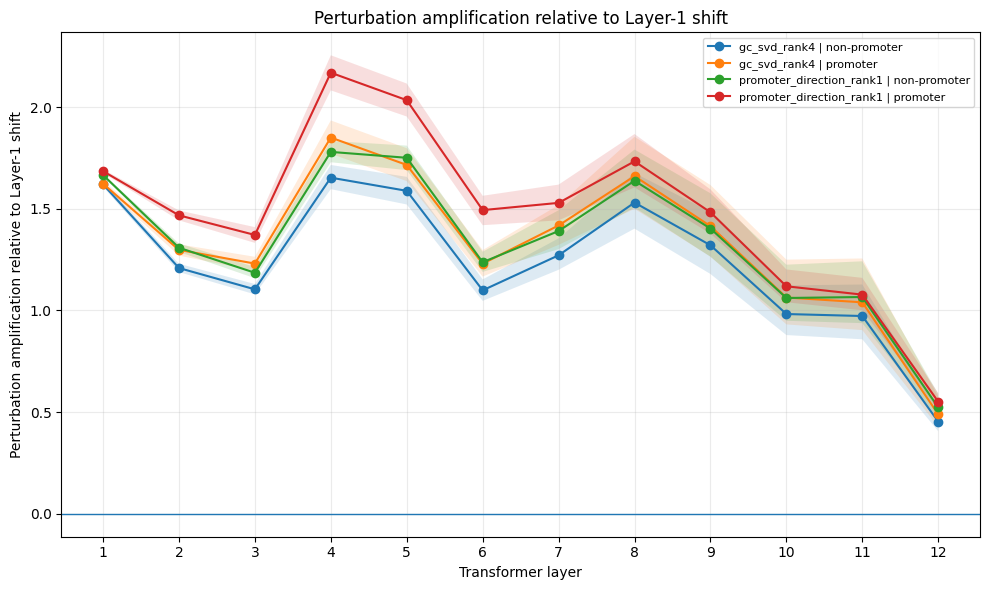

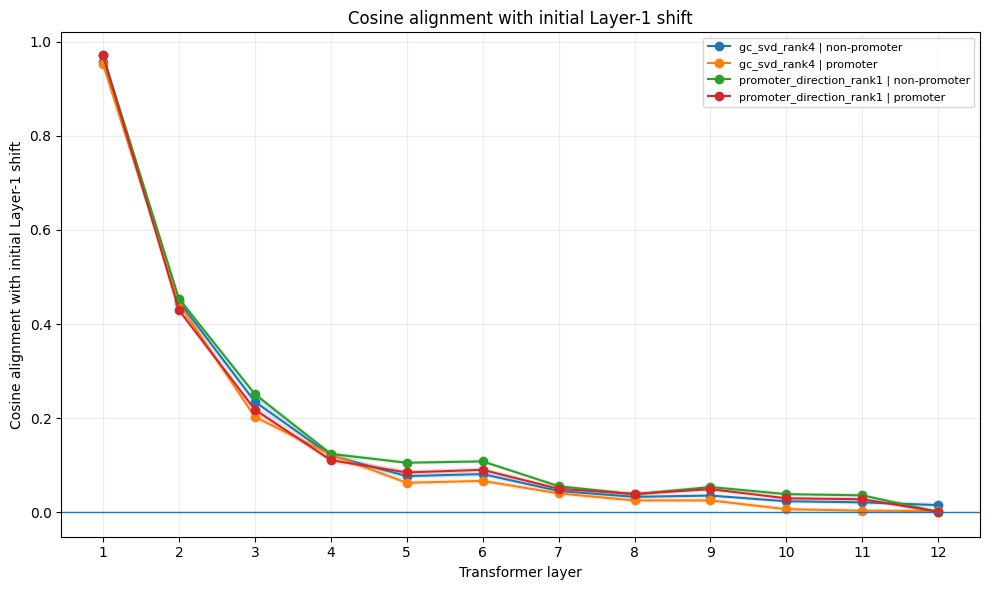

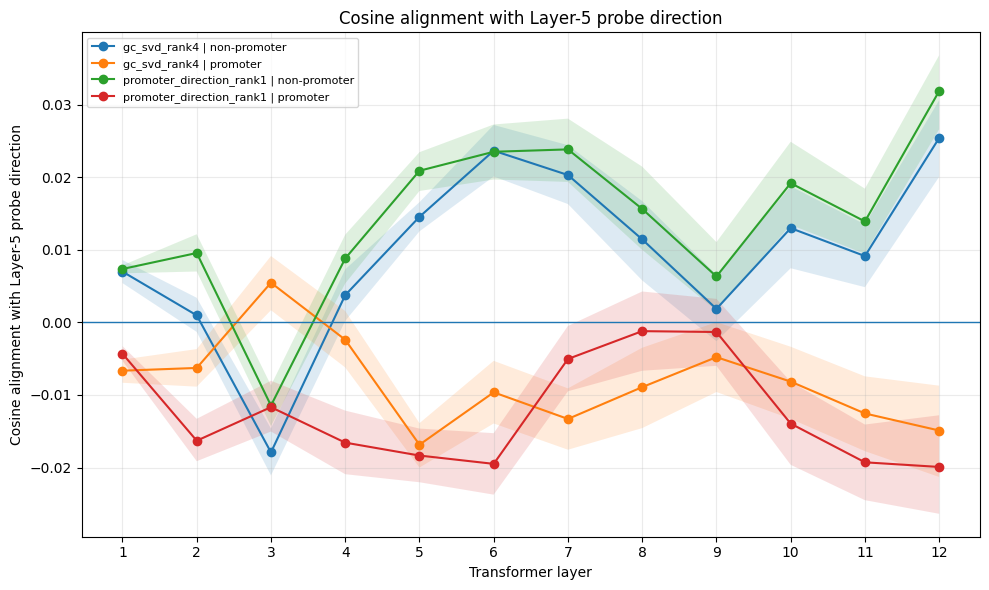

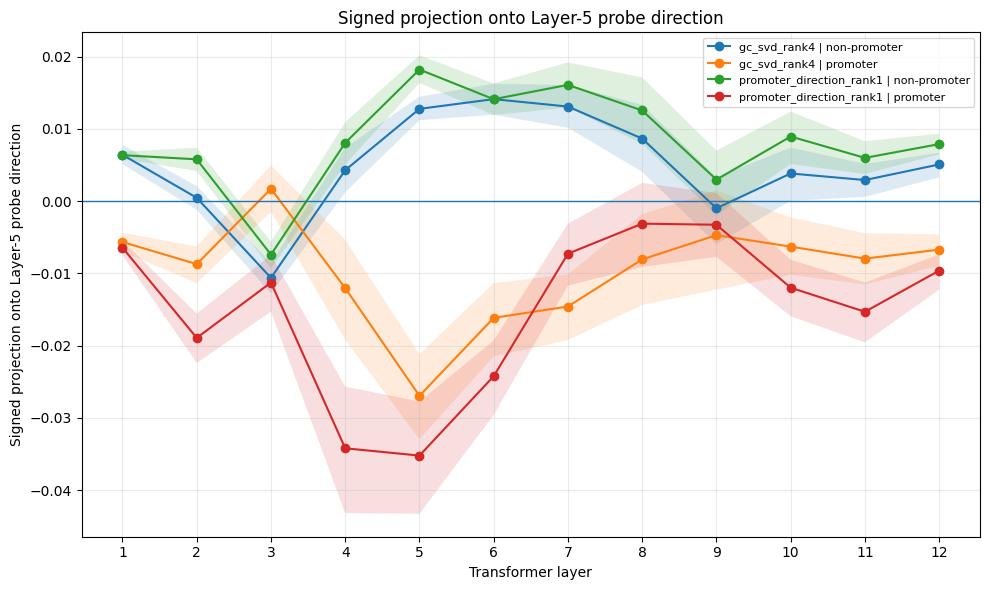


Saved propagation evidence
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_propagation_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_amplification_pivot.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_initial_shift_alignment_pivot.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_probe_alignment_pivot.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_probe_projection_pivot.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layer5_logit_effect_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/propagation_characteristic_layers.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/layerwise_perturbatio

In [18]:
# ============================================================
# Cell 5
# Summarize and visualize layer-wise propagation
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Bootstrap helper
# ------------------------------------------------------------

BOOTSTRAP_SEED = 42
NUMBER_OF_BOOTSTRAP_SAMPLES = 2000

bootstrap_rng = np.random.default_rng(
    BOOTSTRAP_SEED
)


def bootstrap_mean_interval(
    values: np.ndarray,
    number_of_samples: int = NUMBER_OF_BOOTSTRAP_SAMPLES,
    confidence_level: float = 0.95,
) -> tuple[float, float, float]:
    """
    Return:
      mean,
      lower confidence bound,
      upper confidence bound
    """
    values = np.asarray(
        values,
        dtype=np.float64,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return (
            np.nan,
            np.nan,
            np.nan,
        )

    sample_indices = bootstrap_rng.integers(
        low=0,
        high=len(values),
        size=(
            number_of_samples,
            len(values),
        ),
    )

    bootstrap_means = values[
        sample_indices
    ].mean(
        axis=1
    )

    alpha = (
        1.0
        - confidence_level
    )

    lower = float(
        np.quantile(
            bootstrap_means,
            alpha / 2.0,
        )
    )

    upper = float(
        np.quantile(
            bootstrap_means,
            1.0 - alpha / 2.0,
        )
    )

    return (
        float(
            values.mean()
        ),
        lower,
        upper,
    )


# ------------------------------------------------------------
# Metrics to summarize
# ------------------------------------------------------------

PROPAGATION_METRICS = {
    "layer_delta_norm": (
        "Layer perturbation norm"
    ),
    "layer_delta_over_initial_shift": (
        "Amplification relative to initial shift"
    ),
    "alignment_with_initial_shift": (
        "Alignment with initial Layer-1 shift"
    ),
    "alignment_with_probe_direction": (
        "Alignment with Layer-5 probe direction"
    ),
    "signed_probe_direction_projection": (
        "Signed projection onto probe direction"
    ),
}


# ------------------------------------------------------------
# Compute bootstrap summaries
# ------------------------------------------------------------

summary_rows = []


group_columns = [
    "intervention_name",
    "source_class",
    "layer",
]


for group_key, group_table in (
    layerwise_propagation_results.groupby(
        group_columns,
        sort=True,
    )
):
    (
        intervention_name,
        source_class,
        layer,
    ) = group_key

    for metric_name, metric_label in (
        PROPAGATION_METRICS.items()
    ):
        (
            mean_value,
            ci_lower,
            ci_upper,
        ) = bootstrap_mean_interval(
            group_table[
                metric_name
            ].to_numpy()
        )

        summary_rows.append(
            {
                "intervention_name": (
                    intervention_name
                ),
                "source_class": (
                    source_class
                ),
                "layer": int(
                    layer
                ),
                "metric": (
                    metric_name
                ),
                "metric_label": (
                    metric_label
                ),
                "number_of_sequences": int(
                    len(
                        group_table
                    )
                ),
                "mean": (
                    mean_value
                ),
                "ci_2.5": (
                    ci_lower
                ),
                "ci_97.5": (
                    ci_upper
                ),
                "median": float(
                    np.nanmedian(
                        group_table[
                            metric_name
                        ]
                    )
                ),
                "standard_deviation": float(
                    np.nanstd(
                        group_table[
                            metric_name
                        ],
                        ddof=1,
                    )
                ),
                "fraction_positive": float(
                    np.nanmean(
                        group_table[
                            metric_name
                        ]
                        > 0
                    )
                ),
            }
        )


layerwise_propagation_summary = pd.DataFrame(
    summary_rows
)


print("=" * 80)
print("Layer-wise propagation summary")
print("=" * 80)

print(
    "Summary rows:",
    len(
        layerwise_propagation_summary
    ),
)

display(
    layerwise_propagation_summary.head(
        20
    )
)


# ------------------------------------------------------------
# Compact wide tables for interpretation
# ------------------------------------------------------------

def make_metric_pivot(
    metric_name: str,
) -> pd.DataFrame:
    metric_table = (
        layerwise_propagation_summary.loc[
            layerwise_propagation_summary[
                "metric"
            ].eq(
                metric_name
            )
        ]
        .pivot_table(
            index=[
                "intervention_name",
                "source_class",
            ],
            columns="layer",
            values="mean",
        )
        .reset_index()
    )

    metric_table.columns.name = None

    return metric_table


amplification_pivot = make_metric_pivot(
    "layer_delta_over_initial_shift"
)

initial_alignment_pivot = make_metric_pivot(
    "alignment_with_initial_shift"
)

probe_alignment_pivot = make_metric_pivot(
    "alignment_with_probe_direction"
)

probe_projection_pivot = make_metric_pivot(
    "signed_probe_direction_projection"
)


print("\n" + "=" * 80)
print("Mean amplification relative to initial shift")
print("=" * 80)

display(
    amplification_pivot
)


print("\n" + "=" * 80)
print("Mean alignment with initial Layer-1 shift")
print("=" * 80)

display(
    initial_alignment_pivot
)


print("\n" + "=" * 80)
print("Mean alignment with Layer-5 probe direction")
print("=" * 80)

display(
    probe_alignment_pivot
)


print("\n" + "=" * 80)
print("Mean signed projection onto probe direction")
print("=" * 80)

display(
    probe_projection_pivot
)


# ------------------------------------------------------------
# Final Layer-5 diagnostic effects
#
# Use one row per sequence/intervention because the Layer-5
# logit change is repeated across all 12 layer rows.
# ------------------------------------------------------------

unique_logit_effects = (
    layerwise_propagation_results.loc[
        layerwise_propagation_results[
            "layer"
        ].eq(5)
    ]
    [
        [
            "source_class",
            "source_index",
            "intervention_name",
            "clean_layer5_probe_logit",
            "intervened_layer5_probe_logit",
            "layer5_probe_logit_change",
            "requested_shift_norm",
        ]
    ]
    .copy()
)


logit_effect_rows = []


for group_key, group_table in (
    unique_logit_effects.groupby(
        [
            "intervention_name",
            "source_class",
        ],
        sort=True,
    )
):
    (
        intervention_name,
        source_class,
    ) = group_key

    (
        mean_change,
        ci_lower,
        ci_upper,
    ) = bootstrap_mean_interval(
        group_table[
            "layer5_probe_logit_change"
        ].to_numpy()
    )

    expected_sign = (
        -1.0
        if source_class == "promoter"
        else 1.0
    )

    signed_expected_change = (
        group_table[
            "layer5_probe_logit_change"
        ].to_numpy()
        * expected_sign
    )

    logit_effect_rows.append(
        {
            "intervention_name": (
                intervention_name
            ),
            "source_class": (
                source_class
            ),
            "number_of_sequences": int(
                len(
                    group_table
                )
            ),
            "mean_clean_logit": float(
                group_table[
                    "clean_layer5_probe_logit"
                ].mean()
            ),
            "mean_intervened_logit": float(
                group_table[
                    "intervened_layer5_probe_logit"
                ].mean()
            ),
            "mean_logit_change": (
                mean_change
            ),
            "ci_2.5": (
                ci_lower
            ),
            "ci_97.5": (
                ci_upper
            ),
            "median_logit_change": float(
                group_table[
                    "layer5_probe_logit_change"
                ].median()
            ),
            "fraction_expected_direction": float(
                np.mean(
                    signed_expected_change
                    > 0
                )
            ),
            "mean_requested_shift_norm": float(
                group_table[
                    "requested_shift_norm"
                ].mean()
            ),
        }
    )


layer5_logit_effect_summary = pd.DataFrame(
    logit_effect_rows
)


print("\n" + "=" * 80)
print("Layer-5 diagnostic-logit effects")
print("=" * 80)

display(
    layer5_logit_effect_summary
)


# ------------------------------------------------------------
# Find characteristic layers
# ------------------------------------------------------------

characteristic_rows = []


for group_key, group_table in (
    layerwise_propagation_summary.groupby(
        [
            "intervention_name",
            "source_class",
        ],
        sort=True,
    )
):
    (
        intervention_name,
        source_class,
    ) = group_key

    def metric_subset(
        metric_name: str,
    ) -> pd.DataFrame:
        return (
            group_table.loc[
                group_table[
                    "metric"
                ].eq(
                    metric_name
                )
            ]
            .sort_values(
                "layer"
            )
            .reset_index(
                drop=True
            )
        )


    amplification_table = metric_subset(
        "layer_delta_over_initial_shift"
    )

    initial_alignment_table = metric_subset(
        "alignment_with_initial_shift"
    )

    probe_alignment_table = metric_subset(
        "alignment_with_probe_direction"
    )

    probe_projection_table = metric_subset(
        "signed_probe_direction_projection"
    )


    maximum_amplification_row = (
        amplification_table.loc[
            amplification_table[
                "mean"
            ].idxmax()
        ]
    )

    maximum_absolute_probe_projection_row = (
        probe_projection_table.loc[
            probe_projection_table[
                "mean"
            ].abs().idxmax()
        ]
    )

    characteristic_rows.append(
        {
            "intervention_name": (
                intervention_name
            ),
            "source_class": (
                source_class
            ),
            "layer_of_maximum_amplification": int(
                maximum_amplification_row[
                    "layer"
                ]
            ),
            "maximum_mean_amplification": float(
                maximum_amplification_row[
                    "mean"
                ]
            ),
            "layer_of_maximum_absolute_probe_projection": int(
                maximum_absolute_probe_projection_row[
                    "layer"
                ]
            ),
            "maximum_absolute_mean_probe_projection": float(
                abs(
                    maximum_absolute_probe_projection_row[
                        "mean"
                    ]
                )
            ),
            "layer1_initial_alignment": float(
                initial_alignment_table.loc[
                    initial_alignment_table[
                        "layer"
                    ].eq(1),
                    "mean",
                ].iloc[0]
            ),
            "layer5_initial_alignment": float(
                initial_alignment_table.loc[
                    initial_alignment_table[
                        "layer"
                    ].eq(5),
                    "mean",
                ].iloc[0]
            ),
            "layer12_initial_alignment": float(
                initial_alignment_table.loc[
                    initial_alignment_table[
                        "layer"
                    ].eq(12),
                    "mean",
                ].iloc[0]
            ),
            "layer1_probe_alignment": float(
                probe_alignment_table.loc[
                    probe_alignment_table[
                        "layer"
                    ].eq(1),
                    "mean",
                ].iloc[0]
            ),
            "layer5_probe_alignment": float(
                probe_alignment_table.loc[
                    probe_alignment_table[
                        "layer"
                    ].eq(5),
                    "mean",
                ].iloc[0]
            ),
            "layer12_probe_alignment": float(
                probe_alignment_table.loc[
                    probe_alignment_table[
                        "layer"
                    ].eq(12),
                    "mean",
                ].iloc[0]
            ),
        }
    )


propagation_characteristics = pd.DataFrame(
    characteristic_rows
)


print("\n" + "=" * 80)
print("Characteristic propagation layers")
print("=" * 80)

display(
    propagation_characteristics
)


# ------------------------------------------------------------
# Plot helper
# ------------------------------------------------------------

def plot_propagation_metric(
    metric_name: str,
    y_axis_label: str,
    output_filename: str,
) -> Path:
    figure, axis = plt.subplots(
        figsize=(
            10,
            6,
        )
    )

    metric_table = (
        layerwise_propagation_summary.loc[
            layerwise_propagation_summary[
                "metric"
            ].eq(
                metric_name
            )
        ]
        .copy()
    )


    for (
        intervention_name,
        source_class,
    ), group_table in metric_table.groupby(
        [
            "intervention_name",
            "source_class",
        ],
        sort=True,
    ):
        group_table = group_table.sort_values(
            "layer"
        )

        label = (
            f"{intervention_name} | "
            f"{source_class}"
        )

        axis.plot(
            group_table[
                "layer"
            ],
            group_table[
                "mean"
            ],
            marker="o",
            label=label,
        )

        axis.fill_between(
            group_table[
                "layer"
            ],
            group_table[
                "ci_2.5"
            ],
            group_table[
                "ci_97.5"
            ],
            alpha=0.15,
        )


    axis.axhline(
        0.0,
        linewidth=1,
    )

    axis.set_xlabel(
        "Transformer layer"
    )

    axis.set_ylabel(
        y_axis_label
    )

    axis.set_xticks(
        range(
            1,
            13,
        )
    )

    axis.set_title(
        y_axis_label
    )

    axis.legend(
        fontsize=8
    )

    axis.grid(
        alpha=0.25
    )

    figure.tight_layout()


    output_path = (
        NOTEBOOK9_DIR
        / output_filename
    )

    figure.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        figure
    )

    return output_path


# ------------------------------------------------------------
# Create figures
# ------------------------------------------------------------

amplification_figure_path = (
    plot_propagation_metric(
        metric_name=(
            "layer_delta_over_initial_shift"
        ),
        y_axis_label=(
            "Perturbation amplification relative to Layer-1 shift"
        ),
        output_filename=(
            "layerwise_perturbation_amplification.png"
        ),
    )
)


initial_alignment_figure_path = (
    plot_propagation_metric(
        metric_name=(
            "alignment_with_initial_shift"
        ),
        y_axis_label=(
            "Cosine alignment with initial Layer-1 shift"
        ),
        output_filename=(
            "layerwise_alignment_with_initial_shift.png"
        ),
    )
)


probe_alignment_figure_path = (
    plot_propagation_metric(
        metric_name=(
            "alignment_with_probe_direction"
        ),
        y_axis_label=(
            "Cosine alignment with Layer-5 probe direction"
        ),
        output_filename=(
            "layerwise_alignment_with_probe_direction.png"
        ),
    )
)


probe_projection_figure_path = (
    plot_propagation_metric(
        metric_name=(
            "signed_probe_direction_projection"
        ),
        y_axis_label=(
            "Signed projection onto Layer-5 probe direction"
        ),
        output_filename=(
            "layerwise_probe_direction_projection.png"
        ),
    )
)


# ------------------------------------------------------------
# Save tables
# ------------------------------------------------------------

PROPAGATION_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_propagation_summary.csv"
)

AMPLIFICATION_PIVOT_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_amplification_pivot.csv"
)

INITIAL_ALIGNMENT_PIVOT_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_initial_shift_alignment_pivot.csv"
)

PROBE_ALIGNMENT_PIVOT_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_probe_alignment_pivot.csv"
)

PROBE_PROJECTION_PIVOT_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_probe_projection_pivot.csv"
)

LAYER5_LOGIT_EFFECT_PATH = (
    NOTEBOOK9_DIR
    / "layer5_logit_effect_summary.csv"
)

PROPAGATION_CHARACTERISTICS_PATH = (
    NOTEBOOK9_DIR
    / "propagation_characteristic_layers.csv"
)


layerwise_propagation_summary.to_csv(
    PROPAGATION_SUMMARY_PATH,
    index=False,
)

amplification_pivot.to_csv(
    AMPLIFICATION_PIVOT_PATH,
    index=False,
)

initial_alignment_pivot.to_csv(
    INITIAL_ALIGNMENT_PIVOT_PATH,
    index=False,
)

probe_alignment_pivot.to_csv(
    PROBE_ALIGNMENT_PIVOT_PATH,
    index=False,
)

probe_projection_pivot.to_csv(
    PROBE_PROJECTION_PIVOT_PATH,
    index=False,
)

layer5_logit_effect_summary.to_csv(
    LAYER5_LOGIT_EFFECT_PATH,
    index=False,
)

propagation_characteristics.to_csv(
    PROPAGATION_CHARACTERISTICS_PATH,
    index=False,
)


# ------------------------------------------------------------
# Save analysis metadata
# ------------------------------------------------------------

propagation_analysis_metadata = {
    "bootstrap_seed": (
        BOOTSTRAP_SEED
    ),
    "number_of_bootstrap_samples": (
        NUMBER_OF_BOOTSTRAP_SAMPLES
    ),
    "number_of_sequences": int(
        len(
            clean_sources
        )
    ),
    "number_of_interventions": int(
        len(
            propagation_interventions
        )
    ),
    "number_of_layers": 12,
    "number_of_full_result_rows": int(
        len(
            layerwise_propagation_results
        )
    ),
    "figures": [
        str(
            amplification_figure_path
        ),
        str(
            initial_alignment_figure_path
        ),
        str(
            probe_alignment_figure_path
        ),
        str(
            probe_projection_figure_path
        ),
    ],
}


PROPAGATION_METADATA_PATH = (
    NOTEBOOK9_DIR
    / "layerwise_propagation_analysis_metadata.json"
)


with open(
    PROPAGATION_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        propagation_analysis_metadata,
        file,
        indent=2,
    )


print("\n" + "=" * 80)
print("Saved propagation evidence")
print("=" * 80)

for path in [
    PROPAGATION_SUMMARY_PATH,
    AMPLIFICATION_PIVOT_PATH,
    INITIAL_ALIGNMENT_PIVOT_PATH,
    PROBE_ALIGNMENT_PIVOT_PATH,
    PROBE_PROJECTION_PIVOT_PATH,
    LAYER5_LOGIT_EFFECT_PATH,
    PROPAGATION_CHARACTERISTICS_PATH,
    amplification_figure_path,
    initial_alignment_figure_path,
    probe_alignment_figure_path,
    probe_projection_figure_path,
    PROPAGATION_METADATA_PATH,
]:
    print(
        path
    )


print(
    "\nCell 5 complete. The Layer-1 causal-subspace "
    "perturbations have been summarized across all "
    "12 transformer layers."
)

In [19]:
# ============================================================
# Cell 6
# Inspect candidate downstream modules and hook-output shapes
# before mediation interventions
# ============================================================

from __future__ import annotations

from collections import OrderedDict
from typing import Any

import pandas as pd
import torch


# ------------------------------------------------------------
# Candidate downstream layers
#
# Layer numbering in reports is 1-based:
#   Layer 2 -> encoder.layer[1]
#   Layer 3 -> encoder.layer[2]
#   Layer 4 -> encoder.layer[3]
#   Layer 5 -> encoder.layer[4]
# ------------------------------------------------------------

CANDIDATE_LAYER_NUMBERS = [
    2,
    3,
    4,
    5,
]


# ------------------------------------------------------------
# List the custom architecture under each candidate layer
# ------------------------------------------------------------

module_inventory_rows = []


for layer_number in CANDIDATE_LAYER_NUMBERS:
    layer_module = (
        backbone.encoder.layer[
            layer_number - 1
        ]
    )

    for relative_name, module in (
        layer_module.named_modules()
    ):
        full_name = (
            f"encoder.layer."
            f"{layer_number - 1}"
        )

        if relative_name:
            full_name += (
                f".{relative_name}"
            )

        direct_parameter_count = sum(
            parameter.numel()
            for parameter in (
                module.parameters(
                    recurse=False
                )
            )
        )

        number_of_children = len(
            list(
                module.children()
            )
        )

        module_inventory_rows.append(
            {
                "reported_layer": (
                    layer_number
                ),
                "relative_name": (
                    relative_name
                    if relative_name
                    else "<layer_root>"
                ),
                "full_name": (
                    full_name
                ),
                "module_class": (
                    type(module).__name__
                ),
                "direct_parameter_count": int(
                    direct_parameter_count
                ),
                "number_of_children": int(
                    number_of_children
                ),
                "is_leaf_module": (
                    number_of_children == 0
                ),
            }
        )


downstream_module_inventory = pd.DataFrame(
    module_inventory_rows
)


print("=" * 80)
print("Downstream module inventory")
print("=" * 80)

display(
    downstream_module_inventory
)


# ------------------------------------------------------------
# Select likely branch/head-related modules for shape inspection
# ------------------------------------------------------------

MODULE_NAME_TERMS = [
    "attention",
    "self",
    "wqkv",
    "dense",
    "output",
    "mlp",
    "wo",
]


def is_candidate_module_name(
    relative_name: str,
) -> bool:
    lower_name = relative_name.lower()

    if relative_name == "<layer_root>":
        return True

    return any(
        term in lower_name
        for term in MODULE_NAME_TERMS
    )


candidate_inventory = (
    downstream_module_inventory.loc[
        downstream_module_inventory[
            "relative_name"
        ].map(
            is_candidate_module_name
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("Candidate modules selected for hook inspection")
print("=" * 80)

display(
    candidate_inventory
)


# ------------------------------------------------------------
# Resolve modules from their relative names
# ------------------------------------------------------------

def resolve_relative_module(
    root_module: torch.nn.Module,
    relative_name: str,
) -> torch.nn.Module:
    if relative_name == "<layer_root>":
        return root_module

    current_module = root_module

    for component in (
        relative_name.split(".")
    ):
        if component.isdigit():
            current_module = current_module[
                int(component)
            ]
        else:
            current_module = getattr(
                current_module,
                component,
            )

    return current_module


# ------------------------------------------------------------
# Describe tensors contained in a module output
# ------------------------------------------------------------

def describe_output(
    output: Any,
) -> dict[str, Any]:
    description = {
        "output_python_type": (
            type(output).__name__
        ),
        "tensor_shapes": [],
        "tensor_dtypes": [],
        "tensor_devices": [],
    }

    def record_tensor(
        tensor: torch.Tensor,
    ) -> None:
        description[
            "tensor_shapes"
        ].append(
            tuple(
                tensor.shape
            )
        )

        description[
            "tensor_dtypes"
        ].append(
            str(
                tensor.dtype
            )
        )

        description[
            "tensor_devices"
        ].append(
            str(
                tensor.device
            )
        )


    if torch.is_tensor(
        output
    ):
        record_tensor(
            output
        )

    elif isinstance(
        output,
        (tuple, list),
    ):
        for item in output:
            if torch.is_tensor(
                item
            ):
                record_tensor(
                    item
                )

    elif isinstance(
        output,
        dict,
    ):
        for item in output.values():
            if torch.is_tensor(
                item
            ):
                record_tensor(
                    item
                )

    return description


# ------------------------------------------------------------
# Register hooks and run one sequence
# ------------------------------------------------------------

shape_records = OrderedDict()

hook_handles = []


for row in candidate_inventory.itertuples():
    layer_number = int(
        row.reported_layer
    )

    relative_name = str(
        row.relative_name
    )

    layer_root = (
        backbone.encoder.layer[
            layer_number - 1
        ]
    )

    module = resolve_relative_module(
        layer_root,
        relative_name,
    )

    record_key = (
        f"L{layer_number}:"
        f"{relative_name}"
    )


    def make_shape_hook(
        stored_key: str,
    ):
        def hook(
            module,
            inputs,
            output,
        ):
            if stored_key in shape_records:
                return

            output_description = (
                describe_output(
                    output
                )
            )

            input_tensor_shapes = []

            for item in inputs:
                if torch.is_tensor(
                    item
                ):
                    input_tensor_shapes.append(
                        tuple(
                            item.shape
                        )
                    )

            shape_records[
                stored_key
            ] = {
                "module_class": (
                    type(module).__name__
                ),
                "input_tensor_shapes": (
                    input_tensor_shapes
                ),
                **output_description,
            }

        return hook


    hook_handles.append(
        module.register_forward_hook(
            make_shape_hook(
                record_key
            )
        )
    )


inspection_sequence = str(
    clean_sources.iloc[0][
        sequence_column
    ]
)


try:
    with torch.inference_mode():
        inspection_encoded = (
            tokenize_sequences(
                [
                    inspection_sequence
                ]
            )
        )

        _ = model(
            **inspection_encoded,
            return_dict=False,
        )

finally:
    for handle in hook_handles:
        handle.remove()


# ------------------------------------------------------------
# Convert hook records into a table
# ------------------------------------------------------------

shape_rows = []


for module_key, record in (
    shape_records.items()
):
    layer_text, relative_name = (
        module_key.split(
            ":",
            maxsplit=1,
        )
    )

    shape_rows.append(
        {
            "reported_layer": int(
                layer_text[
                    1:
                ]
            ),
            "relative_name": (
                relative_name
            ),
            "module_class": (
                record[
                    "module_class"
                ]
            ),
            "input_tensor_shapes": str(
                record[
                    "input_tensor_shapes"
                ]
            ),
            "output_python_type": (
                record[
                    "output_python_type"
                ]
            ),
            "output_tensor_shapes": str(
                record[
                    "tensor_shapes"
                ]
            ),
            "output_tensor_dtypes": str(
                record[
                    "tensor_dtypes"
                ]
            ),
            "output_tensor_devices": str(
                record[
                    "tensor_devices"
                ]
            ),
        }
    )


downstream_module_shape_inventory = pd.DataFrame(
    shape_rows
).sort_values(
    [
        "reported_layer",
        "relative_name",
    ]
).reset_index(
    drop=True
)


print("\n" + "=" * 80)
print("Observed downstream hook shapes")
print("=" * 80)

display(
    downstream_module_shape_inventory
)


# ------------------------------------------------------------
# Identify tensors that may contain concatenated head outputs
#
# With 12 heads and hidden size 768:
# each attention head has dimension 64.
# A tensor ending in 768 may contain concatenated heads,
# depending on where it occurs in the attention computation.
# ------------------------------------------------------------

HEAD_DIMENSION = (
    config.hidden_size
    // config.num_attention_heads
)


print("\n" + "=" * 80)
print("Attention geometry")
print("=" * 80)

print(
    "Hidden size:",
    config.hidden_size,
)

print(
    "Number of heads:",
    config.num_attention_heads,
)

print(
    "Head dimension:",
    HEAD_DIMENSION,
)


assert HEAD_DIMENSION == 64


# ------------------------------------------------------------
# Save inventories
# ------------------------------------------------------------

MODULE_INVENTORY_PATH = (
    NOTEBOOK9_DIR
    / "downstream_candidate_module_inventory.csv"
)

MODULE_SHAPE_INVENTORY_PATH = (
    NOTEBOOK9_DIR
    / "downstream_candidate_module_shape_inventory.csv"
)


downstream_module_inventory.to_csv(
    MODULE_INVENTORY_PATH,
    index=False,
)

downstream_module_shape_inventory.to_csv(
    MODULE_SHAPE_INVENTORY_PATH,
    index=False,
)


print("\nSaved:")
print(
    MODULE_INVENTORY_PATH
)

print(
    MODULE_SHAPE_INVENTORY_PATH
)

print(
    "\nCell 6 complete. Candidate downstream modules "
    "and their runtime tensor shapes have been recorded."
)

Downstream module inventory


,reported_layer,relative_name,full_name,module_class,direct_parameter_count,number_of_children,is_leaf_module
0,2,<layer_root>,encoder.layer.1,BertLayer,0,2,False
1,2,attention,encoder.layer.1.attention,BertUnpadAttention,0,2,False
2,2,attention.self,encoder.layer.1.attention.self,BertUnpadSelfAttention,0,2,False
3,2,attention.self.dropout,encoder.layer.1.attention.self.dropout,Dropout,0,0,True
4,2,attention.self.Wqkv,encoder.layer.1.attention.self.Wqkv,Linear,1771776,0,True
5,2,attention.output,encoder.layer.1.attention.output,BertSelfOutput,0,3,False
6,2,attention.output.dense,encoder.layer.1.attention.output.dense,Linear,590592,0,True
7,2,attention.output.LayerNorm,encoder.layer.1.attention.output.LayerNorm,LayerNorm,1536,0,True
8,2,attention.output.dropout,encoder.layer.1.attention.output.dropout,Dropout,0,0,True
9,2,mlp,encoder.layer.1.mlp,BertGatedLinearUnitMLP,0,5,False



Candidate modules selected for hook inspection


,reported_layer,relative_name,full_name,module_class,direct_parameter_count,number_of_children,is_leaf_module
0,2,<layer_root>,encoder.layer.1,BertLayer,0,2,False
1,2,attention,encoder.layer.1.attention,BertUnpadAttention,0,2,False
2,2,attention.self,encoder.layer.1.attention.self,BertUnpadSelfAttention,0,2,False
3,2,attention.self.dropout,encoder.layer.1.attention.self.dropout,Dropout,0,0,True
4,2,attention.self.Wqkv,encoder.layer.1.attention.self.Wqkv,Linear,1771776,0,True
5,2,attention.output,encoder.layer.1.attention.output,BertSelfOutput,0,3,False
6,2,attention.output.dense,encoder.layer.1.attention.output.dense,Linear,590592,0,True
7,2,attention.output.LayerNorm,encoder.layer.1.attention.output.LayerNorm,LayerNorm,1536,0,True
8,2,attention.output.dropout,encoder.layer.1.attention.output.dropout,Dropout,0,0,True
9,2,mlp,encoder.layer.1.mlp,BertGatedLinearUnitMLP,0,5,False



Observed downstream hook shapes


,reported_layer,relative_name,module_class,input_tensor_shapes,output_python_type,output_tensor_shapes,output_tensor_dtypes,output_tensor_devices
0,2,<layer_root>,BertLayer,"[(18, 768), (2,), (18,)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
1,2,attention,BertUnpadAttention,"[(18, 768), (2,), (18,), (1, 18), (1, 12, 18, 18)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
2,2,attention.output,BertSelfOutput,"[(18, 768), (18, 768)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
3,2,attention.output.LayerNorm,LayerNorm,"[(18, 768)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
4,2,attention.output.dense,Linear,"[(18, 768)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
5,2,attention.output.dropout,Dropout,"[(18, 768)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
6,2,attention.self,BertUnpadSelfAttention,"[(18, 768), (2,), (18,), (1, 18), (1, 12, 18, 18)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']
7,2,attention.self.Wqkv,Linear,"[(18, 768)]",Tensor,"[(18, 2304)]",['torch.float32'],['cuda:0']
8,2,attention.self.dropout,Dropout,"[(1, 12, 18, 18)]",Tensor,"[(1, 12, 18, 18)]",['torch.float32'],['cuda:0']
9,2,mlp,BertGatedLinearUnitMLP,"[(18, 768)]",Tensor,"[(18, 768)]",['torch.float32'],['cuda:0']



Attention geometry
Hidden size: 768
Number of heads: 12
Head dimension: 64

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/downstream_candidate_module_inventory.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/downstream_candidate_module_shape_inventory.csv

Cell 6 complete. Candidate downstream modules and their runtime tensor shapes have been recorded.


In [20]:
# ============================================================
# Cell 7
# Smoke test for downstream branch mediation
#
# Intervention:
#   Layer-1 MLP promoter-direction rank-1 shift
#
# Mediation test:
#   Restore one downstream attention/MLP branch output to its
#   clean value and measure how much of the Layer-5 probe-logit
#   effect is blocked.
# ============================================================

from __future__ import annotations

import gc
from collections import OrderedDict
from typing import Any

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Candidate downstream branch contribution modules
#
# These tensors occur before the branch is added into the
# residual stream:
#
#   attention.output.dense
#   mlp.wo
# ------------------------------------------------------------

DOWNSTREAM_BRANCH_MODULES = OrderedDict()


for reported_layer in [
    2,
    3,
    4,
    5,
]:
    layer_module = (
        backbone.encoder.layer[
            reported_layer - 1
        ]
    )

    DOWNSTREAM_BRANCH_MODULES[
        f"L{reported_layer}_attention"
    ] = (
        layer_module
        .attention
        .output
        .dense
    )

    DOWNSTREAM_BRANCH_MODULES[
        f"L{reported_layer}_mlp"
    ] = (
        layer_module
        .mlp
        .wo
    )


print("=" * 80)
print("Downstream mediation candidates")
print("=" * 80)

for component_name, component_module in (
    DOWNSTREAM_BRANCH_MODULES.items()
):
    print(
        f"{component_name:20s}",
        component_module,
    )


assert len(
    DOWNSTREAM_BRANCH_MODULES
) == 8


# ------------------------------------------------------------
# Select one promoter and one non-promoter sequence
# ------------------------------------------------------------

smoke_examples = (
    clean_sources.groupby(
        "source_class",
        sort=False,
    )
    .head(1)
    .copy()
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("Smoke-test examples")
print("=" * 80)

display(
    smoke_examples[
        [
            column
            for column in [
                "source_class",
                "source_index",
                sequence_column,
                "probe_logit",
            ]
            if column in smoke_examples.columns
        ]
    ]
)


assert set(
    smoke_examples[
        "source_class"
    ]
) == {
    "promoter",
    "non-promoter",
}


# ------------------------------------------------------------
# Capture clean candidate-module outputs and Layer-5 output
# ------------------------------------------------------------

def run_clean_branch_capture(
    sequence: str,
) -> dict[str, Any]:
    captured = {
        "branches": {},
    }

    handles = []


    for component_name, component_module in (
        DOWNSTREAM_BRANCH_MODULES.items()
    ):
        def make_capture_hook(
            stored_component_name: str,
        ):
            def hook(
                module,
                inputs,
                output,
            ):
                captured[
                    "branches"
                ][
                    stored_component_name
                ] = (
                    extract_tensor_from_output(
                        output
                    )
                    .detach()
                    .clone()
                )

            return hook


        handles.append(
            component_module.register_forward_hook(
                make_capture_hook(
                    component_name
                )
            )
        )


    def layer5_capture_hook(
        module,
        inputs,
        output,
    ):
        captured[
            "layer5"
        ] = (
            extract_tensor_from_output(
                output
            )
            .detach()
            .clone()
        )


    handles.append(
        layer5_block_module.register_forward_hook(
            layer5_capture_hook
        )
    )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        for handle in handles:
            handle.remove()


    if len(
        captured[
            "branches"
        ]
    ) != len(
        DOWNSTREAM_BRANCH_MODULES
    ):
        raise RuntimeError(
            "Not all downstream branch outputs were captured."
        )


    return captured


# ------------------------------------------------------------
# Run Layer-1 intervention, optionally restoring one downstream
# branch to its clean output
# ------------------------------------------------------------

def run_layer1_intervention_with_optional_branch_restore(
    sequence: str,
    shift_vector: np.ndarray,
    *,
    restore_component_name: str | None,
    clean_branch_outputs: dict[str, torch.Tensor],
) -> dict[str, Any]:
    captured = {}

    shift_tensor = torch.as_tensor(
        shift_vector,
        dtype=next(
            model.parameters()
        ).dtype,
        device=DEVICE,
    )

    handles = []


    # --------------------------------------------------------
    # Layer-1 causal-subspace intervention
    # --------------------------------------------------------

    def layer1_intervention_hook(
        module,
        inputs,
        output,
    ):
        output_tensor = (
            extract_tensor_from_output(
                output
            )
        )

        if output_tensor.ndim != 2:
            raise ValueError(
                "Expected Layer-1 MLP output with shape "
                "(tokens, 768)."
            )

        modified_output = (
            output_tensor.clone()
        )

        modified_output[
            1:-1
        ] = (
            modified_output[
                1:-1
            ]
            + shift_tensor
        )

        captured[
            "layer1_before"
        ] = (
            output_tensor.detach().clone()
        )

        captured[
            "layer1_after"
        ] = (
            modified_output.detach().clone()
        )

        return replace_tensor_in_output(
            output,
            modified_output,
        )


    handles.append(
        layer1_mlp_output_module.register_forward_hook(
            layer1_intervention_hook
        )
    )


    # --------------------------------------------------------
    # Restore one downstream branch to its clean output
    # --------------------------------------------------------

    if restore_component_name is not None:
        if (
            restore_component_name
            not in DOWNSTREAM_BRANCH_MODULES
        ):
            raise KeyError(
                "Unknown downstream component: "
                f"{restore_component_name}"
            )

        target_module = (
            DOWNSTREAM_BRANCH_MODULES[
                restore_component_name
            ]
        )

        clean_target_output = (
            clean_branch_outputs[
                restore_component_name
            ]
        )


        def clean_restore_hook(
            module,
            inputs,
            output,
        ):
            intervened_output = (
                extract_tensor_from_output(
                    output
                )
            )

            if (
                intervened_output.shape
                != clean_target_output.shape
            ):
                raise ValueError(
                    "Clean and intervened branch output shapes "
                    "do not match: "
                    f"{tuple(clean_target_output.shape)} versus "
                    f"{tuple(intervened_output.shape)}"
                )

            restored_output = (
                clean_target_output
                .to(
                    device=intervened_output.device,
                    dtype=intervened_output.dtype,
                )
                .clone()
            )

            captured[
                "branch_before_restore"
            ] = (
                intervened_output.detach().clone()
            )

            captured[
                "branch_after_restore"
            ] = (
                restored_output.detach().clone()
            )

            return replace_tensor_in_output(
                output,
                restored_output,
            )


        handles.append(
            target_module.register_forward_hook(
                clean_restore_hook
            )
        )


    # --------------------------------------------------------
    # Capture final Layer-5 representation
    # --------------------------------------------------------

    def layer5_capture_hook(
        module,
        inputs,
        output,
    ):
        captured[
            "layer5"
        ] = (
            extract_tensor_from_output(
                output
            )
            .detach()
            .clone()
        )


    handles.append(
        layer5_block_module.register_forward_hook(
            layer5_capture_hook
        )
    )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        for handle in handles:
            handle.remove()


    return captured


# ------------------------------------------------------------
# Calculate promoter-direction shift
# ------------------------------------------------------------

promoter_direction_specification = (
    propagation_interventions[
        "promoter_direction_rank1"
    ]
)


# ------------------------------------------------------------
# Execute smoke test
# ------------------------------------------------------------

mediation_smoke_rows = []


for smoke_position, smoke_row in (
    smoke_examples.iterrows()
):
    source_class = str(
        smoke_row[
            "source_class"
        ]
    )

    source_index = int(
        smoke_row[
            "source_index"
        ]
        if "source_index"
        in smoke_row.index
        else smoke_position
    )

    sequence = str(
        smoke_row[
            sequence_column
        ]
    )


    clean_capture = (
        run_clean_branch_capture(
            sequence
        )
    )


    clean_logit = (
        probe_logit_from_layer5_tokens(
            clean_capture[
                "layer5"
            ]
        )
    )


    # Capture the clean Layer-1 MLP output separately to derive
    # the same class-conditional coordinate shift as Notebook 8.
    clean_layer1_capture = {}


    def clean_layer1_hook(
        module,
        inputs,
        output,
    ):
        clean_layer1_capture[
            "activation"
        ] = (
            extract_tensor_from_output(
                output
            )
            .detach()
            .clone()
        )


    clean_layer1_handle = (
        layer1_mlp_output_module.register_forward_hook(
            clean_layer1_hook
        )
    )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        clean_layer1_handle.remove()


    (
        shift_vector,
        original_coordinates,
        target_coordinates,
    ) = compute_opposite_class_shift(
        clean_layer1_capture[
            "activation"
        ],
        promoter_direction_specification,
        source_class,
    )


    # Intervention without downstream blocking
    intervention_capture = (
        run_layer1_intervention_with_optional_branch_restore(
            sequence,
            shift_vector,
            restore_component_name=None,
            clean_branch_outputs=(
                clean_capture[
                    "branches"
                ]
            ),
        )
    )


    intervention_logit = (
        probe_logit_from_layer5_tokens(
            intervention_capture[
                "layer5"
            ]
        )
    )


    total_intervention_effect = (
        intervention_logit
        - clean_logit
    )


    mediation_smoke_rows.append(
        {
            "source_class": source_class,
            "source_index": source_index,
            "condition": (
                "intervention_only"
            ),
            "restored_component": None,
            "clean_logit": float(
                clean_logit
            ),
            "intervention_logit": float(
                intervention_logit
            ),
            "blocked_logit": float(
                intervention_logit
            ),
            "total_intervention_effect": float(
                total_intervention_effect
            ),
            "remaining_effect": float(
                total_intervention_effect
            ),
            "blocked_effect": 0.0,
            "fraction_effect_blocked": 0.0,
            "branch_delta_norm": np.nan,
            "requested_shift_norm": float(
                np.linalg.norm(
                    shift_vector
                )
            ),
        }
    )


    # Restore each downstream branch to its clean output.
    for component_name in (
        DOWNSTREAM_BRANCH_MODULES.keys()
    ):
        blocked_capture = (
            run_layer1_intervention_with_optional_branch_restore(
                sequence,
                shift_vector,
                restore_component_name=(
                    component_name
                ),
                clean_branch_outputs=(
                    clean_capture[
                        "branches"
                    ]
                ),
            )
        )


        blocked_logit = (
            probe_logit_from_layer5_tokens(
                blocked_capture[
                    "layer5"
                ]
            )
        )


        remaining_effect = (
            blocked_logit
            - clean_logit
        )

        blocked_effect = (
            intervention_logit
            - blocked_logit
        )


        if abs(
            total_intervention_effect
        ) > 1e-12:
            fraction_effect_blocked = (
                blocked_effect
                / total_intervention_effect
            )
        else:
            fraction_effect_blocked = np.nan


        branch_delta_norm = float(
            torch.linalg.vector_norm(
                blocked_capture[
                    "branch_before_restore"
                ]
                -
                blocked_capture[
                    "branch_after_restore"
                ]
            ).item()
        )


        mediation_smoke_rows.append(
            {
                "source_class": source_class,
                "source_index": source_index,
                "condition": (
                    "intervention_plus_clean_restore"
                ),
                "restored_component": (
                    component_name
                ),
                "clean_logit": float(
                    clean_logit
                ),
                "intervention_logit": float(
                    intervention_logit
                ),
                "blocked_logit": float(
                    blocked_logit
                ),
                "total_intervention_effect": float(
                    total_intervention_effect
                ),
                "remaining_effect": float(
                    remaining_effect
                ),
                "blocked_effect": float(
                    blocked_effect
                ),
                "fraction_effect_blocked": float(
                    fraction_effect_blocked
                ),
                "branch_delta_norm": (
                    branch_delta_norm
                ),
                "requested_shift_norm": float(
                    np.linalg.norm(
                        shift_vector
                    )
                ),
            }
        )


# ------------------------------------------------------------
# Inspect smoke results
# ------------------------------------------------------------

branch_mediation_smoke_results = pd.DataFrame(
    mediation_smoke_rows
)


print("\n" + "=" * 80)
print("Branch-mediation smoke-test results")
print("=" * 80)

display(
    branch_mediation_smoke_results
)


# Compact ranking, excluding the intervention-only baseline.
branch_mediation_smoke_ranking = (
    branch_mediation_smoke_results.loc[
        branch_mediation_smoke_results[
            "restored_component"
        ].notna()
    ]
    [
        [
            "source_class",
            "restored_component",
            "clean_logit",
            "intervention_logit",
            "blocked_logit",
            "total_intervention_effect",
            "blocked_effect",
            "fraction_effect_blocked",
            "branch_delta_norm",
        ]
    ]
    .sort_values(
        [
            "source_class",
            "fraction_effect_blocked",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("Smoke-test mediation ranking")
print("=" * 80)

display(
    branch_mediation_smoke_ranking
)


# ------------------------------------------------------------
# Basic technical validation
# ------------------------------------------------------------

maximum_requested_shift_error_smoke = 0.0


for source_class in [
    "promoter",
    "non-promoter",
]:
    class_rows = (
        branch_mediation_smoke_results.loc[
            branch_mediation_smoke_results[
                "source_class"
            ].eq(
                source_class
            )
        ]
    )

    assert (
        class_rows[
            "clean_logit"
        ].nunique()
        == 1
    )

    assert (
        class_rows[
            "intervention_logit"
        ].nunique()
        == 1
    )


assert np.isfinite(
    branch_mediation_smoke_ranking[
        "blocked_logit"
    ]
).all()

assert np.isfinite(
    branch_mediation_smoke_ranking[
        "branch_delta_norm"
    ]
).all()


# ------------------------------------------------------------
# Save smoke-test results
# ------------------------------------------------------------

BRANCH_MEDIATION_SMOKE_RESULTS_PATH = (
    NOTEBOOK9_DIR
    / "branch_mediation_smoke_results.csv"
)

BRANCH_MEDIATION_SMOKE_RANKING_PATH = (
    NOTEBOOK9_DIR
    / "branch_mediation_smoke_ranking.csv"
)


branch_mediation_smoke_results.to_csv(
    BRANCH_MEDIATION_SMOKE_RESULTS_PATH,
    index=False,
)

branch_mediation_smoke_ranking.to_csv(
    BRANCH_MEDIATION_SMOKE_RANKING_PATH,
    index=False,
)


gc.collect()
torch.cuda.empty_cache()


print("\nSaved:")
print(
    BRANCH_MEDIATION_SMOKE_RESULTS_PATH
)

print(
    BRANCH_MEDIATION_SMOKE_RANKING_PATH
)

print(
    "\nCell 7 complete. Clean restoration of each "
    "downstream attention and MLP branch has been tested "
    "on one promoter and one non-promoter sequence."
)

Downstream mediation candidates
L2_attention         Linear(in_features=768, out_features=768, bias=True)
L2_mlp               Linear(in_features=3072, out_features=768, bias=True)
L3_attention         Linear(in_features=768, out_features=768, bias=True)
L3_mlp               Linear(in_features=3072, out_features=768, bias=True)
L4_attention         Linear(in_features=768, out_features=768, bias=True)
L4_mlp               Linear(in_features=3072, out_features=768, bias=True)
L5_attention         Linear(in_features=768, out_features=768, bias=True)
L5_mlp               Linear(in_features=3072, out_features=768, bias=True)

Smoke-test examples


,source_class,source_index,variant_sequence,probe_logit
0,non-promoter,0,CCAGGAATTATTTCGCCTTATTCCAATTCATAGAGACCAGAGGCGAACGGTACGAGGGAGGGAGCGAGGT,2.096601
1,promoter,0,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGCGCTGACCCACCGAGCCCTCGCTCA,5.393593



Branch-mediation smoke-test results


,source_class,source_index,condition,restored_component,clean_logit,intervention_logit,blocked_logit,total_intervention_effect,remaining_effect,blocked_effect,fraction_effect_blocked,branch_delta_norm,requested_shift_norm
0,non-promoter,0,intervention_only,None,2.096593,2.359346,2.359346,0.262753,0.262753,0.000000,0.000000,NaN,0.366817
1,non-promoter,0,intervention_plus_clean_restore,L2_attention,2.096593,2.359346,2.387497,0.262753,0.290904,-0.028151,-0.107139,4.457056,0.366817
2,non-promoter,0,intervention_plus_clean_restore,L2_mlp,2.096593,2.359346,2.449141,0.262753,0.352548,-0.089795,-0.341748,3.798410,0.366817
3,non-promoter,0,intervention_plus_clean_restore,L3_attention,2.096593,2.359346,1.933774,0.262753,-0.162819,0.425572,1.619668,3.599776,0.366817
4,non-promoter,0,intervention_plus_clean_restore,L3_mlp,2.096593,2.359346,2.385939,0.262753,0.289346,-0.026593,-0.101209,5.886547,0.366817
5,non-promoter,0,intervention_plus_clean_restore,L4_attention,2.096593,2.359346,1.881407,0.262753,-0.215186,0.477939,1.818967,3.694498,0.366817
6,non-promoter,0,intervention_plus_clean_restore,L4_mlp,2.096593,2.359346,3.349017,0.262753,1.252424,-0.989671,-3.766548,10.153830,0.366817
7,non-promoter,0,intervention_plus_clean_restore,L5_attention,2.096593,2.359346,3.120694,0.262753,1.024101,-0.761348,-2.897583,3.395885,0.366817
8,non-promoter,0,intervention_plus_clean_restore,L5_mlp,2.096593,2.359346,3.386030,0.262753,1.289437,-1.026684,-3.907415,8.074137,0.366817
9,promoter,0,intervention_only,None,5.393570,-8.473812,-8.473812,-13.867382,-13.867382,0.000000,0.000000,NaN,1.385218



Smoke-test mediation ranking


,source_class,restored_component,clean_logit,intervention_logit,blocked_logit,total_intervention_effect,blocked_effect,fraction_effect_blocked,branch_delta_norm
0,non-promoter,L4_attention,2.096593,2.359346,1.881407,0.262753,0.477939,1.818967,3.694498
1,non-promoter,L3_attention,2.096593,2.359346,1.933774,0.262753,0.425572,1.619668,3.599776
2,non-promoter,L3_mlp,2.096593,2.359346,2.385939,0.262753,-0.026593,-0.101209,5.886547
3,non-promoter,L2_attention,2.096593,2.359346,2.387497,0.262753,-0.028151,-0.107139,4.457056
4,non-promoter,L2_mlp,2.096593,2.359346,2.449141,0.262753,-0.089795,-0.341748,3.798410
5,non-promoter,L5_attention,2.096593,2.359346,3.120694,0.262753,-0.761348,-2.897583,3.395885
6,non-promoter,L4_mlp,2.096593,2.359346,3.349017,0.262753,-0.989671,-3.766548,10.153830
7,non-promoter,L5_mlp,2.096593,2.359346,3.386030,0.262753,-1.026684,-3.907415,8.074137
8,promoter,L2_mlp,5.393570,-8.473812,0.425272,-13.867382,-8.899084,0.641728,14.692724
9,promoter,L5_mlp,5.393570,-8.473812,-1.165720,-13.867382,-7.308092,0.526999,74.587547



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/branch_mediation_smoke_results.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/branch_mediation_smoke_ranking.csv

Cell 7 complete. Clean restoration of each downstream attention and MLP branch has been tested on one promoter and one non-promoter sequence.


In [21]:
# ============================================================
# Cell 8
# Full downstream branch-mediation scan
#
# For each sequence:
#   1. Clean forward pass
#   2. Layer-1 promoter-direction intervention
#   3. Intervention + clean restoration of each candidate
#      downstream branch
#
# Readout:
#   fixed Layer-5 diagnostic probe
# ============================================================

from __future__ import annotations

import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

FULL_MEDIATION_CHECKPOINT_PATH = (
    NOTEBOOK9_DIR
    / "full_branch_mediation_checkpoint.pkl"
)

FULL_MEDIATION_RESULTS_PATH = (
    NOTEBOOK9_DIR
    / "full_branch_mediation_results.csv"
)

FULL_MEDIATION_RESULTS_PICKLE_PATH = (
    NOTEBOOK9_DIR
    / "full_branch_mediation_results.pkl"
)


# ------------------------------------------------------------
# Resume support
# ------------------------------------------------------------

if FULL_MEDIATION_CHECKPOINT_PATH.exists():
    prior_mediation_results = pd.read_pickle(
        FULL_MEDIATION_CHECKPOINT_PATH
    )

    full_mediation_rows = (
        prior_mediation_results.to_dict(
            orient="records"
        )
    )

    completed_run_ids = set(
        prior_mediation_results[
            "run_id"
        ].astype(str)
    )

    print(
        "Loaded checkpoint rows:",
        len(
            prior_mediation_results
        ),
    )

else:
    full_mediation_rows = []
    completed_run_ids = set()

    print(
        "No full-mediation checkpoint found."
    )


# ------------------------------------------------------------
# Expected conditions
# ------------------------------------------------------------

MEDIATION_CONDITIONS = [
    "intervention_only",
    *list(
        DOWNSTREAM_BRANCH_MODULES.keys()
    ),
]


expected_number_of_rows = (
    len(
        clean_sources
    )
    * len(
        MEDIATION_CONDITIONS
    )
)


print("\n" + "=" * 80)
print("Full downstream branch-mediation scan")
print("=" * 80)

print(
    "Sequences:",
    len(
        clean_sources
    ),
)

print(
    "Conditions per sequence:",
    len(
        MEDIATION_CONDITIONS
    ),
)

print(
    "Candidate branches:",
    list(
        DOWNSTREAM_BRANCH_MODULES.keys()
    ),
)

print(
    "Expected result rows:",
    expected_number_of_rows,
)


# ------------------------------------------------------------
# Run full scan
# ------------------------------------------------------------

scan_start_time = time.time()

new_sequences_completed = 0


for source_position, source_row in (
    clean_sources.reset_index(
        drop=True
    ).iterrows()
):
    source_class = str(
        source_row[
            "source_class"
        ]
    )

    source_index = int(
        source_row[
            "source_index"
        ]
        if "source_index"
        in source_row.index
        else source_position
    )

    sequence = str(
        source_row[
            sequence_column
        ]
    )


    expected_run_ids_for_sequence = {
        (
            f"{source_class}|"
            f"{source_index}|"
            f"{condition}"
        )
        for condition in (
            MEDIATION_CONDITIONS
        )
    }


    if expected_run_ids_for_sequence.issubset(
        completed_run_ids
    ):
        continue


    # --------------------------------------------------------
    # Clean branch capture
    # --------------------------------------------------------

    clean_capture = (
        run_clean_branch_capture(
            sequence
        )
    )


    clean_logit = (
        probe_logit_from_layer5_tokens(
            clean_capture[
                "layer5"
            ]
        )
    )


    # --------------------------------------------------------
    # Capture clean Layer-1 MLP output
    # --------------------------------------------------------

    clean_layer1_capture = {}


    def full_scan_clean_layer1_hook(
        module,
        inputs,
        output,
    ):
        clean_layer1_capture[
            "activation"
        ] = (
            extract_tensor_from_output(
                output
            )
            .detach()
            .clone()
        )


    clean_layer1_handle = (
        layer1_mlp_output_module.register_forward_hook(
            full_scan_clean_layer1_hook
        )
    )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        clean_layer1_handle.remove()


    # --------------------------------------------------------
    # Class-conditional Layer-1 shift
    # --------------------------------------------------------

    (
        shift_vector,
        original_coordinates,
        target_coordinates,
    ) = compute_opposite_class_shift(
        clean_layer1_capture[
            "activation"
        ],
        promoter_direction_specification,
        source_class,
    )


    # --------------------------------------------------------
    # Intervention-only run
    # --------------------------------------------------------

    intervention_run_id = (
        f"{source_class}|"
        f"{source_index}|"
        f"intervention_only"
    )


    intervention_capture = (
        run_layer1_intervention_with_optional_branch_restore(
            sequence,
            shift_vector,
            restore_component_name=None,
            clean_branch_outputs=(
                clean_capture[
                    "branches"
                ]
            ),
        )
    )


    intervention_logit = (
        probe_logit_from_layer5_tokens(
            intervention_capture[
                "layer5"
            ]
        )
    )


    total_intervention_effect = (
        intervention_logit
        - clean_logit
    )


    if (
        intervention_run_id
        not in completed_run_ids
    ):
        full_mediation_rows.append(
            {
                "run_id": (
                    intervention_run_id
                ),
                "source_position": int(
                    source_position
                ),
                "source_index": int(
                    source_index
                ),
                "source_class": (
                    source_class
                ),
                "condition": (
                    "intervention_only"
                ),
                "restored_component": None,
                "clean_logit": float(
                    clean_logit
                ),
                "intervention_logit": float(
                    intervention_logit
                ),
                "blocked_logit": float(
                    intervention_logit
                ),
                "total_intervention_effect": float(
                    total_intervention_effect
                ),
                "remaining_effect": float(
                    total_intervention_effect
                ),
                "blocked_effect": 0.0,
                "fraction_effect_blocked": 0.0,
                "absolute_fraction_effect_blocked": 0.0,
                "expected_direction_total_effect": float(
                    (
                        -total_intervention_effect
                        if source_class == "promoter"
                        else total_intervention_effect
                    )
                ),
                "expected_direction_remaining_effect": float(
                    (
                        -total_intervention_effect
                        if source_class == "promoter"
                        else total_intervention_effect
                    )
                ),
                "expected_direction_blocked_effect": 0.0,
                "branch_delta_norm": np.nan,
                "requested_shift_norm": float(
                    np.linalg.norm(
                        shift_vector
                    )
                ),
                "original_coordinate": float(
                    original_coordinates[
                        0
                    ]
                ),
                "target_coordinate": float(
                    target_coordinates[
                        0
                    ]
                ),
            }
        )

        completed_run_ids.add(
            intervention_run_id
        )


    # --------------------------------------------------------
    # Restore each candidate downstream branch
    # --------------------------------------------------------

    for component_name in (
        DOWNSTREAM_BRANCH_MODULES.keys()
    ):
        run_id = (
            f"{source_class}|"
            f"{source_index}|"
            f"{component_name}"
        )


        if run_id in completed_run_ids:
            continue


        blocked_capture = (
            run_layer1_intervention_with_optional_branch_restore(
                sequence,
                shift_vector,
                restore_component_name=(
                    component_name
                ),
                clean_branch_outputs=(
                    clean_capture[
                        "branches"
                    ]
                ),
            )
        )


        blocked_logit = (
            probe_logit_from_layer5_tokens(
                blocked_capture[
                    "layer5"
                ]
            )
        )


        remaining_effect = (
            blocked_logit
            - clean_logit
        )


        blocked_effect = (
            intervention_logit
            - blocked_logit
        )


        if abs(
            total_intervention_effect
        ) > 1e-8:
            fraction_effect_blocked = (
                blocked_effect
                / total_intervention_effect
            )
        else:
            fraction_effect_blocked = np.nan


        if abs(
            total_intervention_effect
        ) > 1e-8:
            absolute_fraction_effect_blocked = (
                abs(
                    blocked_effect
                )
                / abs(
                    total_intervention_effect
                )
            )
        else:
            absolute_fraction_effect_blocked = np.nan


        expected_sign = (
            -1.0
            if source_class == "promoter"
            else 1.0
        )


        expected_direction_total_effect = (
            expected_sign
            * total_intervention_effect
        )

        expected_direction_remaining_effect = (
            expected_sign
            * remaining_effect
        )

        expected_direction_blocked_effect = (
            expected_sign
            * blocked_effect
        )


        branch_delta_norm = float(
            torch.linalg.vector_norm(
                blocked_capture[
                    "branch_before_restore"
                ]
                -
                blocked_capture[
                    "branch_after_restore"
                ]
            ).item()
        )


        full_mediation_rows.append(
            {
                "run_id": (
                    run_id
                ),
                "source_position": int(
                    source_position
                ),
                "source_index": int(
                    source_index
                ),
                "source_class": (
                    source_class
                ),
                "condition": (
                    "intervention_plus_clean_restore"
                ),
                "restored_component": (
                    component_name
                ),
                "clean_logit": float(
                    clean_logit
                ),
                "intervention_logit": float(
                    intervention_logit
                ),
                "blocked_logit": float(
                    blocked_logit
                ),
                "total_intervention_effect": float(
                    total_intervention_effect
                ),
                "remaining_effect": float(
                    remaining_effect
                ),
                "blocked_effect": float(
                    blocked_effect
                ),
                "fraction_effect_blocked": float(
                    fraction_effect_blocked
                ),
                "absolute_fraction_effect_blocked": float(
                    absolute_fraction_effect_blocked
                ),
                "expected_direction_total_effect": float(
                    expected_direction_total_effect
                ),
                "expected_direction_remaining_effect": float(
                    expected_direction_remaining_effect
                ),
                "expected_direction_blocked_effect": float(
                    expected_direction_blocked_effect
                ),
                "branch_delta_norm": (
                    branch_delta_norm
                ),
                "requested_shift_norm": float(
                    np.linalg.norm(
                        shift_vector
                    )
                ),
                "original_coordinate": float(
                    original_coordinates[
                        0
                    ]
                ),
                "target_coordinate": float(
                    target_coordinates[
                        0
                    ]
                ),
            }
        )


        completed_run_ids.add(
            run_id
        )


    new_sequences_completed += 1


    if (
        new_sequences_completed
        % 25
        == 0
    ):
        checkpoint_table = pd.DataFrame(
            full_mediation_rows
        )

        checkpoint_table.to_pickle(
            FULL_MEDIATION_CHECKPOINT_PATH
        )

        elapsed = (
            time.time()
            - scan_start_time
        )

        print(
            f"Completed "
            f"{new_sequences_completed} new sequences; "
            f"{len(checkpoint_table)}/"
            f"{expected_number_of_rows} rows saved. "
            f"Elapsed: {elapsed:.1f} seconds."
        )

        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Finalize result table
# ------------------------------------------------------------

full_branch_mediation_results = pd.DataFrame(
    full_mediation_rows
)


full_branch_mediation_results = (
    full_branch_mediation_results
    .drop_duplicates(
        subset="run_id",
        keep="last",
    )
    .sort_values(
        [
            "source_class",
            "source_index",
            "condition",
            "restored_component",
        ],
        na_position="first",
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Technical validation
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("Full mediation validation")
print("=" * 80)

print(
    "Expected rows:",
    expected_number_of_rows,
)

print(
    "Actual rows:",
    len(
        full_branch_mediation_results
    ),
)

print(
    "Duplicate run IDs:",
    int(
        full_branch_mediation_results[
            "run_id"
        ].duplicated().sum()
    ),
)


conditions_per_sequence = (
    full_branch_mediation_results.groupby(
        [
            "source_class",
            "source_index",
        ]
    )[
        "run_id"
    ]
    .count()
)


print(
    "Minimum conditions per sequence:",
    int(
        conditions_per_sequence.min()
    ),
)

print(
    "Maximum conditions per sequence:",
    int(
        conditions_per_sequence.max()
    ),
)


clean_logit_ranges = (
    full_branch_mediation_results.groupby(
        [
            "source_class",
            "source_index",
        ]
    )[
        "clean_logit"
    ]
    .agg(
        lambda values: float(
            values.max()
            - values.min()
        )
    )
)


intervention_logit_ranges = (
    full_branch_mediation_results.groupby(
        [
            "source_class",
            "source_index",
        ]
    )[
        "intervention_logit"
    ]
    .agg(
        lambda values: float(
            values.max()
            - values.min()
        )
    )
)


print(
    "Maximum within-sequence clean-logit range:",
    float(
        clean_logit_ranges.max()
    ),
)

print(
    "Maximum within-sequence intervention-logit range:",
    float(
        intervention_logit_ranges.max()
    ),
)


assert (
    len(
        full_branch_mediation_results
    )
    == expected_number_of_rows
)

assert (
    full_branch_mediation_results[
        "run_id"
    ].duplicated().sum()
    == 0
)

assert (
    conditions_per_sequence.min()
    == len(
        MEDIATION_CONDITIONS
    )
)

assert (
    conditions_per_sequence.max()
    == len(
        MEDIATION_CONDITIONS
    )
)

assert (
    clean_logit_ranges.max()
    < 1e-10
)

assert (
    intervention_logit_ranges.max()
    < 1e-10
)

assert np.isfinite(
    full_branch_mediation_results[
        "clean_logit"
    ]
).all()

assert np.isfinite(
    full_branch_mediation_results[
        "intervention_logit"
    ]
).all()

assert np.isfinite(
    full_branch_mediation_results[
        "blocked_logit"
    ]
).all()


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

full_branch_mediation_results.to_csv(
    FULL_MEDIATION_RESULTS_PATH,
    index=False,
)

full_branch_mediation_results.to_pickle(
    FULL_MEDIATION_RESULTS_PICKLE_PATH
)

full_branch_mediation_results.to_pickle(
    FULL_MEDIATION_CHECKPOINT_PATH
)


elapsed_total = (
    time.time()
    - scan_start_time
)


print("\nSaved:")
print(
    FULL_MEDIATION_RESULTS_PATH
)

print(
    FULL_MEDIATION_RESULTS_PICKLE_PATH
)

print(
    FULL_MEDIATION_CHECKPOINT_PATH
)

print(
    "\nTotal scan time:",
    elapsed_total,
    "seconds",
)

print(
    "\nCell 8 complete. Full-cohort downstream branch "
    "mediation results have been collected."
)

No full-mediation checkpoint found.

Full downstream branch-mediation scan
Sequences: 378
Conditions per sequence: 9
Candidate branches: ['L2_attention', 'L2_mlp', 'L3_attention', 'L3_mlp', 'L4_attention', 'L4_mlp', 'L5_attention', 'L5_mlp']
Expected result rows: 3402
Completed 25 new sequences; 225/3402 rows saved. Elapsed: 5.0 seconds.
Completed 50 new sequences; 450/3402 rows saved. Elapsed: 9.1 seconds.
Completed 75 new sequences; 675/3402 rows saved. Elapsed: 13.3 seconds.
Completed 100 new sequences; 900/3402 rows saved. Elapsed: 18.2 seconds.
Completed 125 new sequences; 1125/3402 rows saved. Elapsed: 22.6 seconds.
Completed 150 new sequences; 1350/3402 rows saved. Elapsed: 26.7 seconds.
Completed 175 new sequences; 1575/3402 rows saved. Elapsed: 31.4 seconds.
Completed 200 new sequences; 1800/3402 rows saved. Elapsed: 36.0 seconds.
Completed 225 new sequences; 2025/3402 rows saved. Elapsed: 40.1 seconds.
Completed 250 new sequences; 2250/3402 rows saved. Elapsed: 44.6 seconds.


Full mediation analysis input
Branch-restoration rows: 3024
Sequences per class:


,source_index
source_class,
non-promoter,189
promoter,189



Full branch-mediation summary


,source_class,class_rank,restored_component,mean_total_effect,mean_blocked_effect,blocked_effect_ci_2.5,blocked_effect_ci_97.5,cohort_mediation_fraction,mediation_fraction_ci_2.5,mediation_fraction_ci_97.5,fraction_sequences_blocking_expected_effect,mean_branch_delta_norm,interpretation
0,non-promoter,1,L5_mlp,2.035187,1.261529,1.052449,1.486251,0.619859,0.531792,0.709216,0.814815,23.175899,moderate positive mediation
1,non-promoter,2,L2_attention,2.035187,0.671711,0.514693,0.834010,0.330049,0.269771,0.387809,0.730159,5.596501,partial positive mediation
2,non-promoter,3,L4_attention,2.035187,0.606323,0.464640,0.745029,0.297920,0.242695,0.347756,0.735450,4.492533,partial positive mediation
3,non-promoter,4,L3_attention,2.035187,0.513889,0.379629,0.647894,0.252502,0.198586,0.302940,0.708995,4.076546,partial positive mediation
4,non-promoter,5,L2_mlp,2.035187,0.498788,0.362008,0.641876,0.245082,0.187782,0.300066,0.682540,4.253814,partial positive mediation
5,non-promoter,6,L3_mlp,2.035187,-0.247425,-0.384664,-0.111135,-0.121574,-0.195872,-0.052892,0.407407,3.947478,opposes or suppresses intervention effect
6,non-promoter,7,L5_attention,2.035187,-0.269583,-0.420235,-0.120929,-0.132461,-0.215089,-0.058024,0.396825,5.221261,opposes or suppresses intervention effect
7,non-promoter,8,L4_mlp,2.035187,-0.379320,-0.537730,-0.221021,-0.186381,-0.274406,-0.105160,0.365079,41.288040,opposes or suppresses intervention effect
8,promoter,1,L5_mlp,-3.937716,-2.067344,-2.608783,-1.563031,0.525011,0.427644,0.627513,0.703704,30.818600,moderate positive mediation
9,promoter,2,L4_attention,-3.937716,-1.875617,-2.393101,-1.416031,0.476321,0.429245,0.521378,0.682540,5.799257,moderate positive mediation



Expected-direction mediation ranking


,source_class,class_rank,restored_component,mean_expected_total_effect,mean_expected_blocked_effect,expected_blocked_ci_2.5,expected_blocked_ci_97.5,mean_expected_remaining_effect,expected_direction_mediation_fraction,expected_fraction_ci_2.5,expected_fraction_ci_97.5,fraction_sequences_blocking_expected_effect,interpretation
0,non-promoter,1,L5_mlp,2.035187,1.261529,1.052449,1.486251,0.773659,0.619859,0.531792,0.709216,0.814815,moderate positive mediation
1,non-promoter,2,L2_attention,2.035187,0.671711,0.514693,0.834010,1.363476,0.330049,0.269771,0.387809,0.730159,partial positive mediation
2,non-promoter,3,L4_attention,2.035187,0.606323,0.464640,0.745029,1.428865,0.297920,0.242695,0.347756,0.735450,partial positive mediation
3,non-promoter,4,L3_attention,2.035187,0.513889,0.379629,0.647894,1.521298,0.252502,0.198586,0.302940,0.708995,partial positive mediation
4,non-promoter,5,L2_mlp,2.035187,0.498788,0.362008,0.641876,1.536399,0.245082,0.187782,0.300066,0.682540,partial positive mediation
5,non-promoter,6,L3_mlp,2.035187,-0.247425,-0.384664,-0.111135,2.282613,-0.121574,-0.195872,-0.052892,0.407407,opposes or suppresses intervention effect
6,non-promoter,7,L5_attention,2.035187,-0.269583,-0.420235,-0.120929,2.304771,-0.132461,-0.215089,-0.058024,0.396825,opposes or suppresses intervention effect
7,non-promoter,8,L4_mlp,2.035187,-0.379320,-0.537730,-0.221021,2.414507,-0.186381,-0.274406,-0.105160,0.365079,opposes or suppresses intervention effect
8,promoter,1,L5_mlp,3.937716,2.067344,1.563031,2.608783,1.870372,0.525011,0.427644,0.627513,0.703704,moderate positive mediation
9,promoter,2,L4_attention,3.937716,1.875617,1.416031,2.393101,2.062099,0.476321,0.429245,0.521378,0.682540,moderate positive mediation



Combined-class descriptive ranking


,restored_component,number_of_sequences,mean_expected_total_effect,mean_expected_blocked_effect,mean_expected_remaining_effect,combined_mediation_fraction,fraction_sequences_blocking_expected_effect,mean_branch_delta_norm
0,L5_mlp,378,2.986452,1.664437,1.322015,0.557329,0.759259,26.997249
1,L4_attention,378,2.986452,1.240970,1.745482,0.415533,0.708995,5.145895
2,L3_attention,378,2.986452,0.823590,2.162862,0.275775,0.661376,4.621183
3,L2_mlp,378,2.986452,0.733066,2.253386,0.245464,0.637566,4.434030
4,L2_attention,378,2.986452,0.599613,2.386839,0.200778,0.626984,5.903305
5,L5_attention,378,2.986452,0.149626,2.836826,0.050102,0.473545,6.231058
6,L4_mlp,378,2.986452,-0.140346,3.126798,-0.046994,0.428571,47.280414
7,L3_mlp,378,2.986452,-0.309088,3.295540,-0.103497,0.396825,4.085067


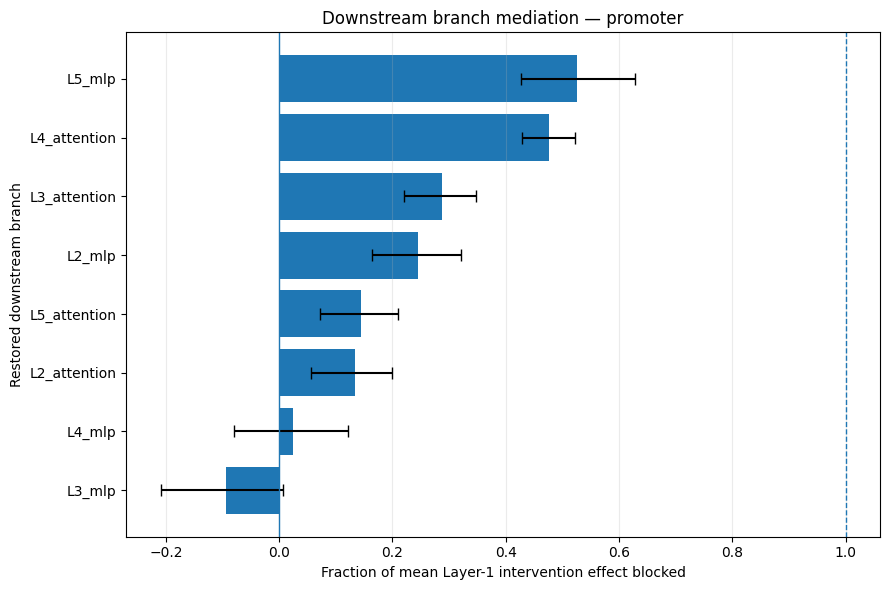

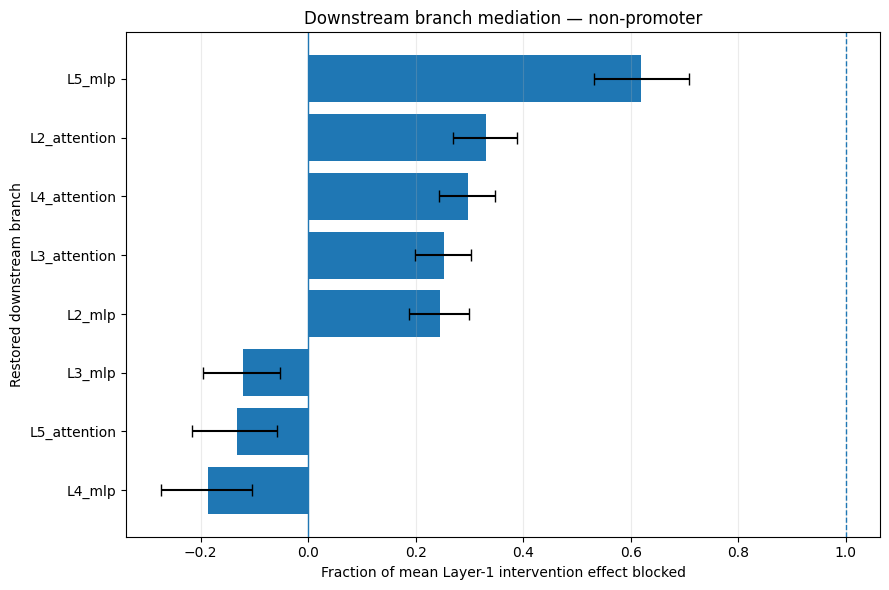

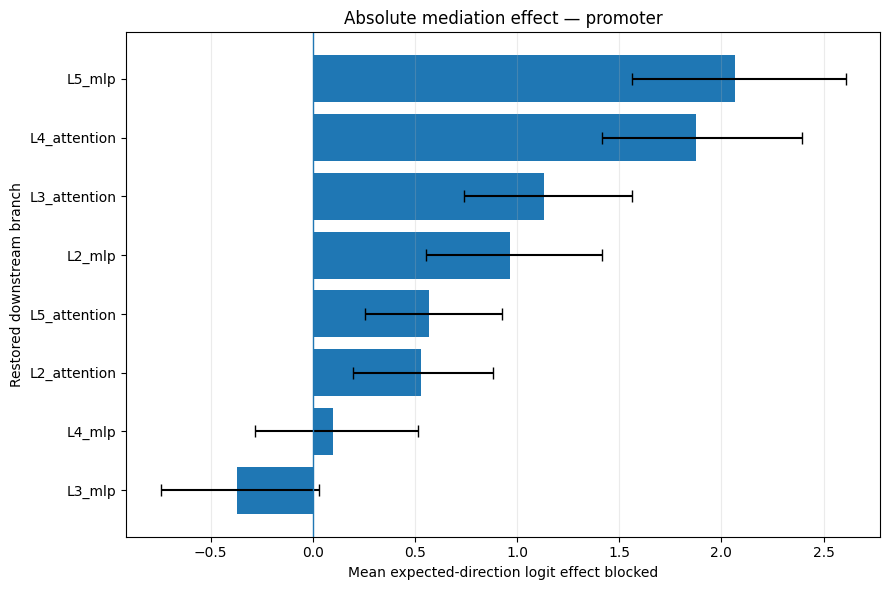

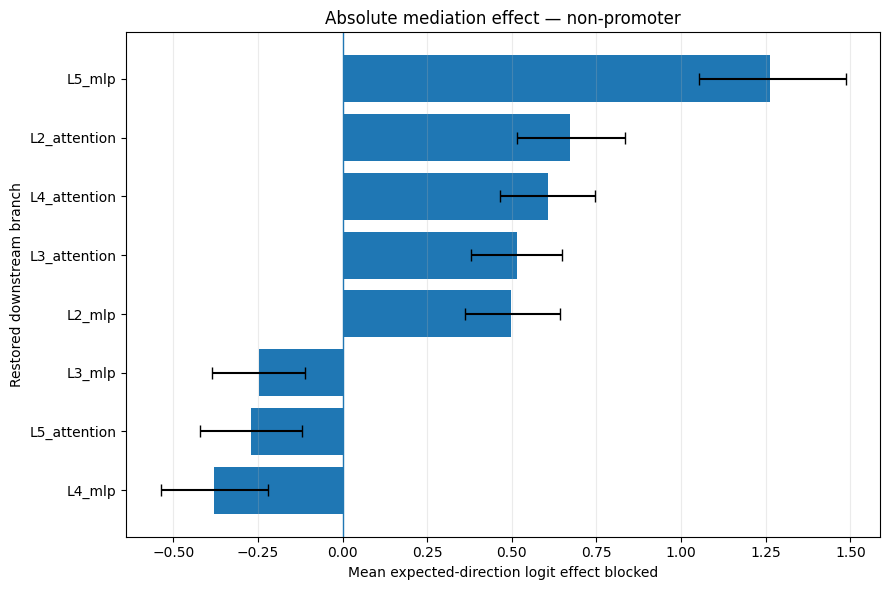


Saved mediation evidence
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/full_branch_mediation_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/expected_direction_mediation_ranking.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/combined_branch_mediation_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/branch_mediation_analysis_metadata.json

Cell 9 complete. Downstream branch mediation has been summarized with paired bootstrap confidence intervals.


In [22]:
# ============================================================
# Cell 9
# Bootstrap summary of full downstream branch mediation
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Analysis configuration
# ------------------------------------------------------------

MEDIATION_BOOTSTRAP_SEED = 43
MEDIATION_BOOTSTRAP_SAMPLES = 5000

mediation_rng = np.random.default_rng(
    MEDIATION_BOOTSTRAP_SEED
)


# Only branch-restoration conditions are relevant here.
branch_results = (
    full_branch_mediation_results.loc[
        full_branch_mediation_results[
            "restored_component"
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


print("=" * 80)
print("Full mediation analysis input")
print("=" * 80)

print(
    "Branch-restoration rows:",
    len(branch_results),
)

print(
    "Sequences per class:",
)

display(
    branch_results.groupby(
        "source_class"
    )[
        [
            "source_index"
        ]
    ]
    .nunique()
)


assert len(branch_results) == 378 * 8


# ------------------------------------------------------------
# Paired bootstrap for one component and one source class
# ------------------------------------------------------------

def paired_mediation_bootstrap(
    table: pd.DataFrame,
    *,
    number_of_samples: int = MEDIATION_BOOTSTRAP_SAMPLES,
) -> dict[str, float]:
    """
    Bootstrap sequences with replacement.

    Primary quantities:
      mean total effect
      mean blocked effect
      mean remaining effect
      ratio of mean blocked effect to mean total effect

    Expected-direction values are positive when the intervention
    moves the probe toward the opposite-class target.
    """
    total_effect = table[
        "total_intervention_effect"
    ].to_numpy(
        dtype=np.float64
    )

    blocked_effect = table[
        "blocked_effect"
    ].to_numpy(
        dtype=np.float64
    )

    remaining_effect = table[
        "remaining_effect"
    ].to_numpy(
        dtype=np.float64
    )

    expected_total = table[
        "expected_direction_total_effect"
    ].to_numpy(
        dtype=np.float64
    )

    expected_blocked = table[
        "expected_direction_blocked_effect"
    ].to_numpy(
        dtype=np.float64
    )

    expected_remaining = table[
        "expected_direction_remaining_effect"
    ].to_numpy(
        dtype=np.float64
    )

    branch_delta_norm = table[
        "branch_delta_norm"
    ].to_numpy(
        dtype=np.float64
    )

    number_of_sequences = len(table)

    sample_indices = mediation_rng.integers(
        low=0,
        high=number_of_sequences,
        size=(
            number_of_samples,
            number_of_sequences,
        ),
    )

    bootstrap_total_mean = (
        total_effect[
            sample_indices
        ].mean(axis=1)
    )

    bootstrap_blocked_mean = (
        blocked_effect[
            sample_indices
        ].mean(axis=1)
    )

    bootstrap_remaining_mean = (
        remaining_effect[
            sample_indices
        ].mean(axis=1)
    )

    bootstrap_expected_total_mean = (
        expected_total[
            sample_indices
        ].mean(axis=1)
    )

    bootstrap_expected_blocked_mean = (
        expected_blocked[
            sample_indices
        ].mean(axis=1)
    )

    bootstrap_expected_remaining_mean = (
        expected_remaining[
            sample_indices
        ].mean(axis=1)
    )

    valid_denominator = (
        np.abs(
            bootstrap_total_mean
        )
        > 1e-8
    )

    bootstrap_mediation_fraction = np.full(
        number_of_samples,
        np.nan,
        dtype=np.float64,
    )

    bootstrap_mediation_fraction[
        valid_denominator
    ] = (
        bootstrap_blocked_mean[
            valid_denominator
        ]
        /
        bootstrap_total_mean[
            valid_denominator
        ]
    )

    valid_expected_denominator = (
        np.abs(
            bootstrap_expected_total_mean
        )
        > 1e-8
    )

    bootstrap_expected_mediation_fraction = np.full(
        number_of_samples,
        np.nan,
        dtype=np.float64,
    )

    bootstrap_expected_mediation_fraction[
        valid_expected_denominator
    ] = (
        bootstrap_expected_blocked_mean[
            valid_expected_denominator
        ]
        /
        bootstrap_expected_total_mean[
            valid_expected_denominator
        ]
    )

    def interval(
        values: np.ndarray,
    ) -> tuple[float, float]:
        values = values[
            np.isfinite(values)
        ]

        return (
            float(
                np.quantile(
                    values,
                    0.025,
                )
            ),
            float(
                np.quantile(
                    values,
                    0.975,
                )
            ),
        )

    blocked_ci = interval(
        bootstrap_blocked_mean
    )

    remaining_ci = interval(
        bootstrap_remaining_mean
    )

    mediation_fraction_ci = interval(
        bootstrap_mediation_fraction
    )

    expected_blocked_ci = interval(
        bootstrap_expected_blocked_mean
    )

    expected_fraction_ci = interval(
        bootstrap_expected_mediation_fraction
    )

    mean_total_effect = float(
        total_effect.mean()
    )

    mean_blocked_effect = float(
        blocked_effect.mean()
    )

    mean_remaining_effect = float(
        remaining_effect.mean()
    )

    mean_expected_total_effect = float(
        expected_total.mean()
    )

    mean_expected_blocked_effect = float(
        expected_blocked.mean()
    )

    mean_expected_remaining_effect = float(
        expected_remaining.mean()
    )

    cohort_mediation_fraction = (
        mean_blocked_effect
        / mean_total_effect
        if abs(
            mean_total_effect
        ) > 1e-8
        else np.nan
    )

    expected_direction_mediation_fraction = (
        mean_expected_blocked_effect
        / mean_expected_total_effect
        if abs(
            mean_expected_total_effect
        ) > 1e-8
        else np.nan
    )

    return {
        "number_of_sequences": int(
            number_of_sequences
        ),
        "mean_total_effect": (
            mean_total_effect
        ),
        "mean_blocked_effect": (
            mean_blocked_effect
        ),
        "blocked_effect_ci_2.5": (
            blocked_ci[0]
        ),
        "blocked_effect_ci_97.5": (
            blocked_ci[1]
        ),
        "mean_remaining_effect": (
            mean_remaining_effect
        ),
        "remaining_effect_ci_2.5": (
            remaining_ci[0]
        ),
        "remaining_effect_ci_97.5": (
            remaining_ci[1]
        ),
        "cohort_mediation_fraction": (
            cohort_mediation_fraction
        ),
        "mediation_fraction_ci_2.5": (
            mediation_fraction_ci[0]
        ),
        "mediation_fraction_ci_97.5": (
            mediation_fraction_ci[1]
        ),
        "mean_expected_total_effect": (
            mean_expected_total_effect
        ),
        "mean_expected_blocked_effect": (
            mean_expected_blocked_effect
        ),
        "expected_blocked_ci_2.5": (
            expected_blocked_ci[0]
        ),
        "expected_blocked_ci_97.5": (
            expected_blocked_ci[1]
        ),
        "mean_expected_remaining_effect": (
            mean_expected_remaining_effect
        ),
        "expected_direction_mediation_fraction": (
            expected_direction_mediation_fraction
        ),
        "expected_fraction_ci_2.5": (
            expected_fraction_ci[0]
        ),
        "expected_fraction_ci_97.5": (
            expected_fraction_ci[1]
        ),
        "fraction_sequences_blocking_expected_effect": float(
            np.mean(
                expected_blocked
                > 0
            )
        ),
        "fraction_sequences_with_expected_total_effect": float(
            np.mean(
                expected_total
                > 0
            )
        ),
        "mean_branch_delta_norm": float(
            branch_delta_norm.mean()
        ),
        "median_branch_delta_norm": float(
            np.median(
                branch_delta_norm
            )
        ),
    }


# ------------------------------------------------------------
# Summarize every class × component pair
# ------------------------------------------------------------

mediation_summary_rows = []


for (
    source_class,
    restored_component,
), component_table in branch_results.groupby(
    [
        "source_class",
        "restored_component",
    ],
    sort=True,
):
    statistics = paired_mediation_bootstrap(
        component_table
    )

    mediation_summary_rows.append(
        {
            "source_class": (
                source_class
            ),
            "restored_component": (
                restored_component
            ),
            **statistics,
        }
    )


branch_mediation_summary = pd.DataFrame(
    mediation_summary_rows
)


# ------------------------------------------------------------
# Add interpretation categories
# ------------------------------------------------------------

def classify_mediation_row(
    row: pd.Series,
) -> str:
    lower = float(
        row[
            "expected_blocked_ci_2.5"
        ]
    )

    upper = float(
        row[
            "expected_blocked_ci_97.5"
        ]
    )

    fraction = float(
        row[
            "expected_direction_mediation_fraction"
        ]
    )

    if lower > 0:
        if fraction >= 0.75:
            return "strong positive mediation"

        if fraction >= 0.40:
            return "moderate positive mediation"

        return "partial positive mediation"

    if upper < 0:
        return "opposes or suppresses intervention effect"

    return "uncertain or heterogeneous effect"


branch_mediation_summary[
    "interpretation"
] = branch_mediation_summary.apply(
    classify_mediation_row,
    axis=1,
)


# Rank within each class by expected-direction mediation.
branch_mediation_summary[
    "class_rank"
] = (
    branch_mediation_summary.groupby(
        "source_class"
    )[
        "expected_direction_mediation_fraction"
    ]
    .rank(
        method="dense",
        ascending=False,
    )
    .astype(int)
)


branch_mediation_summary = (
    branch_mediation_summary
    .sort_values(
        [
            "source_class",
            "class_rank",
            "restored_component",
        ]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("Full branch-mediation summary")
print("=" * 80)

display(
    branch_mediation_summary[
        [
            "source_class",
            "class_rank",
            "restored_component",
            "mean_total_effect",
            "mean_blocked_effect",
            "blocked_effect_ci_2.5",
            "blocked_effect_ci_97.5",
            "cohort_mediation_fraction",
            "mediation_fraction_ci_2.5",
            "mediation_fraction_ci_97.5",
            "fraction_sequences_blocking_expected_effect",
            "mean_branch_delta_norm",
            "interpretation",
        ]
    ]
)


# ------------------------------------------------------------
# More intuitive expected-direction table
#
# Positive values mean the branch carried the desired
# opposite-class movement caused by the Layer-1 intervention.
# ------------------------------------------------------------

expected_direction_table = (
    branch_mediation_summary[
        [
            "source_class",
            "class_rank",
            "restored_component",
            "mean_expected_total_effect",
            "mean_expected_blocked_effect",
            "expected_blocked_ci_2.5",
            "expected_blocked_ci_97.5",
            "mean_expected_remaining_effect",
            "expected_direction_mediation_fraction",
            "expected_fraction_ci_2.5",
            "expected_fraction_ci_97.5",
            "fraction_sequences_blocking_expected_effect",
            "interpretation",
        ]
    ]
    .copy()
)


print("\n" + "=" * 80)
print("Expected-direction mediation ranking")
print("=" * 80)

display(
    expected_direction_table
)


# ------------------------------------------------------------
# Combined-class descriptive summary
#
# This is secondary because promoter and non-promoter effects
# differ substantially. We combine only after converting every
# effect into the expected direction.
# ------------------------------------------------------------

combined_summary_rows = []


for restored_component, component_table in (
    branch_results.groupby(
        "restored_component",
        sort=True,
    )
):
    expected_total = component_table[
        "expected_direction_total_effect"
    ].to_numpy(
        dtype=np.float64
    )

    expected_blocked = component_table[
        "expected_direction_blocked_effect"
    ].to_numpy(
        dtype=np.float64
    )

    expected_remaining = component_table[
        "expected_direction_remaining_effect"
    ].to_numpy(
        dtype=np.float64
    )

    mean_total = float(
        expected_total.mean()
    )

    mean_blocked = float(
        expected_blocked.mean()
    )

    combined_summary_rows.append(
        {
            "restored_component": (
                restored_component
            ),
            "number_of_sequences": int(
                len(
                    component_table
                )
            ),
            "mean_expected_total_effect": (
                mean_total
            ),
            "mean_expected_blocked_effect": (
                mean_blocked
            ),
            "mean_expected_remaining_effect": float(
                expected_remaining.mean()
            ),
            "combined_mediation_fraction": (
                mean_blocked
                / mean_total
                if abs(
                    mean_total
                ) > 1e-8
                else np.nan
            ),
            "fraction_sequences_blocking_expected_effect": float(
                np.mean(
                    expected_blocked
                    > 0
                )
            ),
            "mean_branch_delta_norm": float(
                component_table[
                    "branch_delta_norm"
                ].mean()
            ),
        }
    )


combined_branch_mediation_summary = pd.DataFrame(
    combined_summary_rows
).sort_values(
    "combined_mediation_fraction",
    ascending=False,
).reset_index(
    drop=True
)


print("\n" + "=" * 80)
print("Combined-class descriptive ranking")
print("=" * 80)

display(
    combined_branch_mediation_summary
)


# ------------------------------------------------------------
# Plot class-specific mediation fractions
# ------------------------------------------------------------

for source_class in [
    "promoter",
    "non-promoter",
]:
    plot_table = (
        branch_mediation_summary.loc[
            branch_mediation_summary[
                "source_class"
            ].eq(
                source_class
            )
        ]
        .sort_values(
            "expected_direction_mediation_fraction",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    values = plot_table[
        "expected_direction_mediation_fraction"
    ].to_numpy()

    lower_errors = (
        values
        - plot_table[
            "expected_fraction_ci_2.5"
        ].to_numpy()
    )

    upper_errors = (
        plot_table[
            "expected_fraction_ci_97.5"
        ].to_numpy()
        - values
    )

    figure, axis = plt.subplots(
        figsize=(
            9,
            6,
        )
    )

    axis.barh(
        plot_table[
            "restored_component"
        ],
        values,
        xerr=np.vstack(
            [
                lower_errors,
                upper_errors,
            ]
        ),
        capsize=4,
    )

    axis.axvline(
        0.0,
        linewidth=1,
    )

    axis.axvline(
        1.0,
        linewidth=1,
        linestyle="--",
    )

    axis.set_xlabel(
        "Fraction of mean Layer-1 intervention effect blocked"
    )

    axis.set_ylabel(
        "Restored downstream branch"
    )

    axis.set_title(
        f"Downstream branch mediation — {source_class}"
    )

    axis.grid(
        axis="x",
        alpha=0.25,
    )

    figure.tight_layout()

    output_path = (
        NOTEBOOK9_DIR
        / (
            "branch_mediation_fraction_"
            f"{source_class.replace('-', '_')}.png"
        )
    )

    figure.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        figure
    )


# ------------------------------------------------------------
# Plot mean expected-direction blocked effect
# ------------------------------------------------------------

for source_class in [
    "promoter",
    "non-promoter",
]:
    plot_table = (
        branch_mediation_summary.loc[
            branch_mediation_summary[
                "source_class"
            ].eq(
                source_class
            )
        ]
        .sort_values(
            "mean_expected_blocked_effect",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    values = plot_table[
        "mean_expected_blocked_effect"
    ].to_numpy()

    lower_errors = (
        values
        - plot_table[
            "expected_blocked_ci_2.5"
        ].to_numpy()
    )

    upper_errors = (
        plot_table[
            "expected_blocked_ci_97.5"
        ].to_numpy()
        - values
    )

    figure, axis = plt.subplots(
        figsize=(
            9,
            6,
        )
    )

    axis.barh(
        plot_table[
            "restored_component"
        ],
        values,
        xerr=np.vstack(
            [
                lower_errors,
                upper_errors,
            ]
        ),
        capsize=4,
    )

    axis.axvline(
        0.0,
        linewidth=1,
    )

    axis.set_xlabel(
        "Mean expected-direction logit effect blocked"
    )

    axis.set_ylabel(
        "Restored downstream branch"
    )

    axis.set_title(
        f"Absolute mediation effect — {source_class}"
    )

    axis.grid(
        axis="x",
        alpha=0.25,
    )

    figure.tight_layout()

    output_path = (
        NOTEBOOK9_DIR
        / (
            "branch_mediation_blocked_effect_"
            f"{source_class.replace('-', '_')}.png"
        )
    )

    figure.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        figure
    )


# ------------------------------------------------------------
# Save evidence tables
# ------------------------------------------------------------

BRANCH_MEDIATION_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "full_branch_mediation_summary.csv"
)

EXPECTED_DIRECTION_TABLE_PATH = (
    NOTEBOOK9_DIR
    / "expected_direction_mediation_ranking.csv"
)

COMBINED_MEDIATION_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "combined_branch_mediation_summary.csv"
)


branch_mediation_summary.to_csv(
    BRANCH_MEDIATION_SUMMARY_PATH,
    index=False,
)

expected_direction_table.to_csv(
    EXPECTED_DIRECTION_TABLE_PATH,
    index=False,
)

combined_branch_mediation_summary.to_csv(
    COMBINED_MEDIATION_SUMMARY_PATH,
    index=False,
)


# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

mediation_analysis_metadata = {
    "bootstrap_seed": (
        MEDIATION_BOOTSTRAP_SEED
    ),
    "number_of_bootstrap_samples": (
        MEDIATION_BOOTSTRAP_SAMPLES
    ),
    "number_of_sequences": int(
        len(
            clean_sources
        )
    ),
    "number_of_components": int(
        len(
            DOWNSTREAM_BRANCH_MODULES
        )
    ),
    "primary_statistic": (
        "ratio of bootstrap mean blocked effect to "
        "bootstrap mean total intervention effect"
    ),
    "important_limitation": (
        "Restoring one branch to its clean output tests "
        "whether the branch transmits the intervention-induced "
        "difference, but correlated or redundant pathways can "
        "cause mediation fractions to overlap or exceed one."
    ),
}


MEDIATION_METADATA_PATH = (
    NOTEBOOK9_DIR
    / "branch_mediation_analysis_metadata.json"
)


with open(
    MEDIATION_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        mediation_analysis_metadata,
        file,
        indent=2,
    )


print("\n" + "=" * 80)
print("Saved mediation evidence")
print("=" * 80)

for path in [
    BRANCH_MEDIATION_SUMMARY_PATH,
    EXPECTED_DIRECTION_TABLE_PATH,
    COMBINED_MEDIATION_SUMMARY_PATH,
    MEDIATION_METADATA_PATH,
]:
    print(path)


print(
    "\nCell 9 complete. Downstream branch mediation has "
    "been summarized with paired bootstrap confidence "
    "intervals."
)

In [23]:
# ============================================================
# Cell 10
# Joint downstream branch-mediation scan
#
# Test whether individually identified branches form:
#   - a serial pathway,
#   - redundant/overlapping routes,
#   - or a distributed compensatory system.
# ============================================================

from __future__ import annotations

import gc
import time
from collections import OrderedDict
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Joint restoration conditions
# ------------------------------------------------------------

JOINT_RESTORE_CONDITIONS = OrderedDict(
    {
        "intervention_only": tuple(),

        "L2_attention_plus_L2_mlp": (
            "L2_attention",
            "L2_mlp",
        ),

        "attention_spine_L2_to_L4": (
            "L2_attention",
            "L3_attention",
            "L4_attention",
        ),

        "L4_attention_plus_L5_mlp": (
            "L4_attention",
            "L5_mlp",
        ),

        "positive_candidate_pathway": (
            "L2_attention",
            "L2_mlp",
            "L3_attention",
            "L4_attention",
            "L5_mlp",
        ),

        "positive_pathway_plus_L5_attention": (
            "L2_attention",
            "L2_mlp",
            "L3_attention",
            "L4_attention",
            "L5_attention",
            "L5_mlp",
        ),

        "all_downstream_branches": tuple(
            DOWNSTREAM_BRANCH_MODULES.keys()
        ),
    }
)


print("=" * 80)
print("Joint restoration conditions")
print("=" * 80)

for condition_name, components in (
    JOINT_RESTORE_CONDITIONS.items()
):
    print(
        f"{condition_name:38s}",
        list(components),
    )


# ------------------------------------------------------------
# Multi-branch restoration runner
# ------------------------------------------------------------

def run_layer1_intervention_with_multiple_restores(
    sequence: str,
    shift_vector: np.ndarray,
    *,
    restore_component_names: tuple[str, ...],
    clean_branch_outputs: dict[str, torch.Tensor],
) -> dict[str, Any]:
    """
    Apply the Layer-1 MLP subspace intervention and restore
    zero or more downstream branch-contribution tensors to
    their sequence-matched clean values.
    """
    captured = {
        "branch_before_restore": {},
        "branch_after_restore": {},
    }

    shift_tensor = torch.as_tensor(
        shift_vector,
        dtype=next(
            model.parameters()
        ).dtype,
        device=DEVICE,
    )

    handles = []


    # --------------------------------------------------------
    # Layer-1 intervention
    # --------------------------------------------------------

    def layer1_intervention_hook(
        module,
        inputs,
        output,
    ):
        output_tensor = (
            extract_tensor_from_output(
                output
            )
        )

        if output_tensor.ndim != 2:
            raise ValueError(
                "Expected Layer-1 MLP output with shape "
                "(tokens, hidden_size)."
            )

        modified_output = (
            output_tensor.clone()
        )

        modified_output[
            1:-1
        ] = (
            modified_output[
                1:-1
            ]
            + shift_tensor
        )

        captured[
            "layer1_before"
        ] = (
            output_tensor.detach().clone()
        )

        captured[
            "layer1_after"
        ] = (
            modified_output.detach().clone()
        )

        return replace_tensor_in_output(
            output,
            modified_output,
        )


    handles.append(
        layer1_mlp_output_module.register_forward_hook(
            layer1_intervention_hook
        )
    )


    # --------------------------------------------------------
    # Downstream clean restorations
    #
    # Hooks execute in normal forward order because the target
    # modules are encountered sequentially in the model.
    # --------------------------------------------------------

    for component_name in restore_component_names:
        if component_name not in DOWNSTREAM_BRANCH_MODULES:
            raise KeyError(
                f"Unknown component: {component_name}"
            )

        target_module = (
            DOWNSTREAM_BRANCH_MODULES[
                component_name
            ]
        )

        clean_target_output = (
            clean_branch_outputs[
                component_name
            ]
        )


        def make_restore_hook(
            stored_component_name: str,
            stored_clean_output: torch.Tensor,
        ):
            def restore_hook(
                module,
                inputs,
                output,
            ):
                intervened_output = (
                    extract_tensor_from_output(
                        output
                    )
                )

                if (
                    intervened_output.shape
                    != stored_clean_output.shape
                ):
                    raise ValueError(
                        f"Shape mismatch for "
                        f"{stored_component_name}: "
                        f"{tuple(intervened_output.shape)} vs "
                        f"{tuple(stored_clean_output.shape)}"
                    )

                restored_output = (
                    stored_clean_output
                    .to(
                        device=intervened_output.device,
                        dtype=intervened_output.dtype,
                    )
                    .clone()
                )

                captured[
                    "branch_before_restore"
                ][
                    stored_component_name
                ] = (
                    intervened_output.detach().clone()
                )

                captured[
                    "branch_after_restore"
                ][
                    stored_component_name
                ] = (
                    restored_output.detach().clone()
                )

                return replace_tensor_in_output(
                    output,
                    restored_output,
                )

            return restore_hook


        handles.append(
            target_module.register_forward_hook(
                make_restore_hook(
                    component_name,
                    clean_target_output,
                )
            )
        )


    # --------------------------------------------------------
    # Capture Layer-5 representation
    # --------------------------------------------------------

    def layer5_capture_hook(
        module,
        inputs,
        output,
    ):
        captured[
            "layer5"
        ] = (
            extract_tensor_from_output(
                output
            )
            .detach()
            .clone()
        )


    handles.append(
        layer5_block_module.register_forward_hook(
            layer5_capture_hook
        )
    )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        for handle in handles:
            handle.remove()


    if (
        len(
            captured[
                "branch_before_restore"
            ]
        )
        != len(
            restore_component_names
        )
    ):
        raise RuntimeError(
            "Not every requested branch was restored."
        )


    return captured


# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

JOINT_MEDIATION_CHECKPOINT_PATH = (
    NOTEBOOK9_DIR
    / "joint_branch_mediation_checkpoint.pkl"
)

JOINT_MEDIATION_RESULTS_PATH = (
    NOTEBOOK9_DIR
    / "joint_branch_mediation_results.csv"
)

JOINT_MEDIATION_RESULTS_PICKLE_PATH = (
    NOTEBOOK9_DIR
    / "joint_branch_mediation_results.pkl"
)


# ------------------------------------------------------------
# Resume support
# ------------------------------------------------------------

if JOINT_MEDIATION_CHECKPOINT_PATH.exists():
    prior_joint_results = pd.read_pickle(
        JOINT_MEDIATION_CHECKPOINT_PATH
    )

    joint_mediation_rows = (
        prior_joint_results.to_dict(
            orient="records"
        )
    )

    completed_joint_run_ids = set(
        prior_joint_results[
            "run_id"
        ].astype(str)
    )

    print(
        "\nLoaded joint checkpoint rows:",
        len(
            prior_joint_results
        ),
    )

else:
    joint_mediation_rows = []
    completed_joint_run_ids = set()

    print(
        "\nNo joint mediation checkpoint found."
    )


expected_joint_rows = (
    len(
        clean_sources
    )
    * len(
        JOINT_RESTORE_CONDITIONS
    )
)


print("\n" + "=" * 80)
print("Joint branch-mediation scan")
print("=" * 80)

print(
    "Sequences:",
    len(
        clean_sources
    ),
)

print(
    "Conditions per sequence:",
    len(
        JOINT_RESTORE_CONDITIONS
    ),
)

print(
    "Expected rows:",
    expected_joint_rows,
)


# ------------------------------------------------------------
# Execute scan
# ------------------------------------------------------------

scan_start_time = time.time()
new_sequences_completed = 0


for source_position, source_row in (
    clean_sources.reset_index(
        drop=True
    ).iterrows()
):
    source_class = str(
        source_row[
            "source_class"
        ]
    )

    source_index = int(
        source_row[
            "source_index"
        ]
        if "source_index"
        in source_row.index
        else source_position
    )

    sequence = str(
        source_row[
            sequence_column
        ]
    )


    sequence_run_ids = {
        (
            f"{source_class}|"
            f"{source_index}|"
            f"{condition_name}"
        )
        for condition_name in (
            JOINT_RESTORE_CONDITIONS.keys()
        )
    }


    if sequence_run_ids.issubset(
        completed_joint_run_ids
    ):
        continue


    # --------------------------------------------------------
    # Clean branch and Layer-5 capture
    # --------------------------------------------------------

    clean_capture = (
        run_clean_branch_capture(
            sequence
        )
    )


    clean_logit = (
        probe_logit_from_layer5_tokens(
            clean_capture[
                "layer5"
            ]
        )
    )


    # --------------------------------------------------------
    # Capture clean Layer-1 MLP activation
    # --------------------------------------------------------

    clean_layer1_capture = {}


    def joint_clean_layer1_hook(
        module,
        inputs,
        output,
    ):
        clean_layer1_capture[
            "activation"
        ] = (
            extract_tensor_from_output(
                output
            )
            .detach()
            .clone()
        )


    clean_layer1_handle = (
        layer1_mlp_output_module.register_forward_hook(
            joint_clean_layer1_hook
        )
    )


    try:
        with torch.inference_mode():
            encoded = tokenize_sequences(
                [
                    sequence
                ]
            )

            _ = model(
                **encoded,
                return_dict=False,
            )

    finally:
        clean_layer1_handle.remove()


    (
        shift_vector,
        original_coordinates,
        target_coordinates,
    ) = compute_opposite_class_shift(
        clean_layer1_capture[
            "activation"
        ],
        promoter_direction_specification,
        source_class,
    )


    # --------------------------------------------------------
    # Intervention-only reference
    # --------------------------------------------------------

    intervention_capture = (
        run_layer1_intervention_with_multiple_restores(
            sequence,
            shift_vector,
            restore_component_names=tuple(),
            clean_branch_outputs=(
                clean_capture[
                    "branches"
                ]
            ),
        )
    )


    intervention_logit = (
        probe_logit_from_layer5_tokens(
            intervention_capture[
                "layer5"
            ]
        )
    )


    total_intervention_effect = (
        intervention_logit
        - clean_logit
    )


    expected_sign = (
        -1.0
        if source_class == "promoter"
        else 1.0
    )


    # --------------------------------------------------------
    # Run every joint restoration condition
    # --------------------------------------------------------

    for condition_name, restore_components in (
        JOINT_RESTORE_CONDITIONS.items()
    ):
        run_id = (
            f"{source_class}|"
            f"{source_index}|"
            f"{condition_name}"
        )


        if run_id in completed_joint_run_ids:
            continue


        if condition_name == "intervention_only":
            condition_capture = (
                intervention_capture
            )

            condition_logit = (
                intervention_logit
            )

            summed_branch_delta_norm = np.nan

        else:
            condition_capture = (
                run_layer1_intervention_with_multiple_restores(
                    sequence,
                    shift_vector,
                    restore_component_names=(
                        restore_components
                    ),
                    clean_branch_outputs=(
                        clean_capture[
                            "branches"
                        ]
                    ),
                )
            )

            condition_logit = (
                probe_logit_from_layer5_tokens(
                    condition_capture[
                        "layer5"
                    ]
                )
            )

            branch_delta_norms = [
                float(
                    torch.linalg.vector_norm(
                        condition_capture[
                            "branch_before_restore"
                        ][
                            component_name
                        ]
                        -
                        condition_capture[
                            "branch_after_restore"
                        ][
                            component_name
                        ]
                    ).item()
                )
                for component_name in restore_components
            ]

            summed_branch_delta_norm = float(
                np.sum(
                    branch_delta_norms
                )
            )


        remaining_effect = (
            condition_logit
            - clean_logit
        )

        blocked_effect = (
            intervention_logit
            - condition_logit
        )


        if abs(
            total_intervention_effect
        ) > 1e-8:
            fraction_effect_blocked = (
                blocked_effect
                / total_intervention_effect
            )
        else:
            fraction_effect_blocked = np.nan


        joint_mediation_rows.append(
            {
                "run_id": run_id,
                "source_position": int(
                    source_position
                ),
                "source_index": int(
                    source_index
                ),
                "source_class": (
                    source_class
                ),
                "condition_name": (
                    condition_name
                ),
                "restored_components": (
                    "|".join(
                        restore_components
                    )
                ),
                "number_of_restored_components": int(
                    len(
                        restore_components
                    )
                ),
                "clean_logit": float(
                    clean_logit
                ),
                "intervention_logit": float(
                    intervention_logit
                ),
                "condition_logit": float(
                    condition_logit
                ),
                "total_intervention_effect": float(
                    total_intervention_effect
                ),
                "remaining_effect": float(
                    remaining_effect
                ),
                "blocked_effect": float(
                    blocked_effect
                ),
                "fraction_effect_blocked": float(
                    fraction_effect_blocked
                ),
                "expected_direction_total_effect": float(
                    expected_sign
                    * total_intervention_effect
                ),
                "expected_direction_remaining_effect": float(
                    expected_sign
                    * remaining_effect
                ),
                "expected_direction_blocked_effect": float(
                    expected_sign
                    * blocked_effect
                ),
                "summed_branch_delta_norm": (
                    summed_branch_delta_norm
                ),
                "requested_shift_norm": float(
                    np.linalg.norm(
                        shift_vector
                    )
                ),
                "original_coordinate": float(
                    original_coordinates[
                        0
                    ]
                ),
                "target_coordinate": float(
                    target_coordinates[
                        0
                    ]
                ),
            }
        )


        completed_joint_run_ids.add(
            run_id
        )


    new_sequences_completed += 1


    if (
        new_sequences_completed
        % 25
        == 0
    ):
        checkpoint_table = pd.DataFrame(
            joint_mediation_rows
        )

        checkpoint_table.to_pickle(
            JOINT_MEDIATION_CHECKPOINT_PATH
        )

        elapsed = (
            time.time()
            - scan_start_time
        )

        print(
            f"Completed "
            f"{new_sequences_completed} new sequences; "
            f"{len(checkpoint_table)}/"
            f"{expected_joint_rows} rows saved. "
            f"Elapsed: {elapsed:.1f} seconds."
        )

        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Finalize and validate
# ------------------------------------------------------------

joint_branch_mediation_results = pd.DataFrame(
    joint_mediation_rows
)


joint_branch_mediation_results = (
    joint_branch_mediation_results
    .drop_duplicates(
        subset="run_id",
        keep="last",
    )
    .sort_values(
        [
            "source_class",
            "source_index",
            "number_of_restored_components",
            "condition_name",
        ]
    )
    .reset_index(drop=True)
)


conditions_per_sequence = (
    joint_branch_mediation_results.groupby(
        [
            "source_class",
            "source_index",
        ]
    )[
        "condition_name"
    ]
    .nunique()
)


clean_logit_ranges = (
    joint_branch_mediation_results.groupby(
        [
            "source_class",
            "source_index",
        ]
    )[
        "clean_logit"
    ]
    .agg(
        lambda values: float(
            values.max()
            - values.min()
        )
    )
)


intervention_logit_ranges = (
    joint_branch_mediation_results.groupby(
        [
            "source_class",
            "source_index",
        ]
    )[
        "intervention_logit"
    ]
    .agg(
        lambda values: float(
            values.max()
            - values.min()
        )
    )
)


print("\n" + "=" * 80)
print("Joint mediation validation")
print("=" * 80)

print(
    "Expected rows:",
    expected_joint_rows,
)

print(
    "Actual rows:",
    len(
        joint_branch_mediation_results
    ),
)

print(
    "Duplicate run IDs:",
    int(
        joint_branch_mediation_results[
            "run_id"
        ].duplicated().sum()
    ),
)

print(
    "Minimum conditions per sequence:",
    int(
        conditions_per_sequence.min()
    ),
)

print(
    "Maximum conditions per sequence:",
    int(
        conditions_per_sequence.max()
    ),
)

print(
    "Maximum clean-logit range:",
    float(
        clean_logit_ranges.max()
    ),
)

print(
    "Maximum intervention-logit range:",
    float(
        intervention_logit_ranges.max()
    ),
)


assert (
    len(
        joint_branch_mediation_results
    )
    == expected_joint_rows
)

assert (
    joint_branch_mediation_results[
        "run_id"
    ].duplicated().sum()
    == 0
)

assert (
    conditions_per_sequence.min()
    == len(
        JOINT_RESTORE_CONDITIONS
    )
)

assert (
    conditions_per_sequence.max()
    == len(
        JOINT_RESTORE_CONDITIONS
    )
)

assert clean_logit_ranges.max() < 1e-10
assert intervention_logit_ranges.max() < 1e-10


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

joint_branch_mediation_results.to_csv(
    JOINT_MEDIATION_RESULTS_PATH,
    index=False,
)

joint_branch_mediation_results.to_pickle(
    JOINT_MEDIATION_RESULTS_PICKLE_PATH
)

joint_branch_mediation_results.to_pickle(
    JOINT_MEDIATION_CHECKPOINT_PATH
)


elapsed_total = (
    time.time()
    - scan_start_time
)


print("\nSaved:")
print(
    JOINT_MEDIATION_RESULTS_PATH
)

print(
    JOINT_MEDIATION_RESULTS_PICKLE_PATH
)

print(
    JOINT_MEDIATION_CHECKPOINT_PATH
)

print(
    "\nTotal scan time:",
    elapsed_total,
    "seconds",
)

print(
    "\nCell 10 complete. Joint restoration of candidate "
    "downstream pathways has been evaluated across the "
    "full cohort."
)

Joint restoration conditions
intervention_only                      []
L2_attention_plus_L2_mlp               ['L2_attention', 'L2_mlp']
attention_spine_L2_to_L4               ['L2_attention', 'L3_attention', 'L4_attention']
L4_attention_plus_L5_mlp               ['L4_attention', 'L5_mlp']
positive_candidate_pathway             ['L2_attention', 'L2_mlp', 'L3_attention', 'L4_attention', 'L5_mlp']
positive_pathway_plus_L5_attention     ['L2_attention', 'L2_mlp', 'L3_attention', 'L4_attention', 'L5_attention', 'L5_mlp']
all_downstream_branches                ['L2_attention', 'L2_mlp', 'L3_attention', 'L3_mlp', 'L4_attention', 'L4_mlp', 'L5_attention', 'L5_mlp']

No joint mediation checkpoint found.

Joint branch-mediation scan
Sequences: 378
Conditions per sequence: 7
Expected rows: 2646
Completed 25 new sequences; 175/2646 rows saved. Elapsed: 4.0 seconds.
Completed 50 new sequences; 350/2646 rows saved. Elapsed: 8.3 seconds.
Completed 75 new sequences; 525/2646 rows saved. Elapsed: 11.9

Joint interaction analysis input
Rows: 2646


,source_class,source_index,condition_name,restored_components,number_of_restored_components,expected_direction_total_effect,joint_expected_blocked_effect,joint_expected_remaining_effect,sum_individual_expected_blocked_effects,interaction_effect,joint_mediation_fraction,additive_expected_fraction,interaction_fraction
0,non-promoter,0,intervention_only,,0,0.262753,0.000000,0.262753,0.000000,0.000000,0.000000,0.000000,0.000000
1,non-promoter,0,L2_attention_plus_L2_mlp,L2_attention|L2_mlp,2,0.262753,-0.006615,0.269368,-0.117946,0.111331,-0.025177,-0.448887,0.423710
2,non-promoter,0,L4_attention_plus_L5_mlp,L4_attention|L5_mlp,2,0.262753,0.154566,0.108187,-0.548746,0.703312,0.588256,-2.088448,2.676703
3,non-promoter,0,attention_spine_L2_to_L4,L2_attention|L3_attention|L4_attention,3,0.262753,-0.334644,0.597397,0.875360,-1.210005,-1.273609,3.331496,-4.605105
4,non-promoter,0,positive_candidate_pathway,L2_attention|L2_mlp|L3_attention|L4_attention|L5_mlp,5,0.262753,-0.311725,0.574478,-0.241120,-0.070606,-1.186382,-0.917667,-0.268715
5,non-promoter,0,positive_pathway_plus_L5_attention,L2_attention|L2_mlp|L3_attention|L4_attention|L5_attention|L5_mlp,6,0.262753,-0.511366,0.774119,-1.002468,0.491102,-1.946187,-3.815251,1.869063
6,non-promoter,0,all_downstream_branches,L2_attention|L2_mlp|L3_attention|L3_mlp|L4_attention|L4_mlp|L5_attention|L5_mlp,8,0.262753,-0.528400,0.791153,-2.018732,1.490333,-2.011014,-7.683008,5.671993
7,non-promoter,1,intervention_only,,0,1.142688,0.000000,1.142688,0.000000,0.000000,0.000000,0.000000,0.000000
8,non-promoter,1,L2_attention_plus_L2_mlp,L2_attention|L2_mlp,2,1.142688,0.578020,0.564667,1.149120,-0.571099,0.505843,1.005629,-0.499786
9,non-promoter,1,L4_attention_plus_L5_mlp,L4_attention|L5_mlp,2,1.142688,0.347303,0.795385,0.491660,-0.144357,0.303935,0.430266,-0.126331



Joint mediation summary


,source_class,class_rank,condition_name,number_of_components,mean_expected_total_effect,mean_joint_blocked_effect,joint_blocked_ci_2.5,joint_blocked_ci_97.5,joint_mediation_fraction,joint_fraction_ci_2.5,joint_fraction_ci_97.5,mean_joint_remaining_effect,fraction_sequences_blocking_expected_effect,fraction_sequences_near_complete_block,fraction_sequences_overcorrecting,interaction_interpretation
0,non-promoter,1,L4_attention_plus_L5_mlp,2,2.035187,1.402583,1.206120,1.595998,0.689167,0.635131,0.744068,0.632604,0.857143,0.253968,0.148148,"sub-additive: overlapping, redundant, or serial mediation"
1,non-promoter,2,all_downstream_branches,8,2.035187,1.073864,0.899392,1.250772,0.527649,0.485234,0.562942,0.961323,0.798942,0.026455,0.026455,"sub-additive: overlapping, redundant, or serial mediation"
2,non-promoter,3,positive_pathway_plus_L5_attention,6,2.035187,0.892148,0.715789,1.062737,0.438362,0.386198,0.482857,1.143039,0.756614,0.026455,0.026455,"sub-additive: overlapping, redundant, or serial mediation"
3,non-promoter,4,positive_candidate_pathway,5,2.035187,0.806090,0.632170,0.982334,0.396076,0.338491,0.444694,1.229098,0.735450,0.026455,0.026455,"sub-additive: overlapping, redundant, or serial mediation"
4,non-promoter,5,L2_attention_plus_L2_mlp,2,2.035187,0.697072,0.525396,0.876617,0.342510,0.277526,0.404764,1.338115,0.724868,0.037037,0.026455,"sub-additive: overlapping, redundant, or serial mediation"
5,non-promoter,6,attention_spine_L2_to_L4,3,2.035187,0.554825,0.394053,0.709853,0.272616,0.211119,0.324346,1.480362,0.677249,0.031746,0.026455,"sub-additive: overlapping, redundant, or serial mediation"
6,promoter,1,L4_attention_plus_L5_mlp,2,3.937716,2.742775,2.165158,3.372437,0.696539,0.645952,0.747910,1.194942,0.719577,0.253968,0.190476,"sub-additive: overlapping, redundant, or serial mediation"
7,promoter,2,all_downstream_branches,8,3.937716,2.688635,2.052129,3.377472,0.682791,0.643616,0.712839,1.249081,0.693122,0.047619,0.047619,"sub-additive: overlapping, redundant, or serial mediation"
8,promoter,3,positive_candidate_pathway,5,3.937716,2.589318,1.957609,3.276596,0.657568,0.614292,0.694295,1.348399,0.708995,0.052910,0.047619,"sub-additive: overlapping, redundant, or serial mediation"
9,promoter,4,attention_spine_L2_to_L4,3,3.937716,2.548418,1.908015,3.265139,0.647182,0.593531,0.693563,1.389299,0.677249,0.068783,0.052910,"sub-additive: overlapping, redundant, or serial mediation"



Joint versus summed-individual effects


,source_class,condition_name,restored_components,mean_joint_blocked_effect,mean_sum_individual_blocked_effects,mean_interaction_effect,interaction_ci_2.5,interaction_ci_97.5,joint_mediation_fraction,additive_expected_fraction,interaction_fraction,interaction_fraction_ci_2.5,interaction_fraction_ci_97.5,interaction_interpretation
0,non-promoter,L4_attention_plus_L5_mlp,L4_attention|L5_mlp,1.402583,1.867851,-0.465268,-0.629272,-0.301782,0.689167,0.917779,-0.228612,-0.304175,-0.153537,"sub-additive: overlapping, redundant, or serial mediation"
1,non-promoter,all_downstream_branches,L2_attention|L2_mlp|L3_attention|L3_mlp|L4_attention|L4_mlp|L5_attention|L5_mlp,1.073864,2.655911,-1.582047,-2.260658,-0.879280,0.527649,1.304996,-0.777347,-1.050902,-0.459336,"sub-additive: overlapping, redundant, or serial mediation"
2,non-promoter,positive_pathway_plus_L5_attention,L2_attention|L2_mlp|L3_attention|L4_attention|L5_attention|L5_mlp,0.892148,3.282656,-2.390508,-2.903078,-1.867547,0.438362,1.612950,-1.174589,-1.343372,-0.981725,"sub-additive: overlapping, redundant, or serial mediation"
3,non-promoter,positive_candidate_pathway,L2_attention|L2_mlp|L3_attention|L4_attention|L5_mlp,0.806090,3.552239,-2.746150,-3.218069,-2.299486,0.396076,1.745412,-1.349335,-1.490110,-1.202638,"sub-additive: overlapping, redundant, or serial mediation"
4,non-promoter,L2_attention_plus_L2_mlp,L2_attention|L2_mlp,0.697072,1.170499,-0.473427,-0.602928,-0.346105,0.342510,0.575131,-0.232621,-0.282492,-0.179734,"sub-additive: overlapping, redundant, or serial mediation"
5,non-promoter,attention_spine_L2_to_L4,L2_attention|L3_attention|L4_attention,0.554825,1.791923,-1.237098,-1.479557,-0.980500,0.272616,0.880471,-0.607855,-0.700401,-0.511624,"sub-additive: overlapping, redundant, or serial mediation"
6,promoter,L4_attention_plus_L5_mlp,L4_attention|L5_mlp,2.742775,3.942962,-1.200187,-1.573689,-0.846283,0.696539,1.001332,-0.304793,-0.378877,-0.229031,"sub-additive: overlapping, redundant, or serial mediation"
7,promoter,all_downstream_branches,L2_attention|L2_mlp|L3_attention|L3_mlp|L4_attention|L4_mlp|L5_attention|L5_mlp,2.688635,6.867822,-4.179186,-6.345398,-2.232173,0.682791,1.744113,-1.061322,-1.429147,-0.659533,"sub-additive: overlapping, redundant, or serial mediation"
8,promoter,positive_candidate_pathway,L2_attention|L2_mlp|L3_attention|L4_attention|L5_mlp,2.589318,6.571110,-3.981793,-5.366124,-2.706654,0.657568,1.668762,-1.011193,-1.207275,-0.799775,"sub-additive: overlapping, redundant, or serial mediation"
9,promoter,attention_spine_L2_to_L4,L2_attention|L3_attention|L4_attention,2.548418,3.536422,-0.988004,-1.603209,-0.407874,0.647182,0.898090,-0.250908,-0.366146,-0.115663,"sub-additive: overlapping, redundant, or serial mediation"



Combined-class joint mediation ranking


,condition_name,restored_components,number_of_components,number_of_sequences,mean_expected_total_effect,mean_joint_blocked_effect,mean_sum_individual_blocked_effects,mean_interaction_effect,combined_joint_mediation_fraction,combined_additive_expected_fraction,combined_interaction_fraction,fraction_sequences_blocking_expected_effect,fraction_sequences_near_complete_block
0,L4_attention_plus_L5_mlp,L4_attention|L5_mlp,2,378,2.986452,2.072679,2.905406,-0.832728,0.694027,0.972862,-0.278835,0.788360,0.253968
1,all_downstream_branches,L2_attention|L2_mlp|L3_attention|L3_mlp|L4_attention|L4_mlp|L5_attention|L5_mlp,8,378,2.986452,1.881250,4.761866,-2.880617,0.629928,1.594490,-0.964562,0.746032,0.037037
2,positive_candidate_pathway,L2_attention|L2_mlp|L3_attention|L4_attention|L5_mlp,5,378,2.986452,1.697704,5.061675,-3.363971,0.568468,1.694879,-1.126411,0.722222,0.039683
3,positive_pathway_plus_L5_attention,L2_attention|L2_mlp|L3_attention|L4_attention|L5_attention|L5_mlp,6,378,2.986452,1.603888,5.211301,-3.607413,0.537055,1.744981,-1.207926,0.716931,0.039683
4,attention_spine_L2_to_L4,L2_attention|L3_attention|L4_attention,3,378,2.986452,1.551621,2.664172,-1.112551,0.519553,0.892086,-0.372533,0.677249,0.050265
5,L2_attention_plus_L2_mlp,L2_attention|L2_mlp,2,378,2.986452,0.867270,1.332679,-0.465408,0.290402,0.446241,-0.155840,0.642857,0.050265


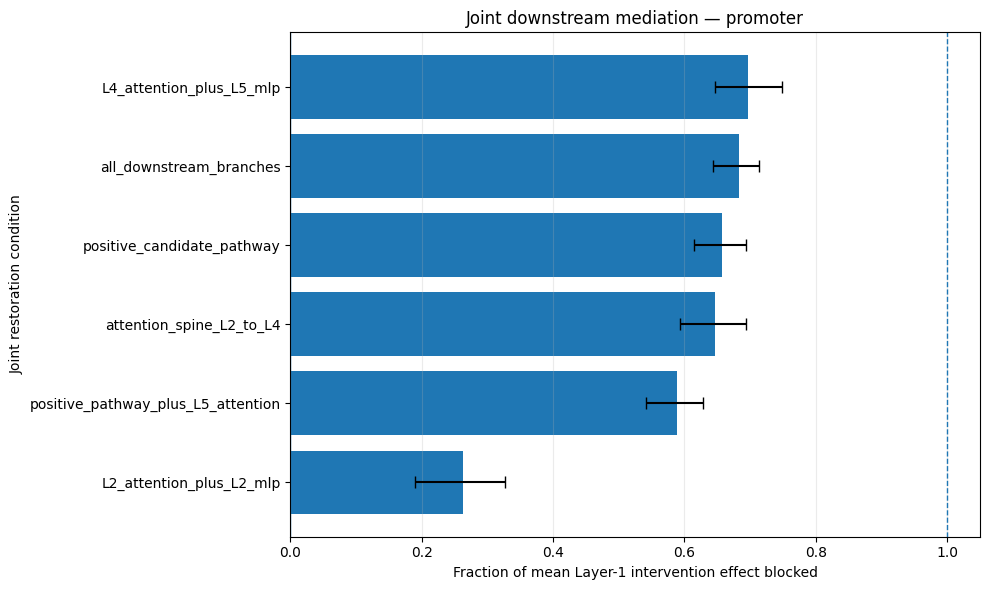

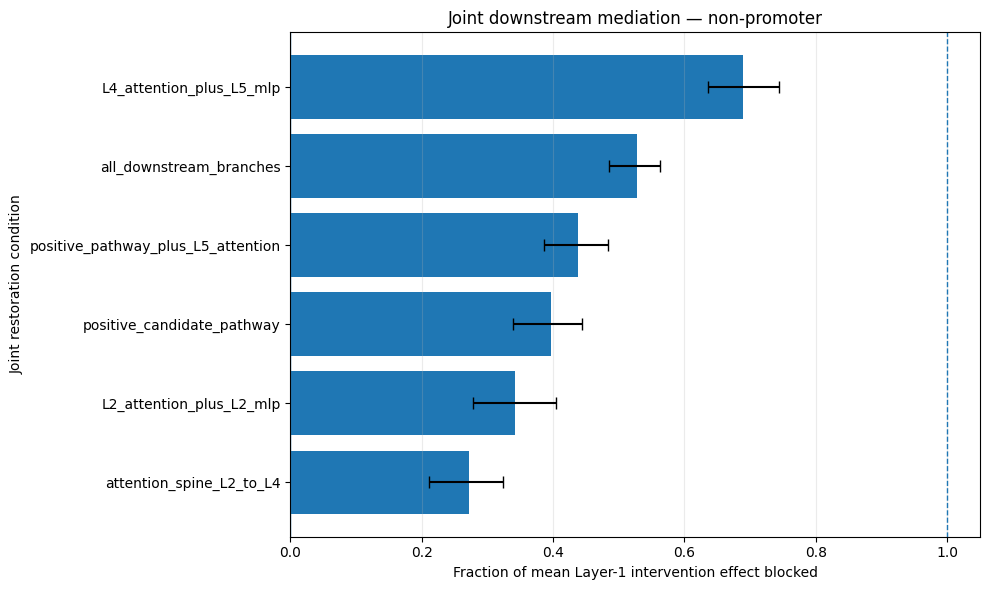

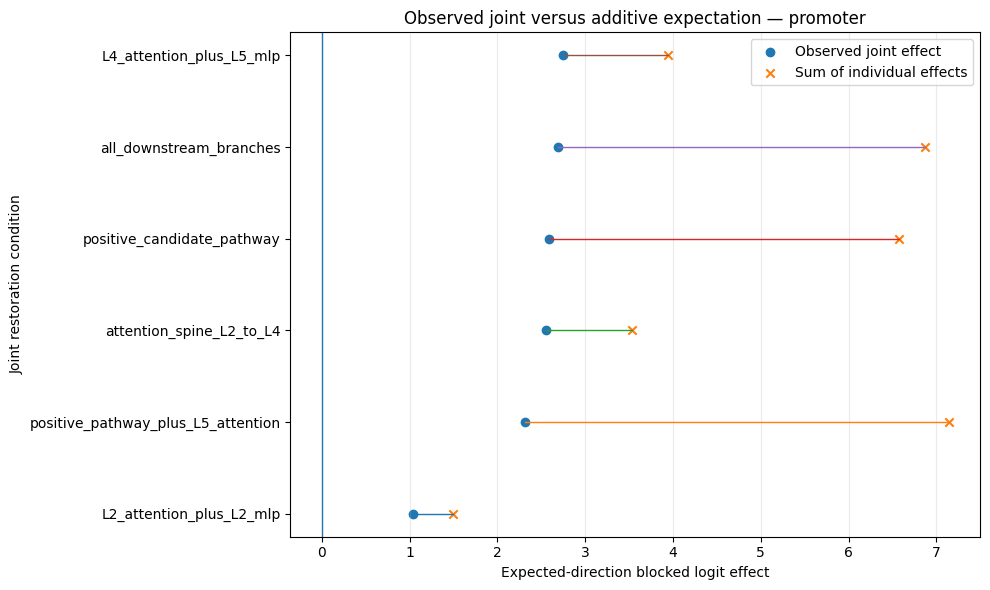

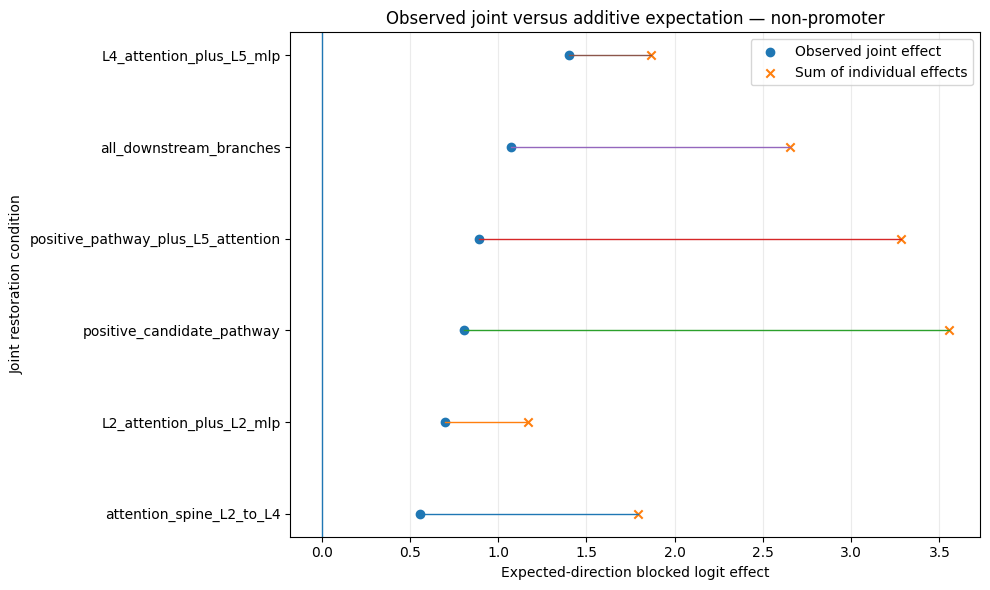


Saved joint-mediation evidence
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/joint_mediation_interaction_results.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/joint_mediation_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/joint_vs_individual_interaction_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/combined_joint_mediation_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/joint_mediation_analysis_metadata.json

Cell 11 complete. Joint mediation, additive expectations, and non-additive interactions have been summarized.


In [24]:
# ============================================================
# Cell 11
# Analyze joint downstream mediation and non-additive
# interaction structure
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

JOINT_BOOTSTRAP_SEED = 44
JOINT_BOOTSTRAP_SAMPLES = 5000

joint_rng = np.random.default_rng(
    JOINT_BOOTSTRAP_SEED
)


# ------------------------------------------------------------
# Individual branch effects indexed by sequence
# ------------------------------------------------------------

individual_branch_table = (
    full_branch_mediation_results.loc[
        full_branch_mediation_results[
            "restored_component"
        ].notna()
    ]
    [
        [
            "source_class",
            "source_index",
            "restored_component",
            "expected_direction_total_effect",
            "expected_direction_blocked_effect",
            "expected_direction_remaining_effect",
        ]
    ]
    .copy()
)


individual_effect_lookup = (
    individual_branch_table.set_index(
        [
            "source_class",
            "source_index",
            "restored_component",
        ]
    )[
        "expected_direction_blocked_effect"
    ]
    .to_dict()
)


# ------------------------------------------------------------
# Add sum of corresponding individual effects to each joint row
# ------------------------------------------------------------

joint_analysis_rows = []


for row in (
    joint_branch_mediation_results.itertuples()
):
    restored_components_text = str(
        row.restored_components
    )

    if (
        restored_components_text == ""
        or restored_components_text == "nan"
    ):
        restored_components = tuple()

    else:
        restored_components = tuple(
            restored_components_text.split(
                "|"
            )
        )


    individual_expected_blocked_effects = []


    for component_name in restored_components:
        lookup_key = (
            str(
                row.source_class
            ),
            int(
                row.source_index
            ),
            component_name,
        )

        if lookup_key not in individual_effect_lookup:
            raise KeyError(
                "Missing individual mediation result for "
                f"{lookup_key}"
            )

        individual_expected_blocked_effects.append(
            float(
                individual_effect_lookup[
                    lookup_key
                ]
            )
        )


    sum_individual_expected_blocked_effects = float(
        np.sum(
            individual_expected_blocked_effects
        )
    )


    joint_expected_blocked_effect = float(
        row.expected_direction_blocked_effect
    )


    interaction_effect = (
        joint_expected_blocked_effect
        - sum_individual_expected_blocked_effects
    )


    expected_total_effect = float(
        row.expected_direction_total_effect
    )


    if abs(
        expected_total_effect
    ) > 1e-8:
        joint_mediation_fraction = (
            joint_expected_blocked_effect
            / expected_total_effect
        )

        additive_expected_fraction = (
            sum_individual_expected_blocked_effects
            / expected_total_effect
        )

        interaction_fraction = (
            interaction_effect
            / expected_total_effect
        )

    else:
        joint_mediation_fraction = np.nan
        additive_expected_fraction = np.nan
        interaction_fraction = np.nan


    joint_analysis_rows.append(
        {
            "source_class": str(
                row.source_class
            ),
            "source_index": int(
                row.source_index
            ),
            "condition_name": str(
                row.condition_name
            ),
            "restored_components": (
                restored_components_text
            ),
            "number_of_restored_components": int(
                row.number_of_restored_components
            ),
            "expected_direction_total_effect": (
                expected_total_effect
            ),
            "joint_expected_blocked_effect": (
                joint_expected_blocked_effect
            ),
            "joint_expected_remaining_effect": float(
                row.expected_direction_remaining_effect
            ),
            "sum_individual_expected_blocked_effects": (
                sum_individual_expected_blocked_effects
            ),
            "interaction_effect": float(
                interaction_effect
            ),
            "joint_mediation_fraction": float(
                joint_mediation_fraction
            ),
            "additive_expected_fraction": float(
                additive_expected_fraction
            ),
            "interaction_fraction": float(
                interaction_fraction
            ),
        }
    )


joint_interaction_results = pd.DataFrame(
    joint_analysis_rows
)


print("=" * 80)
print("Joint interaction analysis input")
print("=" * 80)

print(
    "Rows:",
    len(
        joint_interaction_results
    ),
)

display(
    joint_interaction_results.head(
        20
    )
)


# ------------------------------------------------------------
# Exclude intervention-only from joint-condition summaries
# ------------------------------------------------------------

joint_restoration_results = (
    joint_interaction_results.loc[
        joint_interaction_results[
            "number_of_restored_components"
        ].gt(0)
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


assert len(
    joint_restoration_results
) == 378 * 6


# ------------------------------------------------------------
# Paired bootstrap summary
# ------------------------------------------------------------

def bootstrap_joint_condition(
    table: pd.DataFrame,
) -> dict[str, float]:
    total_effect = table[
        "expected_direction_total_effect"
    ].to_numpy(
        dtype=np.float64
    )

    joint_blocked = table[
        "joint_expected_blocked_effect"
    ].to_numpy(
        dtype=np.float64
    )

    joint_remaining = table[
        "joint_expected_remaining_effect"
    ].to_numpy(
        dtype=np.float64
    )

    summed_individual = table[
        "sum_individual_expected_blocked_effects"
    ].to_numpy(
        dtype=np.float64
    )

    interaction = table[
        "interaction_effect"
    ].to_numpy(
        dtype=np.float64
    )

    n_sequences = len(
        table
    )

    bootstrap_indices = joint_rng.integers(
        low=0,
        high=n_sequences,
        size=(
            JOINT_BOOTSTRAP_SAMPLES,
            n_sequences,
        ),
    )


    bootstrap_total_mean = total_effect[
        bootstrap_indices
    ].mean(
        axis=1
    )

    bootstrap_joint_blocked_mean = joint_blocked[
        bootstrap_indices
    ].mean(
        axis=1
    )

    bootstrap_joint_remaining_mean = joint_remaining[
        bootstrap_indices
    ].mean(
        axis=1
    )

    bootstrap_summed_individual_mean = summed_individual[
        bootstrap_indices
    ].mean(
        axis=1
    )

    bootstrap_interaction_mean = interaction[
        bootstrap_indices
    ].mean(
        axis=1
    )


    valid_denominator = (
        np.abs(
            bootstrap_total_mean
        )
        > 1e-8
    )


    bootstrap_joint_fraction = np.full(
        JOINT_BOOTSTRAP_SAMPLES,
        np.nan,
        dtype=np.float64,
    )

    bootstrap_additive_fraction = np.full(
        JOINT_BOOTSTRAP_SAMPLES,
        np.nan,
        dtype=np.float64,
    )

    bootstrap_interaction_fraction = np.full(
        JOINT_BOOTSTRAP_SAMPLES,
        np.nan,
        dtype=np.float64,
    )


    bootstrap_joint_fraction[
        valid_denominator
    ] = (
        bootstrap_joint_blocked_mean[
            valid_denominator
        ]
        /
        bootstrap_total_mean[
            valid_denominator
        ]
    )

    bootstrap_additive_fraction[
        valid_denominator
    ] = (
        bootstrap_summed_individual_mean[
            valid_denominator
        ]
        /
        bootstrap_total_mean[
            valid_denominator
        ]
    )

    bootstrap_interaction_fraction[
        valid_denominator
    ] = (
        bootstrap_interaction_mean[
            valid_denominator
        ]
        /
        bootstrap_total_mean[
            valid_denominator
        ]
    )


    def interval(
        values: np.ndarray,
    ) -> tuple[float, float]:
        finite_values = values[
            np.isfinite(
                values
            )
        ]

        return (
            float(
                np.quantile(
                    finite_values,
                    0.025,
                )
            ),
            float(
                np.quantile(
                    finite_values,
                    0.975,
                )
            ),
        )


    joint_blocked_ci = interval(
        bootstrap_joint_blocked_mean
    )

    remaining_ci = interval(
        bootstrap_joint_remaining_mean
    )

    interaction_ci = interval(
        bootstrap_interaction_mean
    )

    joint_fraction_ci = interval(
        bootstrap_joint_fraction
    )

    additive_fraction_ci = interval(
        bootstrap_additive_fraction
    )

    interaction_fraction_ci = interval(
        bootstrap_interaction_fraction
    )


    mean_total = float(
        total_effect.mean()
    )

    mean_joint_blocked = float(
        joint_blocked.mean()
    )

    mean_joint_remaining = float(
        joint_remaining.mean()
    )

    mean_summed_individual = float(
        summed_individual.mean()
    )

    mean_interaction = float(
        interaction.mean()
    )


    return {
        "number_of_sequences": int(
            n_sequences
        ),
        "mean_expected_total_effect": (
            mean_total
        ),
        "mean_joint_blocked_effect": (
            mean_joint_blocked
        ),
        "joint_blocked_ci_2.5": (
            joint_blocked_ci[0]
        ),
        "joint_blocked_ci_97.5": (
            joint_blocked_ci[1]
        ),
        "mean_joint_remaining_effect": (
            mean_joint_remaining
        ),
        "remaining_ci_2.5": (
            remaining_ci[0]
        ),
        "remaining_ci_97.5": (
            remaining_ci[1]
        ),
        "mean_sum_individual_blocked_effects": (
            mean_summed_individual
        ),
        "mean_interaction_effect": (
            mean_interaction
        ),
        "interaction_ci_2.5": (
            interaction_ci[0]
        ),
        "interaction_ci_97.5": (
            interaction_ci[1]
        ),
        "joint_mediation_fraction": (
            mean_joint_blocked
            / mean_total
            if abs(
                mean_total
            ) > 1e-8
            else np.nan
        ),
        "joint_fraction_ci_2.5": (
            joint_fraction_ci[0]
        ),
        "joint_fraction_ci_97.5": (
            joint_fraction_ci[1]
        ),
        "additive_expected_fraction": (
            mean_summed_individual
            / mean_total
            if abs(
                mean_total
            ) > 1e-8
            else np.nan
        ),
        "additive_fraction_ci_2.5": (
            additive_fraction_ci[0]
        ),
        "additive_fraction_ci_97.5": (
            additive_fraction_ci[1]
        ),
        "interaction_fraction": (
            mean_interaction
            / mean_total
            if abs(
                mean_total
            ) > 1e-8
            else np.nan
        ),
        "interaction_fraction_ci_2.5": (
            interaction_fraction_ci[0]
        ),
        "interaction_fraction_ci_97.5": (
            interaction_fraction_ci[1]
        ),
        "fraction_sequences_blocking_expected_effect": float(
            np.mean(
                joint_blocked
                > 0
            )
        ),
        "fraction_sequences_near_complete_block": float(
            np.mean(
                table[
                    "joint_mediation_fraction"
                ].to_numpy()
                >= 0.90
            )
        ),
        "fraction_sequences_overcorrecting": float(
            np.mean(
                table[
                    "joint_mediation_fraction"
                ].to_numpy()
                > 1.0
            )
        ),
    }


# ------------------------------------------------------------
# Class-specific summaries
# ------------------------------------------------------------

joint_summary_rows = []


for (
    source_class,
    condition_name,
), condition_table in (
    joint_restoration_results.groupby(
        [
            "source_class",
            "condition_name",
        ],
        sort=True,
    )
):
    condition_components = (
        condition_table[
            "restored_components"
        ].iloc[0]
    )

    statistics = bootstrap_joint_condition(
        condition_table
    )


    joint_summary_rows.append(
        {
            "source_class": (
                source_class
            ),
            "condition_name": (
                condition_name
            ),
            "restored_components": (
                condition_components
            ),
            "number_of_components": int(
                condition_table[
                    "number_of_restored_components"
                ].iloc[0]
            ),
            **statistics,
        }
    )


joint_mediation_summary = pd.DataFrame(
    joint_summary_rows
)


# ------------------------------------------------------------
# Interaction interpretation
# ------------------------------------------------------------

def classify_interaction(
    row: pd.Series,
) -> str:
    lower = float(
        row[
            "interaction_ci_2.5"
        ]
    )

    upper = float(
        row[
            "interaction_ci_97.5"
        ]
    )

    if upper < 0:
        return (
            "sub-additive: overlapping, redundant, "
            "or serial mediation"
        )

    if lower > 0:
        return (
            "super-additive: synergistic joint mediation"
        )

    return (
        "approximately additive or statistically uncertain"
    )


joint_mediation_summary[
    "interaction_interpretation"
] = joint_mediation_summary.apply(
    classify_interaction,
    axis=1,
)


joint_mediation_summary[
    "class_rank"
] = (
    joint_mediation_summary.groupby(
        "source_class"
    )[
        "joint_mediation_fraction"
    ]
    .rank(
        method="dense",
        ascending=False,
    )
    .astype(int)
)


joint_mediation_summary = (
    joint_mediation_summary
    .sort_values(
        [
            "source_class",
            "class_rank",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("Joint mediation summary")
print("=" * 80)

display(
    joint_mediation_summary[
        [
            "source_class",
            "class_rank",
            "condition_name",
            "number_of_components",
            "mean_expected_total_effect",
            "mean_joint_blocked_effect",
            "joint_blocked_ci_2.5",
            "joint_blocked_ci_97.5",
            "joint_mediation_fraction",
            "joint_fraction_ci_2.5",
            "joint_fraction_ci_97.5",
            "mean_joint_remaining_effect",
            "fraction_sequences_blocking_expected_effect",
            "fraction_sequences_near_complete_block",
            "fraction_sequences_overcorrecting",
            "interaction_interpretation",
        ]
    ]
)


# ------------------------------------------------------------
# Interaction comparison table
# ------------------------------------------------------------

interaction_comparison_table = (
    joint_mediation_summary[
        [
            "source_class",
            "condition_name",
            "restored_components",
            "mean_joint_blocked_effect",
            "mean_sum_individual_blocked_effects",
            "mean_interaction_effect",
            "interaction_ci_2.5",
            "interaction_ci_97.5",
            "joint_mediation_fraction",
            "additive_expected_fraction",
            "interaction_fraction",
            "interaction_fraction_ci_2.5",
            "interaction_fraction_ci_97.5",
            "interaction_interpretation",
        ]
    ]
    .copy()
)


print("\n" + "=" * 80)
print("Joint versus summed-individual effects")
print("=" * 80)

display(
    interaction_comparison_table
)


# ------------------------------------------------------------
# Combined-class descriptive summary
# ------------------------------------------------------------

combined_joint_rows = []


for condition_name, condition_table in (
    joint_restoration_results.groupby(
        "condition_name",
        sort=True,
    )
):
    total_effect = condition_table[
        "expected_direction_total_effect"
    ].to_numpy(
        dtype=np.float64
    )

    joint_blocked = condition_table[
        "joint_expected_blocked_effect"
    ].to_numpy(
        dtype=np.float64
    )

    summed_individual = condition_table[
        "sum_individual_expected_blocked_effects"
    ].to_numpy(
        dtype=np.float64
    )

    interaction = condition_table[
        "interaction_effect"
    ].to_numpy(
        dtype=np.float64
    )


    mean_total = float(
        total_effect.mean()
    )

    mean_joint_blocked = float(
        joint_blocked.mean()
    )

    mean_summed_individual = float(
        summed_individual.mean()
    )

    mean_interaction = float(
        interaction.mean()
    )


    combined_joint_rows.append(
        {
            "condition_name": (
                condition_name
            ),
            "restored_components": (
                condition_table[
                    "restored_components"
                ].iloc[0]
            ),
            "number_of_components": int(
                condition_table[
                    "number_of_restored_components"
                ].iloc[0]
            ),
            "number_of_sequences": int(
                len(
                    condition_table
                )
            ),
            "mean_expected_total_effect": (
                mean_total
            ),
            "mean_joint_blocked_effect": (
                mean_joint_blocked
            ),
            "mean_sum_individual_blocked_effects": (
                mean_summed_individual
            ),
            "mean_interaction_effect": (
                mean_interaction
            ),
            "combined_joint_mediation_fraction": (
                mean_joint_blocked
                / mean_total
            ),
            "combined_additive_expected_fraction": (
                mean_summed_individual
                / mean_total
            ),
            "combined_interaction_fraction": (
                mean_interaction
                / mean_total
            ),
            "fraction_sequences_blocking_expected_effect": float(
                np.mean(
                    joint_blocked
                    > 0
                )
            ),
            "fraction_sequences_near_complete_block": float(
                np.mean(
                    condition_table[
                        "joint_mediation_fraction"
                    ].to_numpy()
                    >= 0.90
                )
            ),
        }
    )


combined_joint_summary = pd.DataFrame(
    combined_joint_rows
).sort_values(
    "combined_joint_mediation_fraction",
    ascending=False,
).reset_index(
    drop=True
)


print("\n" + "=" * 80)
print("Combined-class joint mediation ranking")
print("=" * 80)

display(
    combined_joint_summary
)


# ------------------------------------------------------------
# Plot joint mediation fractions by class
# ------------------------------------------------------------

for source_class in [
    "promoter",
    "non-promoter",
]:
    plot_table = (
        joint_mediation_summary.loc[
            joint_mediation_summary[
                "source_class"
            ].eq(
                source_class
            )
        ]
        .sort_values(
            "joint_mediation_fraction",
            ascending=True,
        )
        .reset_index(
            drop=True
        )
    )


    values = plot_table[
        "joint_mediation_fraction"
    ].to_numpy()


    lower_errors = (
        values
        - plot_table[
            "joint_fraction_ci_2.5"
        ].to_numpy()
    )

    upper_errors = (
        plot_table[
            "joint_fraction_ci_97.5"
        ].to_numpy()
        - values
    )


    figure, axis = plt.subplots(
        figsize=(
            10,
            6,
        )
    )


    axis.barh(
        plot_table[
            "condition_name"
        ],
        values,
        xerr=np.vstack(
            [
                lower_errors,
                upper_errors,
            ]
        ),
        capsize=4,
    )


    axis.axvline(
        0.0,
        linewidth=1,
    )

    axis.axvline(
        1.0,
        linewidth=1,
        linestyle="--",
    )


    axis.set_xlabel(
        "Fraction of mean Layer-1 intervention effect blocked"
    )

    axis.set_ylabel(
        "Joint restoration condition"
    )

    axis.set_title(
        f"Joint downstream mediation — {source_class}"
    )

    axis.grid(
        axis="x",
        alpha=0.25,
    )


    figure.tight_layout()


    output_path = (
        NOTEBOOK9_DIR
        / (
            "joint_mediation_fraction_"
            f"{source_class.replace('-', '_')}.png"
        )
    )


    figure.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        figure
    )


# ------------------------------------------------------------
# Plot joint versus additive expected effects
# ------------------------------------------------------------

for source_class in [
    "promoter",
    "non-promoter",
]:
    plot_table = (
        interaction_comparison_table.loc[
            interaction_comparison_table[
                "source_class"
            ].eq(
                source_class
            )
        ]
        .sort_values(
            "joint_mediation_fraction",
            ascending=True,
        )
        .reset_index(
            drop=True
        )
    )


    y_positions = np.arange(
        len(
            plot_table
        )
    )


    figure, axis = plt.subplots(
        figsize=(
            10,
            6,
        )
    )


    axis.scatter(
        plot_table[
            "mean_joint_blocked_effect"
        ],
        y_positions,
        label="Observed joint effect",
    )

    axis.scatter(
        plot_table[
            "mean_sum_individual_blocked_effects"
        ],
        y_positions,
        marker="x",
        label="Sum of individual effects",
    )


    for row_position in y_positions:
        axis.plot(
            [
                plot_table.loc[
                    row_position,
                    "mean_joint_blocked_effect",
                ],
                plot_table.loc[
                    row_position,
                    "mean_sum_individual_blocked_effects",
                ],
            ],
            [
                row_position,
                row_position,
            ],
            linewidth=1,
        )


    axis.set_yticks(
        y_positions
    )

    axis.set_yticklabels(
        plot_table[
            "condition_name"
        ]
    )

    axis.axvline(
        0.0,
        linewidth=1,
    )

    axis.set_xlabel(
        "Expected-direction blocked logit effect"
    )

    axis.set_ylabel(
        "Joint restoration condition"
    )

    axis.set_title(
        f"Observed joint versus additive expectation — "
        f"{source_class}"
    )

    axis.legend()

    axis.grid(
        axis="x",
        alpha=0.25,
    )


    figure.tight_layout()


    output_path = (
        NOTEBOOK9_DIR
        / (
            "joint_vs_additive_"
            f"{source_class.replace('-', '_')}.png"
        )
    )


    figure.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        figure
    )


# ------------------------------------------------------------
# Save evidence
# ------------------------------------------------------------

JOINT_INTERACTION_RESULTS_PATH = (
    NOTEBOOK9_DIR
    / "joint_mediation_interaction_results.csv"
)

JOINT_MEDIATION_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "joint_mediation_summary.csv"
)

INTERACTION_COMPARISON_PATH = (
    NOTEBOOK9_DIR
    / "joint_vs_individual_interaction_summary.csv"
)

COMBINED_JOINT_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "combined_joint_mediation_summary.csv"
)


joint_interaction_results.to_csv(
    JOINT_INTERACTION_RESULTS_PATH,
    index=False,
)

joint_mediation_summary.to_csv(
    JOINT_MEDIATION_SUMMARY_PATH,
    index=False,
)

interaction_comparison_table.to_csv(
    INTERACTION_COMPARISON_PATH,
    index=False,
)

combined_joint_summary.to_csv(
    COMBINED_JOINT_SUMMARY_PATH,
    index=False,
)


joint_analysis_metadata = {
    "bootstrap_seed": (
        JOINT_BOOTSTRAP_SEED
    ),
    "number_of_bootstrap_samples": (
        JOINT_BOOTSTRAP_SAMPLES
    ),
    "interaction_definition": (
        "joint blocked effect minus sum of corresponding "
        "individual blocked effects"
    ),
    "negative_interaction_interpretation": (
        "sub-additivity consistent with overlapping, "
        "redundant, or serial mediation"
    ),
    "positive_interaction_interpretation": (
        "super-additivity consistent with synergy"
    ),
    "important_limitation": (
        "Branch restoration changes downstream inputs, so "
        "interaction terms do not uniquely distinguish serial "
        "causation from representational redundancy."
    ),
}


JOINT_METADATA_PATH = (
    NOTEBOOK9_DIR
    / "joint_mediation_analysis_metadata.json"
)


with open(
    JOINT_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        joint_analysis_metadata,
        file,
        indent=2,
    )


print("\n" + "=" * 80)
print("Saved joint-mediation evidence")
print("=" * 80)

for path in [
    JOINT_INTERACTION_RESULTS_PATH,
    JOINT_MEDIATION_SUMMARY_PATH,
    INTERACTION_COMPARISON_PATH,
    COMBINED_JOINT_SUMMARY_PATH,
    JOINT_METADATA_PATH,
]:
    print(path)


print(
    "\nCell 11 complete. Joint mediation, additive "
    "expectations, and non-additive interactions have "
    "been summarized."
)

In [25]:
# ============================================================
# Cell 12
# Final Notebook 9 evidence table, claims, and limitations
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Extract key propagation evidence
# ------------------------------------------------------------

def get_propagation_characteristic(
    intervention_name: str,
    source_class: str,
) -> pd.Series:
    matching_rows = (
        propagation_characteristics.loc[
            propagation_characteristics[
                "intervention_name"
            ].eq(
                intervention_name
            )
            &
            propagation_characteristics[
                "source_class"
            ].eq(
                source_class
            )
        ]
    )

    if len(matching_rows) != 1:
        raise ValueError(
            "Expected exactly one propagation-characteristic "
            f"row for {intervention_name}, {source_class}."
        )

    return matching_rows.iloc[0]


promoter_propagation = (
    get_propagation_characteristic(
        "promoter_direction_rank1",
        "promoter",
    )
)

nonpromoter_propagation = (
    get_propagation_characteristic(
        "promoter_direction_rank1",
        "non-promoter",
    )
)


# ------------------------------------------------------------
# Extract key individual mediation evidence
# ------------------------------------------------------------

def get_individual_mediation(
    source_class: str,
    component_name: str,
) -> pd.Series:
    matching_rows = (
        branch_mediation_summary.loc[
            branch_mediation_summary[
                "source_class"
            ].eq(
                source_class
            )
            &
            branch_mediation_summary[
                "restored_component"
            ].eq(
                component_name
            )
        ]
    )

    if len(matching_rows) != 1:
        raise ValueError(
            "Expected exactly one individual-mediation row for "
            f"{source_class}, {component_name}."
        )

    return matching_rows.iloc[0]


promoter_l4_attention = (
    get_individual_mediation(
        "promoter",
        "L4_attention",
    )
)

nonpromoter_l4_attention = (
    get_individual_mediation(
        "non-promoter",
        "L4_attention",
    )
)

promoter_l5_mlp = (
    get_individual_mediation(
        "promoter",
        "L5_mlp",
    )
)

nonpromoter_l5_mlp = (
    get_individual_mediation(
        "non-promoter",
        "L5_mlp",
    )
)


# ------------------------------------------------------------
# Extract compact-core joint mediation evidence
# ------------------------------------------------------------

def get_joint_mediation(
    source_class: str,
    condition_name: str,
) -> pd.Series:
    matching_rows = (
        joint_mediation_summary.loc[
            joint_mediation_summary[
                "source_class"
            ].eq(
                source_class
            )
            &
            joint_mediation_summary[
                "condition_name"
            ].eq(
                condition_name
            )
        ]
    )

    if len(matching_rows) != 1:
        raise ValueError(
            "Expected exactly one joint-mediation row for "
            f"{source_class}, {condition_name}."
        )

    return matching_rows.iloc[0]


promoter_core_joint = (
    get_joint_mediation(
        "promoter",
        "L4_attention_plus_L5_mlp",
    )
)

nonpromoter_core_joint = (
    get_joint_mediation(
        "non-promoter",
        "L4_attention_plus_L5_mlp",
    )
)


# ------------------------------------------------------------
# Combined descriptive compact-core evidence
# ------------------------------------------------------------

combined_core_rows = (
    combined_joint_summary.loc[
        combined_joint_summary[
            "condition_name"
        ].eq(
            "L4_attention_plus_L5_mlp"
        )
    ]
)


if len(combined_core_rows) != 1:
    raise ValueError(
        "Could not uniquely resolve the combined compact-core row."
    )


combined_core_joint = (
    combined_core_rows.iloc[0]
)


# ------------------------------------------------------------
# Final Layer-5 logit effects
# ------------------------------------------------------------

def get_layer5_effect(
    source_class: str,
) -> pd.Series:
    matching_rows = (
        layer5_logit_effect_summary.loc[
            layer5_logit_effect_summary[
                "intervention_name"
            ].eq(
                "promoter_direction_rank1"
            )
            &
            layer5_logit_effect_summary[
                "source_class"
            ].eq(
                source_class
            )
        ]
    )

    if len(matching_rows) != 1:
        raise ValueError(
            "Could not uniquely resolve Layer-5 effect for "
            f"{source_class}."
        )

    return matching_rows.iloc[0]


promoter_layer5_effect = (
    get_layer5_effect(
        "promoter"
    )
)

nonpromoter_layer5_effect = (
    get_layer5_effect(
        "non-promoter"
    )
)


# ------------------------------------------------------------
# Construct final evidence table
# ------------------------------------------------------------

final_evidence_rows = [
    {
        "evidence_category": (
            "Layer-1 intervention effect"
        ),
        "source_class": (
            "promoter"
        ),
        "component_or_condition": (
            "promoter_direction_rank1"
        ),
        "estimate": float(
            promoter_layer5_effect[
                "mean_logit_change"
            ]
        ),
        "ci_2.5": float(
            promoter_layer5_effect[
                "ci_2.5"
            ]
        ),
        "ci_97.5": float(
            promoter_layer5_effect[
                "ci_97.5"
            ]
        ),
        "unit": (
            "Layer-5 diagnostic-probe logits"
        ),
        "interpretation": (
            "Moving promoter Layer-1 MLP coordinates toward "
            "the non-promoter mean reduces promoter-associated "
            "diagnostic evidence."
        ),
    },
    {
        "evidence_category": (
            "Layer-1 intervention effect"
        ),
        "source_class": (
            "non-promoter"
        ),
        "component_or_condition": (
            "promoter_direction_rank1"
        ),
        "estimate": float(
            nonpromoter_layer5_effect[
                "mean_logit_change"
            ]
        ),
        "ci_2.5": float(
            nonpromoter_layer5_effect[
                "ci_2.5"
            ]
        ),
        "ci_97.5": float(
            nonpromoter_layer5_effect[
                "ci_97.5"
            ]
        ),
        "unit": (
            "Layer-5 diagnostic-probe logits"
        ),
        "interpretation": (
            "Moving non-promoter Layer-1 MLP coordinates toward "
            "the promoter mean increases promoter-associated "
            "diagnostic evidence."
        ),
    },
    {
        "evidence_category": (
            "Propagation"
        ),
        "source_class": (
            "promoter"
        ),
        "component_or_condition": (
            "maximum perturbation amplification"
        ),
        "estimate": float(
            promoter_propagation[
                "maximum_mean_amplification"
            ]
        ),
        "ci_2.5": np.nan,
        "ci_97.5": np.nan,
        "unit": (
            "times initial Layer-1 shift"
        ),
        "interpretation": (
            f"Maximum mean amplification occurs at Layer "
            f"{int(promoter_propagation['layer_of_maximum_amplification'])}."
        ),
    },
    {
        "evidence_category": (
            "Propagation"
        ),
        "source_class": (
            "non-promoter"
        ),
        "component_or_condition": (
            "maximum perturbation amplification"
        ),
        "estimate": float(
            nonpromoter_propagation[
                "maximum_mean_amplification"
            ]
        ),
        "ci_2.5": np.nan,
        "ci_97.5": np.nan,
        "unit": (
            "times initial Layer-1 shift"
        ),
        "interpretation": (
            f"Maximum mean amplification occurs at Layer "
            f"{int(nonpromoter_propagation['layer_of_maximum_amplification'])}."
        ),
    },
    {
        "evidence_category": (
            "Individual mediation"
        ),
        "source_class": (
            "promoter"
        ),
        "component_or_condition": (
            "L4_attention"
        ),
        "estimate": float(
            promoter_l4_attention[
                "expected_direction_mediation_fraction"
            ]
        ),
        "ci_2.5": float(
            promoter_l4_attention[
                "expected_fraction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            promoter_l4_attention[
                "expected_fraction_ci_97.5"
            ]
        ),
        "unit": (
            "fraction of mean intervention effect blocked"
        ),
        "interpretation": (
            "Layer-4 attention carries a substantial portion "
            "of the promoter intervention-induced difference."
        ),
    },
    {
        "evidence_category": (
            "Individual mediation"
        ),
        "source_class": (
            "non-promoter"
        ),
        "component_or_condition": (
            "L4_attention"
        ),
        "estimate": float(
            nonpromoter_l4_attention[
                "expected_direction_mediation_fraction"
            ]
        ),
        "ci_2.5": float(
            nonpromoter_l4_attention[
                "expected_fraction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            nonpromoter_l4_attention[
                "expected_fraction_ci_97.5"
            ]
        ),
        "unit": (
            "fraction of mean intervention effect blocked"
        ),
        "interpretation": (
            "Layer-4 attention also mediates the insertion of "
            "promoter-associated evidence into non-promoters."
        ),
    },
    {
        "evidence_category": (
            "Individual mediation"
        ),
        "source_class": (
            "promoter"
        ),
        "component_or_condition": (
            "L5_mlp"
        ),
        "estimate": float(
            promoter_l5_mlp[
                "expected_direction_mediation_fraction"
            ]
        ),
        "ci_2.5": float(
            promoter_l5_mlp[
                "expected_fraction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            promoter_l5_mlp[
                "expected_fraction_ci_97.5"
            ]
        ),
        "unit": (
            "fraction of mean intervention effect blocked"
        ),
        "interpretation": (
            "Layer-5 MLP is the strongest individual final "
            "mediator for promoters."
        ),
    },
    {
        "evidence_category": (
            "Individual mediation"
        ),
        "source_class": (
            "non-promoter"
        ),
        "component_or_condition": (
            "L5_mlp"
        ),
        "estimate": float(
            nonpromoter_l5_mlp[
                "expected_direction_mediation_fraction"
            ]
        ),
        "ci_2.5": float(
            nonpromoter_l5_mlp[
                "expected_fraction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            nonpromoter_l5_mlp[
                "expected_fraction_ci_97.5"
            ]
        ),
        "unit": (
            "fraction of mean intervention effect blocked"
        ),
        "interpretation": (
            "Layer-5 MLP is the strongest individual final "
            "mediator for non-promoters."
        ),
    },
    {
        "evidence_category": (
            "Joint compact-core mediation"
        ),
        "source_class": (
            "promoter"
        ),
        "component_or_condition": (
            "L4_attention_plus_L5_mlp"
        ),
        "estimate": float(
            promoter_core_joint[
                "joint_mediation_fraction"
            ]
        ),
        "ci_2.5": float(
            promoter_core_joint[
                "joint_fraction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            promoter_core_joint[
                "joint_fraction_ci_97.5"
            ]
        ),
        "unit": (
            "fraction of mean intervention effect blocked"
        ),
        "interpretation": (
            "Compact downstream pair blocks most of the "
            "recoverable promoter intervention effect."
        ),
    },
    {
        "evidence_category": (
            "Joint compact-core mediation"
        ),
        "source_class": (
            "non-promoter"
        ),
        "component_or_condition": (
            "L4_attention_plus_L5_mlp"
        ),
        "estimate": float(
            nonpromoter_core_joint[
                "joint_mediation_fraction"
            ]
        ),
        "ci_2.5": float(
            nonpromoter_core_joint[
                "joint_fraction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            nonpromoter_core_joint[
                "joint_fraction_ci_97.5"
            ]
        ),
        "unit": (
            "fraction of mean intervention effect blocked"
        ),
        "interpretation": (
            "The same compact pair mediates a similar fraction "
            "of the non-promoter intervention effect."
        ),
    },
    {
        "evidence_category": (
            "Joint interaction"
        ),
        "source_class": (
            "promoter"
        ),
        "component_or_condition": (
            "L4_attention_plus_L5_mlp"
        ),
        "estimate": float(
            promoter_core_joint[
                "mean_interaction_effect"
            ]
        ),
        "ci_2.5": float(
            promoter_core_joint[
                "interaction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            promoter_core_joint[
                "interaction_ci_97.5"
            ]
        ),
        "unit": (
            "expected-direction probe logits"
        ),
        "interpretation": (
            "Negative interaction indicates strongly overlapping, "
            "serial, or redundant mediation."
        ),
    },
    {
        "evidence_category": (
            "Joint interaction"
        ),
        "source_class": (
            "non-promoter"
        ),
        "component_or_condition": (
            "L4_attention_plus_L5_mlp"
        ),
        "estimate": float(
            nonpromoter_core_joint[
                "mean_interaction_effect"
            ]
        ),
        "ci_2.5": float(
            nonpromoter_core_joint[
                "interaction_ci_2.5"
            ]
        ),
        "ci_97.5": float(
            nonpromoter_core_joint[
                "interaction_ci_97.5"
            ]
        ),
        "unit": (
            "expected-direction probe logits"
        ),
        "interpretation": (
            "Negative interaction again indicates overlapping, "
            "serial, or redundant mediation."
        ),
    },
]


notebook9_final_evidence_table = pd.DataFrame(
    final_evidence_rows
)


print("=" * 80)
print("Notebook 9 final evidence table")
print("=" * 80)

display(
    notebook9_final_evidence_table
)


# ------------------------------------------------------------
# Final scientific claims and limitations
# ------------------------------------------------------------

notebook9_claims_and_limitations = {
    "primary_claim": (
        "A low-dimensional promoter-associated intervention at "
        "the Layer-1 MLP propagates through a strongly transforming "
        "and non-additive downstream computation. Layer-4 attention "
        "and the Layer-5 MLP form the most compact validated "
        "downstream core, jointly mediating approximately 69% of "
        "the intervention-induced Layer-5 diagnostic-probe effect "
        "in both promoters and non-promoters."
    ),

    "propagation_claim": (
        "The Layer-1 perturbation is rapidly rotated away from "
        "its original direction while its norm is amplified most "
        "strongly at Layer 4. This is consistent with transformation "
        "rather than simple copying of the upstream representation."
    ),

    "individual_mediation_claim": (
        "The Layer-5 MLP is the strongest individual downstream "
        "mediator. Layer-4 attention, Layer-3 attention, Layer-2 "
        "attention, and the Layer-2 MLP also carry portions of the "
        "intervention-induced diagnostic effect."
    ),

    "interaction_claim": (
        "All tested joint branch restorations are significantly "
        "sub-additive. This is consistent with serial dependence, "
        "overlapping representations, redundancy, or compensation "
        "rather than independent additive branches."
    ),

    "candidate_pathway": [
        "Layer-1 MLP promoter-associated subspace",
        "distributed Layer-2 and Layer-3 transformation",
        "Layer-4 attention",
        "Layer-5 MLP",
        "Layer-5 diagnostic representation",
    ],

    "compact_validated_core": [
        "Layer-4 attention branch",
        "Layer-5 MLP branch",
    ],

    "limitations": [
        (
            "The endpoint is a fixed diagnostic logistic probe "
            "trained on Layer-5 representations, not DNABERT-2's "
            "native masked-language-model output."
        ),
        (
            "Clean restoration creates a hybrid forward pass. It "
            "tests whether a branch transmits the intervention-induced "
            "difference but does not uniquely prove strict serial "
            "causation."
        ),
        (
            "Sub-additive interactions cannot by themselves distinguish "
            "serial computation from redundant or overlapping "
            "representations."
        ),
        (
            "The approximately 31% unblocked mean effect does not imply "
            "one missing component; it may reflect distributed, nonlinear, "
            "or restoration-resistant computation."
        ),
        (
            "Attention branches are localized only at the whole-branch "
            "level in Notebook 9. Individual downstream attention heads "
            "have not yet been causally resolved."
        ),
        (
            "The intervention uses class-conditional coordinate movement "
            "within a learned Layer-1 MLP direction and is not a strict "
            "zero ablation."
        ),
        (
            "Mediation fractions from different components must not be "
            "summed because their effects overlap and interact."
        ),
    ],

    "strongest_joint_condition": {
        "name": (
            "L4_attention_plus_L5_mlp"
        ),
        "promoter_fraction": float(
            promoter_core_joint[
                "joint_mediation_fraction"
            ]
        ),
        "promoter_ci": [
            float(
                promoter_core_joint[
                    "joint_fraction_ci_2.5"
                ]
            ),
            float(
                promoter_core_joint[
                    "joint_fraction_ci_97.5"
                ]
            ),
        ],
        "nonpromoter_fraction": float(
            nonpromoter_core_joint[
                "joint_mediation_fraction"
            ]
        ),
        "nonpromoter_ci": [
            float(
                nonpromoter_core_joint[
                    "joint_fraction_ci_2.5"
                ]
            ),
            float(
                nonpromoter_core_joint[
                    "joint_fraction_ci_97.5"
                ]
            ),
        ],
        "combined_descriptive_fraction": float(
            combined_core_joint[
                "combined_joint_mediation_fraction"
            ]
        ),
    },
}


# ------------------------------------------------------------
# Save final Notebook 9 outputs
# ------------------------------------------------------------

FINAL_EVIDENCE_TABLE_PATH = (
    NOTEBOOK9_DIR
    / "notebook9_final_evidence_table.csv"
)

FINAL_CLAIMS_PATH = (
    NOTEBOOK9_DIR
    / "notebook9_claims_and_limitations.json"
)

FINAL_SUMMARY_PATH = (
    NOTEBOOK9_DIR
    / "notebook9_final_summary.txt"
)


notebook9_final_evidence_table.to_csv(
    FINAL_EVIDENCE_TABLE_PATH,
    index=False,
)


with open(
    FINAL_CLAIMS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        notebook9_claims_and_limitations,
        file,
        indent=2,
    )


summary_lines = [
    "NOTEBOOK 9 — PATHWAY AND MEDIATION VALIDATION",
    "",
    "Primary conclusion:",
    notebook9_claims_and_limitations[
        "primary_claim"
    ],
    "",
    "Candidate pathway:",
    (
        " -> ".join(
            notebook9_claims_and_limitations[
                "candidate_pathway"
            ]
        )
    ),
    "",
    "Compact validated downstream core:",
    (
        " -> ".join(
            notebook9_claims_and_limitations[
                "compact_validated_core"
            ]
        )
    ),
    "",
    (
        "Promoter compact-core mediation: "
        f"{promoter_core_joint['joint_mediation_fraction']:.3f} "
        f"[{promoter_core_joint['joint_fraction_ci_2.5']:.3f}, "
        f"{promoter_core_joint['joint_fraction_ci_97.5']:.3f}]"
    ),
    (
        "Non-promoter compact-core mediation: "
        f"{nonpromoter_core_joint['joint_mediation_fraction']:.3f} "
        f"[{nonpromoter_core_joint['joint_fraction_ci_2.5']:.3f}, "
        f"{nonpromoter_core_joint['joint_fraction_ci_97.5']:.3f}]"
    ),
    "",
    "Key limitation:",
    (
        "These results concern promoter-associated information "
        "measured by a fixed Layer-5 diagnostic probe; they do not "
        "establish a complete native DNABERT-2 promoter-classification "
        "circuit."
    ),
]


with open(
    FINAL_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:
    file.write(
        "\n".join(
            summary_lines
        )
    )


print("\n" + "=" * 80)
print("Final Notebook 9 claim")
print("=" * 80)

print(
    notebook9_claims_and_limitations[
        "primary_claim"
    ]
)


print("\nSaved:")

for path in [
    FINAL_EVIDENCE_TABLE_PATH,
    FINAL_CLAIMS_PATH,
    FINAL_SUMMARY_PATH,
]:
    print(path)


print(
    "\nCell 12 complete. Notebook 9 pathway and mediation "
    "validation is finalized."
)

Notebook 9 final evidence table


,evidence_category,source_class,component_or_condition,estimate,ci_2.5,ci_97.5,unit,interpretation
0,Layer-1 intervention effect,promoter,promoter_direction_rank1,-3.937716,-4.816397,-3.132358,Layer-5 diagnostic-probe logits,Moving promoter Layer-1 MLP coordinates toward the non-promoter mean reduces promoter-associated diagnostic evidence.
1,Layer-1 intervention effect,non-promoter,promoter_direction_rank1,2.035187,1.815483,2.256170,Layer-5 diagnostic-probe logits,Moving non-promoter Layer-1 MLP coordinates toward the promoter mean increases promoter-associated diagnostic evidence.
2,Propagation,promoter,maximum perturbation amplification,2.169189,NaN,NaN,times initial Layer-1 shift,Maximum mean amplification occurs at Layer 4.
3,Propagation,non-promoter,maximum perturbation amplification,1.779695,NaN,NaN,times initial Layer-1 shift,Maximum mean amplification occurs at Layer 4.
4,Individual mediation,promoter,L4_attention,0.476321,0.429245,0.521378,fraction of mean intervention effect blocked,Layer-4 attention carries a substantial portion of the promoter intervention-induced difference.
5,Individual mediation,non-promoter,L4_attention,0.297920,0.242695,0.347756,fraction of mean intervention effect blocked,Layer-4 attention also mediates the insertion of promoter-associated evidence into non-promoters.
6,Individual mediation,promoter,L5_mlp,0.525011,0.427644,0.627513,fraction of mean intervention effect blocked,Layer-5 MLP is the strongest individual final mediator for promoters.
7,Individual mediation,non-promoter,L5_mlp,0.619859,0.531792,0.709216,fraction of mean intervention effect blocked,Layer-5 MLP is the strongest individual final mediator for non-promoters.
8,Joint compact-core mediation,promoter,L4_attention_plus_L5_mlp,0.696539,0.645952,0.747910,fraction of mean intervention effect blocked,Compact downstream pair blocks most of the recoverable promoter intervention effect.
9,Joint compact-core mediation,non-promoter,L4_attention_plus_L5_mlp,0.689167,0.635131,0.744068,fraction of mean intervention effect blocked,The same compact pair mediates a similar fraction of the non-promoter intervention effect.



Final Notebook 9 claim
A low-dimensional promoter-associated intervention at the Layer-1 MLP propagates through a strongly transforming and non-additive downstream computation. Layer-4 attention and the Layer-5 MLP form the most compact validated downstream core, jointly mediating approximately 69% of the intervention-induced Layer-5 diagnostic-probe effect in both promoters and non-promoters.

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/notebook9_final_evidence_table.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/notebook9_claims_and_limitations.json
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_pathway_mediation_validation/notebook9_final_summary.txt

Cell 12 complete. Notebook 9 pathway and mediation validation is finalized.
